# Análisis de telemetría robótica y detección de anomalías con inteligencia artificial

**Maestría:** Inteligencia Artificial Aplicada  
**Asignatura:** Herramientas para Inteligencia Artificial  
**Institución:** Universidad Técnica Particular de Loja (UTPL)  
**Estudiante:** Jaime Enrique Villegas Medina  
**Plataforma:** Google Colab

## 1. Introducción

Este proyecto desarrolla un procedimiento de adquisición, procesamiento, almacenamiento, análisis y visualización de datos operativos de un robot cuadrúpedo Unitree Go1.

Se utilizan datos experimentales del dataset público Leg-KILO, originalmente almacenados en formato ROS bag. Mediante Python se extrae información de los estados articulares, incluyendo posición angular, velocidad angular, torque estimado y temperatura.

El proyecto integra 30 000 registros de telemetría en formato CSV con información descriptiva de las articulaciones almacenada en una base de datos SQLite.

Para el procesamiento de información se utiliza Pandas y para la visualización se emplean Matplotlib y Bokeh.

### Objetivo general

Desarrollar y evaluar un flujo de procesamiento, integración, visualización y detección de anomalías en telemetría robótica mediante bibliotecas de Python, combinando el análisis exploratorio del Unitree Go1 y la evaluación cuantitativa etiquetada sobre voraus-AD.

### Objetivos específicos

1. Procesar información experimental de las articulaciones del robot a partir de archivos ROS bag.
2. Construir y consultar una base de datos relacional SQLite.
3. Integrar información procedente de archivos CSV y tablas SQL mediante Pandas.
4. Analizar y visualizar el comportamiento de las variables articulares utilizando Matplotlib y Bokeh.
5. Generar un dataset procesado que pueda servir como punto de partida para futuros modelos de aprendizaje automático.

**Alcance actualizado:** el experimento Unitree Go1 utiliza datos sin etiquetas verificadas de fallas; el experimento voraus-AD incorpora etiquetas para evaluar modelos mediante métricas de clasificación. Los resultados no constituyen un diagnóstico de averías físicas en el cuadrúpedo.


## 2. Herramientas y librerías utilizadas

El proyecto utiliza Python para procesar la telemetría del
Unitree Go1 y gestionar las operaciones de análisis de datos.

- Pandas: manipulación y análisis de datos.
- NumPy: operaciones numéricas.
- SQLite: almacenamiento y consultas SQL.
- Matplotlib: visualizaciones estadísticas.
- Bokeh: visualizaciones interactivas.
- Google Colab: entorno colaborativo de ejecución.

In [1]:
!pip install bokeh

In [2]:
# Librerías para manipulación de datos
import pandas as pd
import numpy as np

# Base de datos
import sqlite3

# Visualización estática
import matplotlib.pyplot as plt

# Visualización interactiva
from bokeh.plotting import figure, show
from bokeh.models import ColumnDataSource, HoverTool
from bokeh.io import output_notebook

# Administración de archivos
from pathlib import Path

# Habilitar Bokeh en Colab
output_notebook()

print("Librerías importadas correctamente")

Librerías importadas correctamente


## 3. Configuración y carga de datos

El notebook permite ejecutar el proyecto de dos maneras:

- Modo completo: lectura del archivo ROS bag original.
- Modo rápido: lectura del CSV previamente procesado.

Ambas modalidades utilizan mediciones reales del Unitree Go1
y generan posteriormente los archivos SQL, la base de datos
SQLite y las visualizaciones.

In [3]:
# Configuración de ejecución
# Opciones disponibles: "CSV" o "ROS"

MODO_EJECUCION = "CSV"

# Cantidad de instantes que seleccionaremos
CANTIDAD_INSTANTES = 2500

# Cantidad de motores articulares
CANTIDAD_MOTORES = 12

print("Modo seleccionado:", MODO_EJECUCION)
print("Registros esperados:",
      CANTIDAD_INSTANTES * CANTIDAD_MOTORES)

Modo seleccionado: CSV
Registros esperados: 30000


In [4]:
from google.colab import files
from pathlib import Path

if MODO_EJECUCION == "CSV":
    archivo_entrada = "unitree_go1_telemetria_30000.csv"

elif MODO_EJECUCION == "ROS":
    archivo_entrada = "running.bag"

else:
    raise ValueError("Modo no válido. Utiliza CSV o ROS.")

if not Path(archivo_entrada).exists():
    print("Selecciona el archivo:", archivo_entrada)
    archivos_subidos = files.upload()
else:
    print("Archivo ya disponible:", archivo_entrada)

if not Path(archivo_entrada).exists():
    raise FileNotFoundError(
        f"No se encontró el archivo {archivo_entrada}"
    )

print("Archivo de entrada verificado correctamente")

Selecciona el archivo: unitree_go1_telemetria_30000.csv


Saving unitree_go1_telemetria_30000.csv to unitree_go1_telemetria_30000.csv
Archivo de entrada verificado correctamente


## 4. Preparación y validación del dataset

En esta etapa se preparan las mediciones articulares del
robot Unitree Go1.

El proyecto dispone de dos modalidades de ejecución:

- CSV: utiliza las 30 000 mediciones previamente extraídas.
- ROS: extrae las mediciones originales desde running.bag.

Ambas modalidades generan un DataFrame con la misma
estructura para continuar con la construcción de SQLite,
el análisis estadístico y las visualizaciones.

In [5]:
# Preparación del dataset según el modo seleccionado

if MODO_EJECUCION == "CSV":

    df_telemetria = pd.read_csv(
        "unitree_go1_telemetria_30000.csv"
    )

    print("Dataset CSV cargado correctamente")

    print("Dimensiones:", df_telemetria.shape)

    display(df_telemetria.head())

else:
    print("Modo ROS seleccionado")
    print("La extracción se ejecutará en la siguiente sección")

Dataset CSV cargado correctamente
Dimensiones: (30000, 9)


,instante,tiempo_ros,motor_id,posicion_rad,velocidad_rad_s,torque_Nm,temperatura_C,tiempo_relativo_s,sesion
0,0,1.694525e+09,0,0.119293,0.000840,0.714844,54,0.0,running
1,0,1.694525e+09,1,0.825305,-0.000278,0.863281,54,0.0,running
2,0,1.694525e+09,2,-1.713426,-0.007499,5.488281,64,0.0,running
3,0,1.694525e+09,3,-0.075997,0.008949,-0.839844,50,0.0,running
4,0,1.694525e+09,4,0.831845,-0.000513,0.738281,54,0.0,running


In [6]:
if MODO_EJECUCION == "CSV":

    columnas_necesarias = [
        "instante",
        "tiempo_ros",
        "motor_id",
        "posicion_rad",
        "velocidad_rad_s",
        "torque_Nm",
        "temperatura_C",
        "tiempo_relativo_s",
        "sesion"
    ]

    columnas_faltantes = [
        columna for columna in columnas_necesarias
        if columna not in df_telemetria.columns
    ]

    assert len(columnas_faltantes) == 0, (
        f"Faltan columnas: {columnas_faltantes}"
    )

    assert len(df_telemetria) == 30000, (
        "El dataset no contiene 30000 registros"
    )

    assert df_telemetria.isnull().sum().sum() == 0, (
        "El dataset contiene valores faltantes"
    )

    print("Dataset validado correctamente")
    print("Registros:", len(df_telemetria))
    print("Motores:", df_telemetria["motor_id"].nunique())
    print("Instantes:", df_telemetria["instante"].nunique())

Dataset validado correctamente
Registros: 30000
Motores: 12
Instantes: 2500


In [7]:
# Instalar rosbags solamente en modo ROS
if MODO_EJECUCION == "ROS":
    import subprocess
    import sys

    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "rosbags"
    ])

    print("Biblioteca rosbags disponible")

In [8]:
if MODO_EJECUCION == "ROS":

    from rosbags.highlevel import AnyReader

    ruta_ros = Path("running.bag")

    registros_ros = []

    with AnyReader([ruta_ros]) as lector:

        canales = [
            c for c in lector.connections
            if c.topic == "/high_state"
        ]

        for instante, (canal, tiempo, datos) in enumerate(
            lector.messages(connections=canales)
        ):

            mensaje_ros = lector.deserialize(
                datos, canal.msgtype
            )

            for motor_id, motor in enumerate(
                mensaje_ros.motorState[:CANTIDAD_MOTORES]
            ):

                registros_ros.append({
                    "instante": instante,
                    "tiempo_ros": tiempo / 1e9,
                    "motor_id": motor_id,
                    "posicion_rad": motor.q,
                    "velocidad_rad_s": motor.dq,
                    "torque_Nm": motor.tauEst,
                    "temperatura_C": motor.temperature
                })

    df_ros = pd.DataFrame(registros_ros)

    print("Extracción ROS completada")
    print("Dimensiones:", df_ros.shape)

In [9]:
if MODO_EJECUCION == "ROS":

    instantes = np.sort(
        df_ros["instante"].unique()
    )

    indices = np.linspace(
        0,
        len(instantes) - 1,
        CANTIDAD_INSTANTES,
        dtype=int
    )

    seleccionados = instantes[indices]

    df_telemetria = df_ros[
        df_ros["instante"].isin(seleccionados)
    ].copy()

    df_telemetria["tiempo_relativo_s"] = (
        df_telemetria["tiempo_ros"]
        - df_telemetria["tiempo_ros"].min()
    )

    df_telemetria["sesion"] = "running"

    df_telemetria.to_csv(
        "unitree_go1_telemetria_30000.csv",
        index=False
    )

    print("Dataset ROS procesado")
    print("Dimensiones:", df_telemetria.shape)

In [10]:
# Validación común para ambas modalidades

print("Modo:", MODO_EJECUCION)
print("Dimensiones:", df_telemetria.shape)

assert len(df_telemetria) == 30000
assert df_telemetria["motor_id"].nunique() == 12
assert df_telemetria["instante"].nunique() == 2500

print("Preparación de datos completada")

Modo: CSV
Dimensiones: (30000, 9)
Preparación de datos completada


## 5. Generación automática de archivos SQL

En esta sección se generan los scripts necesarios para
construir la base de datos relacional del Unitree Go1.

La base de datos contiene dos entidades:

- **Motores:** información descriptiva de las 12 articulaciones.
- **Mediciones:** registros experimentales de telemetría.

Los scripts SQL se generan mediante Python y permiten
reconstruir la base de datos sin depender de una base
previamente creada.

In [11]:
# Definir la estructura de la base de datos

sql_creacion = """
PRAGMA foreign_keys = ON;

CREATE TABLE motores (
    motor_id INTEGER PRIMARY KEY,
    pata TEXT NOT NULL,
    articulacion TEXT NOT NULL
);

CREATE TABLE mediciones (
    medicion_id INTEGER PRIMARY KEY AUTOINCREMENT,
    motor_id INTEGER NOT NULL,
    instante INTEGER NOT NULL,
    tiempo_ros REAL NOT NULL,
    tiempo_relativo_s REAL NOT NULL,
    posicion_rad REAL NOT NULL,
    velocidad_rad_s REAL NOT NULL,
    torque_Nm REAL NOT NULL,
    temperatura_C INTEGER NOT NULL,
    sesion TEXT NOT NULL,

    FOREIGN KEY (motor_id)
        REFERENCES motores(motor_id),

    UNIQUE (sesion, instante, motor_id)
);
"""

print("Estructura SQL definida correctamente")

Estructura SQL definida correctamente


In [12]:
# Guardar las instrucciones en un archivo SQL

with open("crear_base_datos.sql", "w", encoding="utf-8") as archivo:
    archivo.write(sql_creacion)

print("Archivo crear_base_datos.sql generado correctamente")

Archivo crear_base_datos.sql generado correctamente


In [13]:
from pathlib import Path

ruta_sql = Path("crear_base_datos.sql")

print("Archivo existe:", ruta_sql.exists())
print("Tamaño en bytes:", ruta_sql.stat().st_size)

with open(ruta_sql, "r", encoding="utf-8") as archivo:
    print(archivo.read())

Archivo existe: True
Tamaño en bytes: 618

PRAGMA foreign_keys = ON;

CREATE TABLE motores (
    motor_id INTEGER PRIMARY KEY,
    pata TEXT NOT NULL,
    articulacion TEXT NOT NULL
);

CREATE TABLE mediciones (
    medicion_id INTEGER PRIMARY KEY AUTOINCREMENT,
    motor_id INTEGER NOT NULL,
    instante INTEGER NOT NULL,
    tiempo_ros REAL NOT NULL,
    tiempo_relativo_s REAL NOT NULL,
    posicion_rad REAL NOT NULL,
    velocidad_rad_s REAL NOT NULL,
    torque_Nm REAL NOT NULL,
    temperatura_C INTEGER NOT NULL,
    sesion TEXT NOT NULL,

    FOREIGN KEY (motor_id)
        REFERENCES motores(motor_id),

    UNIQUE (sesion, instante, motor_id)
);



### 5.1. Catálogo de motores del Unitree Go1

El robot cuadrúpedo Unitree Go1 dispone de 12 articulaciones
motorizadas, distribuidas en cuatro patas.

Cada pata contiene tres articulaciones: cadera lateral,
muslo y rodilla.

El catálogo permite relacionar las mediciones experimentales
con su ubicación física en el robot.

In [14]:
# Catálogo de las 12 articulaciones del Unitree Go1

datos_motores = [
    (0, "Delantera derecha", "Cadera lateral"),
    (1, "Delantera derecha", "Muslo"),
    (2, "Delantera derecha", "Rodilla"),

    (3, "Delantera izquierda", "Cadera lateral"),
    (4, "Delantera izquierda", "Muslo"),
    (5, "Delantera izquierda", "Rodilla"),

    (6, "Trasera derecha", "Cadera lateral"),
    (7, "Trasera derecha", "Muslo"),
    (8, "Trasera derecha", "Rodilla"),

    (9, "Trasera izquierda", "Cadera lateral"),
    (10, "Trasera izquierda", "Muslo"),
    (11, "Trasera izquierda", "Rodilla")
]

df_catalogo_motores = pd.DataFrame(
    datos_motores,
    columns=["motor_id", "pata", "articulacion"]
)

display(df_catalogo_motores)

print("Total de motores:", len(df_catalogo_motores))

,motor_id,pata,articulacion
0,0,Delantera derecha,Cadera lateral
1,1,Delantera derecha,Muslo
2,2,Delantera derecha,Rodilla
3,3,Delantera izquierda,Cadera lateral
4,4,Delantera izquierda,Muslo
5,5,Delantera izquierda,Rodilla
6,6,Trasera derecha,Cadera lateral
7,7,Trasera derecha,Muslo
8,8,Trasera derecha,Rodilla
9,9,Trasera izquierda,Cadera lateral


Total de motores: 12


In [15]:
columnas_sql = [
    "motor_id",
    "instante",
    "tiempo_ros",
    "tiempo_relativo_s",
    "posicion_rad",
    "velocidad_rad_s",
    "torque_Nm",
    "temperatura_C",
    "sesion"
]

df_insercion = df_telemetria[columnas_sql].copy()

# Validación de los registros
assert len(df_insercion) == 30000
assert df_insercion.isnull().sum().sum() == 0

assert not df_insercion.duplicated(
    subset=["sesion", "instante", "motor_id"]
).any(), "Existen claves de medición duplicadas"

print("Datos preparados para SQL")
print("Dimensiones:", df_insercion.shape)

Datos preparados para SQL
Dimensiones: (30000, 9)


In [16]:
import sqlite3

# Crear una base temporal únicamente en memoria
conexion_temporal = sqlite3.connect(":memory:")

# Crear las tablas usando el SQL generado en el Paso 36
conexion_temporal.executescript(sql_creacion)

# Insertar primero el catálogo de motores
df_catalogo_motores.to_sql(
    "motores",
    conexion_temporal,
    if_exists="append",
    index=False
)

# Insertar después las 30 000 mediciones
df_insercion.to_sql(
    "mediciones",
    conexion_temporal,
    if_exists="append",
    index=False,
    chunksize=1000
)

print("Base temporal preparada correctamente")

Base temporal preparada correctamente


In [17]:
# Obtener las instrucciones de inserción
instrucciones = list(conexion_temporal.iterdump())

# Separar registros por tabla
insert_motores = [
    linea for linea in instrucciones
    if linea.startswith('INSERT INTO "motores"')
]

insert_mediciones = [
    linea for linea in instrucciones
    if linea.startswith('INSERT INTO "mediciones"')
]

# Generar archivo SQL
with open("insertar_datos.sql", "w", encoding="utf-8") as archivo:

    archivo.write("BEGIN TRANSACTION;\n\n")

    archivo.write("-- Catalogo de motores\n")

    for instruccion in insert_motores:
        archivo.write(instruccion + "\n")

    archivo.write("\n-- Mediciones de telemetria\n")

    for instruccion in insert_mediciones:
        archivo.write(instruccion + "\n")

    archivo.write("\nCOMMIT;\n")

conexion_temporal.close()

print("Archivo insertar_datos.sql generado")

Archivo insertar_datos.sql generado


In [18]:
with open("insertar_datos.sql", "r", encoding="utf-8") as archivo:
    lineas = archivo.readlines()

inserciones = [
    linea for linea in lineas
    if linea.startswith("INSERT INTO")
]

print("Total de instrucciones INSERT:", len(inserciones))
print("Motores:", len(insert_motores))
print("Mediciones:", len(insert_mediciones))

print("\nPrimeras instrucciones:")
for linea in inserciones[:3]:
    print(linea.strip())

Total de instrucciones INSERT: 30012
Motores: 12
Mediciones: 30000

Primeras instrucciones:
INSERT INTO "motores" VALUES(0,'Delantera derecha','Cadera lateral');
INSERT INTO "motores" VALUES(1,'Delantera derecha','Muslo');
INSERT INTO "motores" VALUES(2,'Delantera derecha','Rodilla');


## 6. Construcción y validación de la base de datos SQLite

En esta etapa se construye automáticamente una base de datos
SQLite a partir de los archivos SQL generados previamente.

La base de datos está compuesta por dos tablas relacionadas:

- **motores:** almacena la identificación y descripción de las
  12 articulaciones motorizadas del Unitree Go1.
- **mediciones:** almacena los 30 000 registros experimentales
  de posición, velocidad, torque estimado y temperatura.

La integridad de la base se verifica mediante consultas SQL,
comprobación de claves foráneas y validación del número de
registros almacenados.

In [19]:
import sqlite3
from pathlib import Path

# Nombre de la base generada para esta ejecución
nombre_bd = "unitree_go1_generada.db"
ruta_bd = Path(nombre_bd)

# Cerrar una conexión anterior, si existe
if "conexion_bd" in globals():
    conexion_bd.close()

# Eliminar exclusivamente la base de salida generada
# por este notebook para permitir su reconstrucción
if ruta_bd.exists():
    ruta_bd.unlink()

# Crear nuevamente la base
conexion_bd = sqlite3.connect(nombre_bd)

# Activar integridad referencial
conexion_bd.execute("PRAGMA foreign_keys = ON;")

print("Base SQLite preparada:", nombre_bd)

Base SQLite preparada: unitree_go1_generada.db


In [20]:
# Ejecutar el script de creación
with open("crear_base_datos.sql", "r", encoding="utf-8") as archivo:
    script_creacion = archivo.read()

conexion_bd.executescript(script_creacion)

print("Tablas creadas correctamente")

# Ejecutar el script de inserción
with open("insertar_datos.sql", "r", encoding="utf-8") as archivo:
    script_insercion = archivo.read()

conexion_bd.executescript(script_insercion)

print("Registros insertados correctamente")

Tablas creadas correctamente
Registros insertados correctamente


In [21]:
consulta_conteo = """
SELECT
    'Motores' AS tabla,
    COUNT(*) AS registros
FROM motores

UNION ALL

SELECT
    'Mediciones' AS tabla,
    COUNT(*) AS registros
FROM mediciones;
"""

df_conteo = pd.read_sql_query(
    consulta_conteo,
    conexion_bd
)

display(df_conteo)

,tabla,registros
0,Motores,12
1,Mediciones,30000


In [22]:
# Verificar la integridad general
integridad = conexion_bd.execute(
    "PRAGMA integrity_check;"
).fetchone()

# Comprobar las relaciones entre tablas
claves_foraneas = conexion_bd.execute(
    "PRAGMA foreign_key_check;"
).fetchall()

# Verificar cantidad de motores
total_motores = conexion_bd.execute(
    "SELECT COUNT(*) FROM motores;"
).fetchone()[0]

# Verificar cantidad de mediciones
total_mediciones = conexion_bd.execute(
    "SELECT COUNT(*) FROM mediciones;"
).fetchone()[0]

print("Integridad general:", integridad)
print("Errores de claves foráneas:", claves_foraneas)
print("Motores:", total_motores)
print("Mediciones:", total_mediciones)

assert integridad == ("ok",)
assert claves_foraneas == []
assert total_motores == 12
assert total_mediciones == 30000

print("\nBASE DE DATOS VALIDADA CORRECTAMENTE")

Integridad general: ('ok',)
Errores de claves foráneas: []
Motores: 12
Mediciones: 30000

BASE DE DATOS VALIDADA CORRECTAMENTE


## 7. Consultas SQL y análisis mediante Pandas

En esta sección se realizan consultas sobre la base de datos
SQLite del robot cuadrúpedo Unitree Go1.

Se utilizan las siguientes entidades:

- **motores:** identificación de patas y articulaciones.
- **mediciones:** registros de posición angular, velocidad,
  torque estimado y temperatura.

Las consultas permiten relacionar ambas entidades mediante
JOIN y realizar cálculos estadísticos utilizando SQL.

Los resultados se recuperan como DataFrames de Pandas
para su posterior análisis y visualización.

In [23]:
consulta_integracion = """
SELECT
    d.sesion,
    d.instante,
    d.tiempo_relativo_s,
    d.motor_id,
    m.pata,
    m.articulacion,
    d.posicion_rad,
    d.velocidad_rad_s,
    d.torque_Nm,
    d.temperatura_C

FROM mediciones AS d

INNER JOIN motores AS m
    ON d.motor_id = m.motor_id

ORDER BY d.instante, d.motor_id;
"""

df_consulta_integrada = pd.read_sql_query(
    consulta_integracion,
    conexion_bd
)

print("Dimensiones:", df_consulta_integrada.shape)

display(df_consulta_integrada.head(12))

Dimensiones: (30000, 10)


,sesion,instante,tiempo_relativo_s,motor_id,pata,articulacion,posicion_rad,velocidad_rad_s,torque_Nm,temperatura_C
0,running,0,0.0,0,Delantera derecha,Cadera lateral,0.119293,0.000840,0.714844,54
1,running,0,0.0,1,Delantera derecha,Muslo,0.825305,-0.000278,0.863281,54
2,running,0,0.0,2,Delantera derecha,Rodilla,-1.713426,-0.007499,5.488281,64
3,running,0,0.0,3,Delantera izquierda,Cadera lateral,-0.075997,0.008949,-0.839844,50
4,running,0,0.0,4,Delantera izquierda,Muslo,0.831845,-0.000513,0.738281,54
5,running,0,0.0,5,Delantera izquierda,Rodilla,-1.683431,0.001599,4.375000,61
6,running,0,0.0,6,Trasera derecha,Cadera lateral,0.045235,-0.000050,1.406250,52
7,running,0,0.0,7,Trasera derecha,Muslo,0.815071,0.002106,0.691406,56
8,running,0,0.0,8,Trasera derecha,Rodilla,-1.662923,-0.000185,6.195312,65
9,running,0,0.0,9,Trasera izquierda,Cadera lateral,-0.022042,-0.015521,-2.027344,51


In [24]:
consulta_estadisticas = """
SELECT
    m.articulacion,

    COUNT(*) AS cantidad_mediciones,

    ROUND(
        AVG(ABS(d.torque_Nm)), 3
    ) AS torque_promedio_Nm,

    ROUND(
        MAX(ABS(d.torque_Nm)), 3
    ) AS torque_maximo_Nm,

    ROUND(
        AVG(d.temperatura_C), 2
    ) AS temperatura_promedio_C

FROM mediciones AS d

INNER JOIN motores AS m
    ON d.motor_id = m.motor_id

GROUP BY m.articulacion

ORDER BY torque_promedio_Nm DESC;
"""

df_estadisticas = pd.read_sql_query(
    consulta_estadisticas,
    conexion_bd
)

display(df_estadisticas)

,articulacion,cantidad_mediciones,torque_promedio_Nm,torque_maximo_Nm,temperatura_promedio_C
0,Rodilla,10000,7.485,21.520,62.75
1,Muslo,10000,3.526,19.367,54.49
2,Cadera lateral,10000,2.019,10.414,51.75


In [25]:
consulta_patas = """
SELECT
    m.pata,

    COUNT(*) AS cantidad_mediciones,

    ROUND(
        AVG(ABS(d.torque_Nm)), 3
    ) AS torque_promedio_Nm,

    ROUND(
        MAX(ABS(d.torque_Nm)), 3
    ) AS torque_maximo_Nm,

    ROUND(
        AVG(d.temperatura_C), 2
    ) AS temperatura_promedio_C

FROM mediciones AS d

INNER JOIN motores AS m
    ON d.motor_id = m.motor_id

GROUP BY m.pata

ORDER BY torque_promedio_Nm DESC;
"""

df_patas = pd.read_sql_query(
    consulta_patas,
    conexion_bd
)

display(df_patas)

,pata,cantidad_mediciones,torque_promedio_Nm,torque_maximo_Nm,temperatura_promedio_C
0,Trasera derecha,7500,4.774,21.520,57.67
1,Trasera izquierda,7500,4.298,18.355,55.33
2,Delantera izquierda,7500,4.203,19.852,55.00
3,Delantera derecha,7500,4.100,19.777,57.32


In [26]:
# Validación de integración
assert len(df_consulta_integrada) == 30000

# Validación del número de articulaciones
assert len(df_estadisticas) == 3

# Validación del número de patas
assert len(df_patas) == 4

# Validación de mediciones por pata
assert (df_patas["cantidad_mediciones"] == 7500).all()

# Verificar que no haya datos faltantes en la integración
assert df_consulta_integrada.isnull().sum().sum() == 0

print("CONSULTAS SQL VALIDADAS CORRECTAMENTE")

CONSULTAS SQL VALIDADAS CORRECTAMENTE


## 8. Análisis y visualización de la telemetría

En esta sección se presentan visualizaciones de los datos
experimentales del robot Unitree Go1.

Se utilizan Matplotlib y Bokeh para analizar la evolución
temporal de las variables articulares y comparar las
magnitudes de torque estimado entre las articulaciones.

Las visualizaciones permiten identificar patrones de
movimiento y diferencias operativas, sin asumir que estos
resultados constituyen por sí mismos un diagnóstico
de fallas mecánicas.

### 8.1. Evolución temporal de la posición angular

Se analiza la posición angular del motor 1, correspondiente
al muslo de la pata delantera derecha.

La gráfica permite observar los cambios de posición
durante la sesión experimental de movimiento del robot.

La posición angular se expresa en radianes y el tiempo
relativo en segundos.

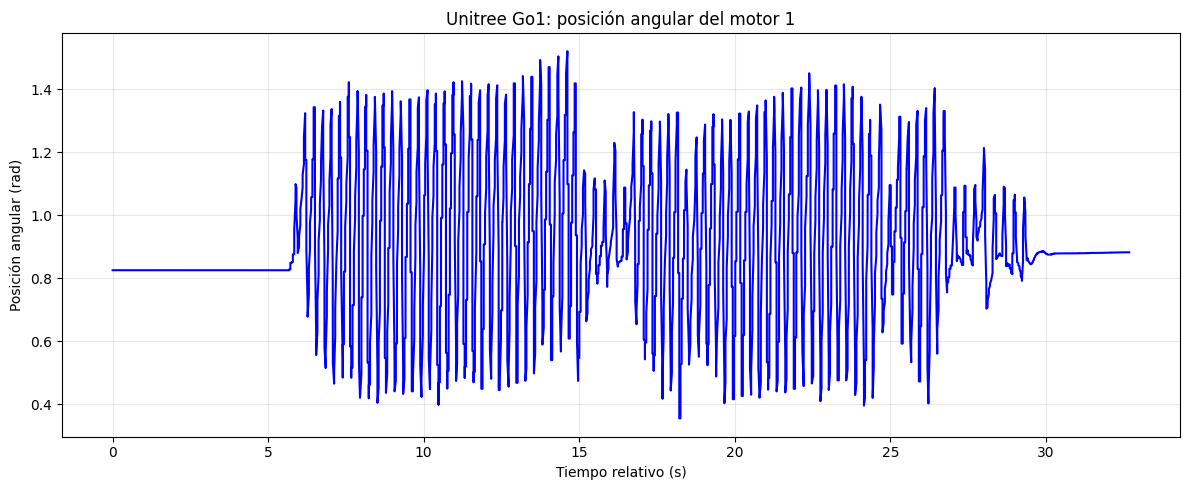

In [27]:
# Seleccionar los registros del motor 1
df_motor1 = df_consulta_integrada[
    df_consulta_integrada["motor_id"] == 1
].sort_values("tiempo_relativo_s").copy()

# Crear la figura
plt.figure(figsize=(12, 5))

plt.plot(
    df_motor1["tiempo_relativo_s"],
    df_motor1["posicion_rad"],
    linewidth=1.5,
    color="blue"
)

plt.title(
    "Unitree Go1: posición angular del motor 1"
)

plt.xlabel("Tiempo relativo (s)")
plt.ylabel("Posición angular (rad)")

plt.grid(True, alpha=0.3)
plt.tight_layout()

# Guardar la figura
plt.savefig(
    "grafico_posicion_motor1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 8.2. Evolución temporal de la velocidad angular

Se representa la velocidad angular del motor 1 durante
la sesión experimental.

Esta variable permite observar las variaciones de rapidez
y dirección del movimiento articular.

Los valores positivos y negativos representan sentidos
opuestos de rotación, de acuerdo con la convención de
signos de la articulación.

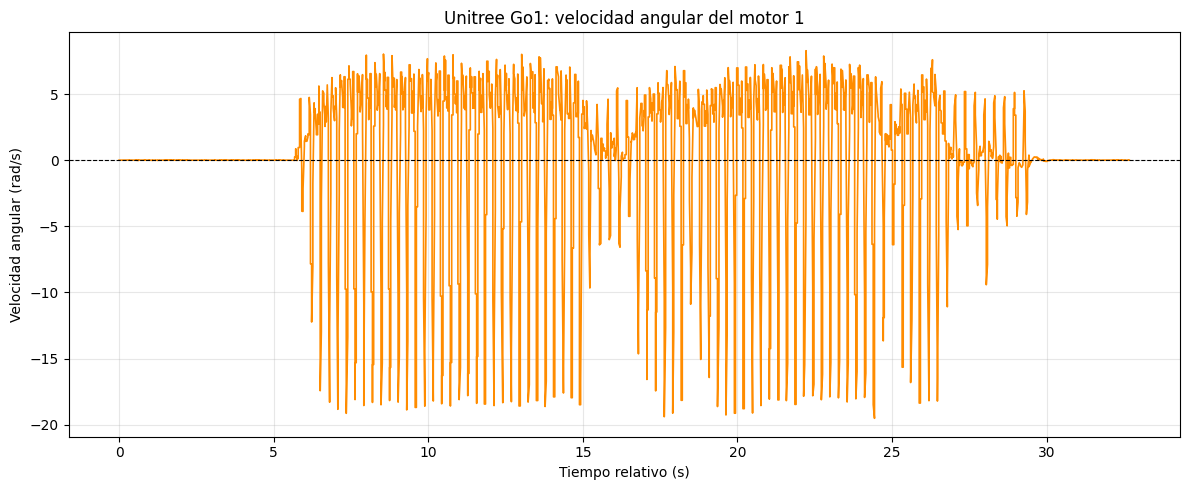

In [28]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_motor1["tiempo_relativo_s"],
    df_motor1["velocidad_rad_s"],
    linewidth=1.2,
    color="darkorange"
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=0.8
)

plt.title(
    "Unitree Go1: velocidad angular del motor 1"
)

plt.xlabel("Tiempo relativo (s)")
plt.ylabel("Velocidad angular (rad/s)")

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "grafico_velocidad_motor1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 8.3. Comparación del torque estimado por articulación

Se compara el valor absoluto promedio del torque estimado
entre las articulaciones de cadera lateral, muslo y rodilla.

Se utiliza el valor absoluto porque interesa comparar
la magnitud del torque independientemente del sentido
de actuación.

Los resultados representan promedios descriptivos de
la sesión experimental analizada.

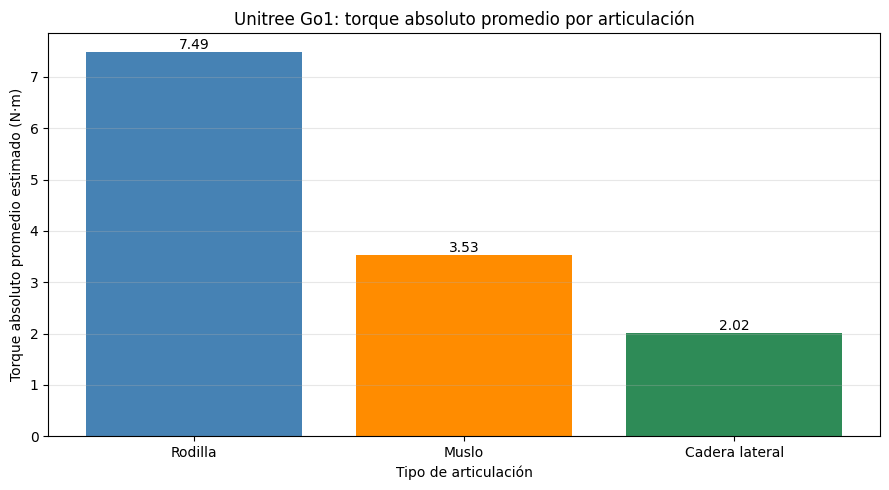

In [29]:
plt.figure(figsize=(9, 5))

barras = plt.bar(
    df_estadisticas["articulacion"],
    df_estadisticas["torque_promedio_Nm"],
    color=["steelblue", "darkorange", "seagreen"]
)

plt.title(
    "Unitree Go1: torque absoluto promedio por articulación"
)

plt.xlabel("Tipo de articulación")
plt.ylabel("Torque absoluto promedio estimado (N·m)")

plt.grid(axis="y", alpha=0.3)

# Mostrar los valores sobre las barras
for barra in barras:

    altura = barra.get_height()

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura,
        f"{altura:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    "grafico_torque_articulaciones.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 8.4. Comparación del torque estimado entre las rodillas

Se comparan las cuatro articulaciones de rodilla mediante
el torque absoluto promedio estimado.

El análisis permite identificar diferencias entre las patas
delanteras y traseras durante la sesión registrada.

,pata,motor_id,torque_promedio_Nm
0,Delantera derecha,2,7.293
1,Delantera izquierda,5,7.145
2,Trasera derecha,8,8.256
3,Trasera izquierda,11,7.247


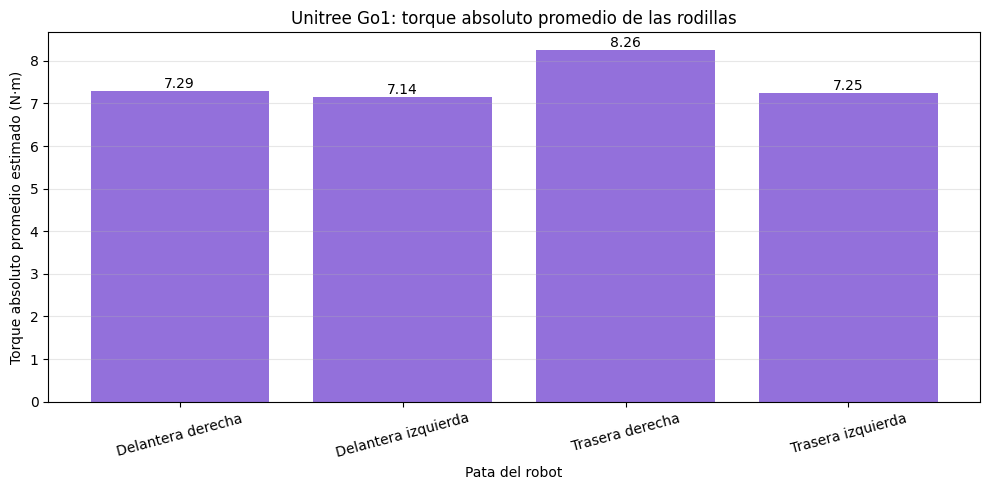

In [30]:
consulta_rodillas = """
SELECT
    m.pata,
    d.motor_id,
    ROUND(AVG(ABS(d.torque_Nm)), 3) AS torque_promedio_Nm

FROM mediciones AS d

INNER JOIN motores AS m
    ON d.motor_id = m.motor_id

WHERE m.articulacion = 'Rodilla'

GROUP BY m.pata, d.motor_id

ORDER BY d.motor_id;
"""

df_rodillas = pd.read_sql_query(
    consulta_rodillas,
    conexion_bd
)

display(df_rodillas)

plt.figure(figsize=(10, 5))

barras = plt.bar(
    df_rodillas["pata"],
    df_rodillas["torque_promedio_Nm"],
    color="mediumpurple"
)

plt.title(
    "Unitree Go1: torque absoluto promedio de las rodillas"
)

plt.xlabel("Pata del robot")
plt.ylabel("Torque absoluto promedio estimado (N·m)")

plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

for barra in barras:
    altura = barra.get_height()

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura,
        f"{altura:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    "grafico_torque_rodillas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 8.5. Visualizaciones interactivas con Bokeh

Se utiliza la biblioteca Bokeh para explorar de forma
interactiva las mediciones articulares del robot Unitree Go1.

Los gráficos permiten consultar valores individuales mediante
el cursor, ampliar intervalos temporales y examinar las
variaciones registradas durante la sesión experimental.

Se analizan la velocidad angular de una articulación y
el torque estimado de las cuatro rodillas.

In [31]:
# Crear fuente de datos para Bokeh
fuente_motor1 = ColumnDataSource(df_motor1)

# Crear figura interactiva
grafico_velocidad = figure(
    title="Unitree Go1: velocidad angular del motor 1",
    x_axis_label="Tiempo relativo (s)",
    y_axis_label="Velocidad angular (rad/s)",
    width=950,
    height=400,
    tools="pan,wheel_zoom,box_zoom,reset,save"
)

# Dibujar curva
linea = grafico_velocidad.line(
    x="tiempo_relativo_s",
    y="velocidad_rad_s",
    source=fuente_motor1,
    line_width=2,
    color="navy"
)

# Mostrar información al pasar el cursor
hover = HoverTool(
    renderers=[linea],
    tooltips=[
        ("Tiempo", "@tiempo_relativo_s{0.000} s"),
        ("Velocidad", "@velocidad_rad_s{0.000} rad/s"),
        ("Motor", "@motor_id")
    ],
    mode="vline"
)

grafico_velocidad.add_tools(hover)

show(grafico_velocidad)

### 8.6. Comparación interactiva del torque de las rodillas

Se representa la evolución temporal del torque estimado
de las cuatro articulaciones de rodilla.

La comparación permite observar diferencias en la magnitud
y dirección del torque durante la sesión experimental.

Los valores corresponden al torque estimado registrado
por el sistema del robot.

In [32]:
# Seleccionar las mediciones de las rodillas
df_rodillas_tiempo = df_consulta_integrada[
    df_consulta_integrada["motor_id"].isin([2, 5, 8, 11])
].copy()

# Configurar figura
grafico_rodillas = figure(
    title="Unitree Go1: torque estimado de las cuatro rodillas",
    x_axis_label="Tiempo relativo (s)",
    y_axis_label="Torque estimado (N·m)",
    width=950,
    height=450,
    tools="pan,wheel_zoom,box_zoom,reset,save"
)

# Colores y nombres
motores_rodilla = {
    2: ("Delantera derecha", "blue"),
    5: ("Delantera izquierda", "red"),
    8: ("Trasera derecha", "green"),
    11: ("Trasera izquierda", "orange")
}

# Dibujar una curva para cada rodilla
for motor_id, (nombre, color) in motores_rodilla.items():

    datos = df_rodillas_tiempo[
        df_rodillas_tiempo["motor_id"] == motor_id
    ].sort_values("tiempo_relativo_s")

    fuente = ColumnDataSource(datos)

    linea = grafico_rodillas.line(
        x="tiempo_relativo_s",
        y="torque_Nm",
        source=fuente,
        line_width=2,
        color=color,
        legend_label=nombre
    )

    grafico_rodillas.add_tools(
        HoverTool(
            renderers=[linea],
            tooltips=[
                ("Pata", "@pata"),
                ("Tiempo", "@tiempo_relativo_s{0.000} s"),
                ("Torque", "@torque_Nm{0.000} N·m")
            ],
            mode="vline"
        )
    )

# Ubicar leyenda
grafico_rodillas.legend.location = "top_left"
grafico_rodillas.legend.click_policy = "hide"

show(grafico_rodillas)

## 9. Integración de datos y generación del dataset final

En esta sección se integran dos fuentes de almacenamiento:

- Archivo CSV: contiene 30 000 registros de telemetría del Unitree Go1.
- Base de datos SQLite: proporciona el catálogo descriptivo de
  las 12 articulaciones del robot.

La integración se realiza mediante Pandas, utilizando la
columna motor_id como identificador común.

Como resultado, se genera un dataset enriquecido que
incorpora la ubicación física y el tipo de articulación
correspondientes a cada medición.

In [33]:
# Consultar el catálogo de motores almacenado en SQLite

consulta_catalogo = """
SELECT
    motor_id,
    pata,
    articulacion
FROM motores
ORDER BY motor_id;
"""

df_catalogo_sql = pd.read_sql_query(
    consulta_catalogo,
    conexion_bd
)

print("Catálogo recuperado desde SQLite")
print("Dimensiones:", df_catalogo_sql.shape)

display(df_catalogo_sql)

Catálogo recuperado desde SQLite
Dimensiones: (12, 3)


,motor_id,pata,articulacion
0,0,Delantera derecha,Cadera lateral
1,1,Delantera derecha,Muslo
2,2,Delantera derecha,Rodilla
3,3,Delantera izquierda,Cadera lateral
4,4,Delantera izquierda,Muslo
5,5,Delantera izquierda,Rodilla
6,6,Trasera derecha,Cadera lateral
7,7,Trasera derecha,Muslo
8,8,Trasera derecha,Rodilla
9,9,Trasera izquierda,Cadera lateral


In [34]:
# Leer el CSV generado o cargado previamente

df_csv = pd.read_csv(
    "unitree_go1_telemetria_30000.csv"
)

# Integrar mediciones con catálogo SQL
df_integrado = pd.merge(
    df_csv,
    df_catalogo_sql,
    on="motor_id",
    how="left",
    validate="many_to_one"
)

print("Dimensiones del CSV:", df_csv.shape)
print("Dimensiones del catálogo SQL:", df_catalogo_sql.shape)
print("Dimensiones del dataset integrado:", df_integrado.shape)

display(df_integrado.head(12))

Dimensiones del CSV: (30000, 9)
Dimensiones del catálogo SQL: (12, 3)
Dimensiones del dataset integrado: (30000, 11)


,instante,tiempo_ros,motor_id,posicion_rad,velocidad_rad_s,torque_Nm,temperatura_C,tiempo_relativo_s,sesion,pata,articulacion
0,0,1.694525e+09,0,0.119293,0.000840,0.714844,54,0.0,running,Delantera derecha,Cadera lateral
1,0,1.694525e+09,1,0.825305,-0.000278,0.863281,54,0.0,running,Delantera derecha,Muslo
2,0,1.694525e+09,2,-1.713426,-0.007499,5.488281,64,0.0,running,Delantera derecha,Rodilla
3,0,1.694525e+09,3,-0.075997,0.008949,-0.839844,50,0.0,running,Delantera izquierda,Cadera lateral
4,0,1.694525e+09,4,0.831845,-0.000513,0.738281,54,0.0,running,Delantera izquierda,Muslo
5,0,1.694525e+09,5,-1.683431,0.001599,4.375000,61,0.0,running,Delantera izquierda,Rodilla
6,0,1.694525e+09,6,0.045235,-0.000050,1.406250,52,0.0,running,Trasera derecha,Cadera lateral
7,0,1.694525e+09,7,0.815071,0.002106,0.691406,56,0.0,running,Trasera derecha,Muslo
8,0,1.694525e+09,8,-1.662923,-0.000185,6.195312,65,0.0,running,Trasera derecha,Rodilla
9,0,1.694525e+09,9,-0.022042,-0.015521,-2.027344,51,0.0,running,Trasera izquierda,Cadera lateral


In [35]:
# Validaciones del dataset integrado

assert len(df_integrado) == 30000, (
    "La integración modificó la cantidad de registros"
)

assert df_integrado.shape[1] == 11, (
    "El dataset no contiene las 11 columnas esperadas"
)

assert df_integrado.isnull().sum().sum() == 0, (
    "Se encontraron valores faltantes"
)

assert df_integrado["motor_id"].nunique() == 12

assert df_integrado["instante"].nunique() == 2500

print("INTEGRACIÓN VALIDADA CORRECTAMENTE")

print("\nRegistros por articulación:")

display(
    df_integrado["articulacion"]
    .value_counts()
    .rename_axis("Articulación")
    .reset_index(name="Registros")
)

INTEGRACIÓN VALIDADA CORRECTAMENTE

Registros por articulación:


,Articulación,Registros
0,Cadera lateral,10000
1,Muslo,10000
2,Rodilla,10000


In [36]:
# Exportar el dataset final enriquecido

nombre_dataset_final = "unitree_go1_dataset_integrado.csv"

df_integrado.to_csv(
    nombre_dataset_final,
    index=False,
    encoding="utf-8-sig"
)

print("Dataset final generado:", nombre_dataset_final)
print("Registros:", len(df_integrado))
print("Columnas:", len(df_integrado.columns))

Dataset final generado: unitree_go1_dataset_integrado.csv
Registros: 30000
Columnas: 11


In [37]:
# Verificación del archivo exportado

df_verificacion_final = pd.read_csv(
    "unitree_go1_dataset_integrado.csv"
)

assert df_verificacion_final.shape == (30000, 11)

assert df_verificacion_final.isnull().sum().sum() == 0

print("ARCHIVO FINAL VERIFICADO CORRECTAMENTE")

display(df_verificacion_final.head())

ARCHIVO FINAL VERIFICADO CORRECTAMENTE


,instante,tiempo_ros,motor_id,posicion_rad,velocidad_rad_s,torque_Nm,temperatura_C,tiempo_relativo_s,sesion,pata,articulacion
0,0,1.694525e+09,0,0.119293,0.000840,0.714844,54,0.0,running,Delantera derecha,Cadera lateral
1,0,1.694525e+09,1,0.825305,-0.000278,0.863281,54,0.0,running,Delantera derecha,Muslo
2,0,1.694525e+09,2,-1.713426,-0.007499,5.488281,64,0.0,running,Delantera derecha,Rodilla
3,0,1.694525e+09,3,-0.075997,0.008949,-0.839844,50,0.0,running,Delantera izquierda,Cadera lateral
4,0,1.694525e+09,4,0.831845,-0.000513,0.738281,54,0.0,running,Delantera izquierda,Muslo



## 10. Detección de anomalías mediante Scikit-learn

En esta sección se implementa un modelo de aprendizaje automático no supervisado para identificar mediciones atípicas en la telemetría del robot cuadrúpedo Unitree Go1.

Se utiliza el algoritmo **Isolation Forest**, disponible en la biblioteca Scikit-learn.

El análisis considera cuatro variables operativas:

- Posición angular (rad).
- Velocidad angular (rad/s).
- Torque estimado (N·m).
- Temperatura (°C).

Se incorpora también el identificador del motor para distinguir las articulaciones del robot.

El objetivo es identificar comportamientos estadísticamente inusuales sin necesidad de disponer de etiquetas de falla. Los resultados representan posibles anomalías de los datos, no diagnósticos mecánicos confirmados.

### 10.1. Preparación de características y entrenamiento del modelo
  

In [38]:

# SECCIÓN 10.1 - Scikit-learn: Isolation Forest

from sklearn.ensemble import IsolationForest
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Recuperar el dataset integrado de la sección 9
df_ia = df_integrado.copy()

variables = [
    "posicion_rad",
    "velocidad_rad_s",
    "torque_Nm",
    "temperatura_C",
    "motor_id"
]

# Ordenar temporalmente las mediciones
df_ia = df_ia.sort_values(
    ["instante", "motor_id"]
).reset_index(drop=True)

# División cronológica por instantes completos (70/30)
instantes = np.sort(df_ia["instante"].unique())
corte = int(len(instantes) * 0.70)

instantes_entrenamiento = instantes[:corte]
instantes_prueba = instantes[corte:]

train_mask = df_ia["instante"].isin(instantes_entrenamiento)
test_mask = df_ia["instante"].isin(instantes_prueba)

# Escalar variables numéricas y codificar el motor
preprocesador = ColumnTransformer([
    ("numericas", StandardScaler(), variables[:4]),
    ("motor", OneHotEncoder(handle_unknown="ignore"),
     ["motor_id"])
])

X_train = preprocesador.fit_transform(
    df_ia.loc[train_mask, variables]
)

X_test = preprocesador.transform(
    df_ia.loc[test_mask, variables]
)

# Modelo no supervisado
modelo_iforest = IsolationForest(
    n_estimators=200,
    contamination=0.03,
    random_state=42,
    n_jobs=-1
)

modelo_iforest.fit(X_train)

# Predicción sobre registros de prueba
df_resultados = df_ia.loc[test_mask].copy()

df_resultados["prediccion"] = modelo_iforest.predict(
    X_test
)

df_resultados["anomalia"] = (
    df_resultados["prediccion"] == -1
)

df_resultados["score_anomalia"] = (
    -modelo_iforest.score_samples(X_test)
)

# Resultados
total = len(df_resultados)
anomalas = int(df_resultados["anomalia"].sum())

print("Modelo: Isolation Forest")
print("Entrenamiento:", int(train_mask.sum()), "registros")
print("Prueba:", total, "registros")
print("Mediciones atípicas:", anomalas)
print("Porcentaje:", round(anomalas / total * 100, 2), "%")

display(df_resultados.head())


Modelo: Isolation Forest
Entrenamiento: 21000 registros
Prueba: 9000 registros
Mediciones atípicas: 134
Porcentaje: 1.49 %


,instante,tiempo_ros,motor_id,posicion_rad,velocidad_rad_s,torque_Nm,temperatura_C,tiempo_relativo_s,sesion,pata,articulacion,prediccion,anomalia,score_anomalia
21000,11391,1.694525e+09,0,0.089803,-0.021103,5.117188,54,22.909045,running,Delantera derecha,Cadera lateral,1,False,0.438999
21001,11391,1.694525e+09,1,1.167865,5.180863,-7.593750,54,22.909045,running,Delantera derecha,Muslo,1,False,0.476092
21002,11391,1.694525e+09,2,-1.768571,2.419142,8.160156,64,22.909045,running,Delantera derecha,Rodilla,1,False,0.442741
21003,11391,1.694525e+09,3,-0.096343,0.700480,1.804688,50,22.909045,running,Delantera izquierda,Cadera lateral,1,False,0.448044
21004,11391,1.694525e+09,4,0.430970,-3.872227,5.117188,54,22.909045,running,Delantera izquierda,Muslo,1,False,0.443839



### 10.2. Visualización de anomalías detectadas

Para interpretar los resultados del modelo Isolation Forest, se representan gráficamente las mediciones clasificadas como normales y atípicas.

Se analiza la relación entre velocidad angular y torque estimado, identificando los registros considerados inusuales por el modelo.

Adicionalmente, se calcula la distribución de anomalías por articulación para determinar en qué partes del robot se concentran estas observaciones.

Las anomalías identificadas representan desviaciones estadísticas respecto de los patrones aprendidos, sin constituir evidencia suficiente de fallas mecánicas.


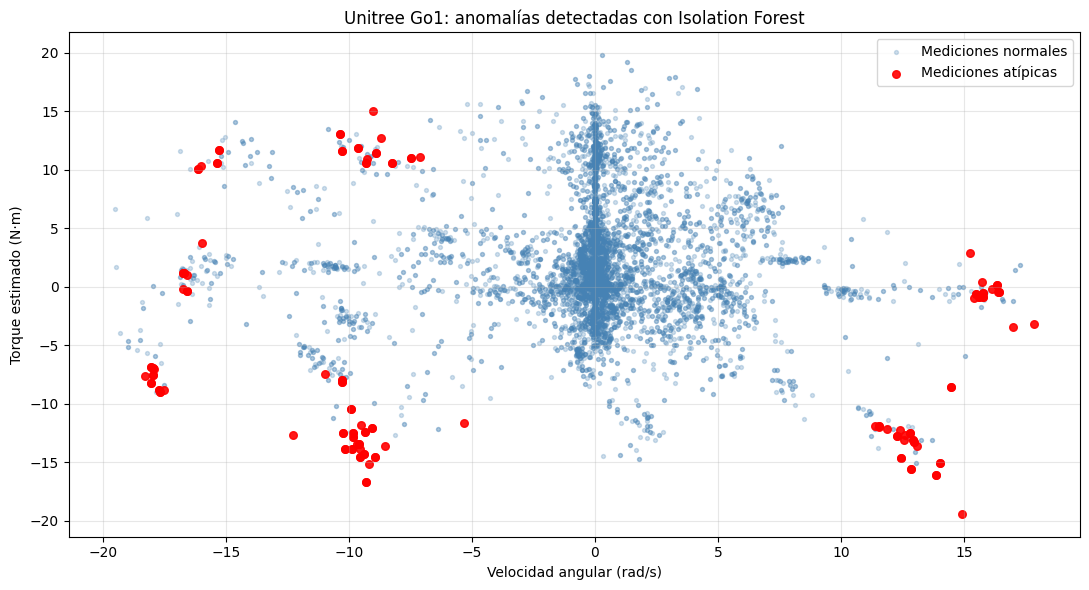

Distribución de anomalías por articulación:


,total,anomalas,porcentaje
articulacion,,,
Cadera lateral,3000,0,0.000000
Muslo,3000,55,1.833333
Rodilla,3000,79,2.633333


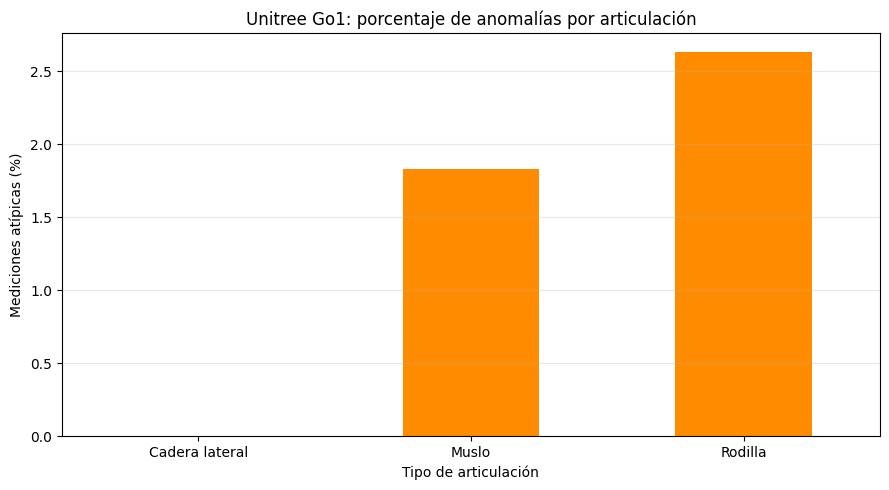

In [39]:

# SECCIÓN 10.2 - Visualización de anomalías

import matplotlib.pyplot as plt

# Separar mediciones normales y atípicas
normales = df_resultados[
    ~df_resultados["anomalia"]
]

anomalas = df_resultados[
    df_resultados["anomalia"]
]

# Figura: torque frente a velocidad angular
plt.figure(figsize=(11, 6))

plt.scatter(
    normales["velocidad_rad_s"],
    normales["torque_Nm"],
    s=8,
    alpha=0.25,
    color="steelblue",
    label="Mediciones normales"
)

plt.scatter(
    anomalas["velocidad_rad_s"],
    anomalas["torque_Nm"],
    s=30,
    alpha=0.9,
    color="red",
    label="Mediciones atípicas"
)

plt.title(
    "Unitree Go1: anomalías detectadas con Isolation Forest"
)

plt.xlabel("Velocidad angular (rad/s)")
plt.ylabel("Torque estimado (N·m)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "grafico_anomalias_isolation_forest.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Distribución de anomalías por articulación
resumen = (
    df_resultados
    .groupby("articulacion")
    .agg(
        total=("anomalia", "size"),
        anomalas=("anomalia", "sum")
    )
)

resumen["porcentaje"] = (
    100 * resumen["anomalas"] / resumen["total"]
)

print("Distribución de anomalías por articulación:")
display(resumen)

# Gráfico de porcentajes
plt.figure(figsize=(9, 5))

resumen["porcentaje"].plot(
    kind="bar",
    color="darkorange"
)

plt.title(
    "Unitree Go1: porcentaje de anomalías por articulación"
)

plt.ylabel("Mediciones atípicas (%)")
plt.xlabel("Tipo de articulación")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "grafico_anomalias_articulaciones.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 10.3. Interpretación de los resultados

El modelo Isolation Forest fue entrenado con 21 000 registros de telemetría y evaluado sobre 9 000 registros posteriores de la misma sesión experimental.

Se identificaron 134 mediciones atípicas, equivalentes al 1,49 % del conjunto de prueba.

Al analizar los resultados por tipo de articulación se obtuvo:

- Cadera lateral: 0 mediciones atípicas (0,00 %).
- Muslo: 55 mediciones atípicas (1,83 %).
- Rodilla: 79 mediciones atípicas (2,63 %).

Las articulaciones de rodilla concentraron la mayor proporción de mediciones clasificadas como atípicas.

En la representación de velocidad angular frente a torque estimado se observa que varias de estas mediciones aparecen en regiones alejadas de las concentraciones principales de datos.

Estos resultados permiten identificar patrones operativos inusuales mediante aprendizaje automático no supervisado. Sin embargo, las mediciones atípicas no representan necesariamente fallas mecánicas.

El análisis corresponde a una sola sesión experimental y no dispone de etiquetas de referencia para evaluar la capacidad de detección de fallas del modelo.

Por tanto, los resultados deben interpretarse como una exploración estadística de la telemetría, y no como un sistema validado de diagnóstico o mantenimiento predictivo.


In [40]:

# SECCIÓN 10.4 - Verificación de eventos atípicos

# Extraer las mediciones clasificadas como anomalías
df_anomalias = df_resultados[
    df_resultados["anomalia"]
].copy()

# Número de instantes diferentes afectados
instantes_anomalos = df_anomalias["instante"].nunique()

# Número de combinaciones instante-motor afectadas
eventos_motor = (
    df_anomalias[["instante", "motor_id"]]
    .drop_duplicates()
    .shape[0]
)

# Motores individuales afectados
motores_afectados = df_anomalias["motor_id"].nunique()

print("Mediciones atípicas:", len(df_anomalias))
print("Instantes diferentes con anomalías:", instantes_anomalos)
print("Combinaciones instante-motor:", eventos_motor)
print("Motores con anomalías:", motores_afectados)

print("\nAnomalías por motor:")
display(
    df_anomalias.groupby(
        ["motor_id", "pata", "articulacion"]
    ).size().reset_index(name="anomalías")
    .sort_values("anomalías", ascending=False)
)


Mediciones atípicas: 134
Instantes diferentes con anomalías: 103
Combinaciones instante-motor: 134
Motores con anomalías: 5

Anomalías por motor:


,motor_id,pata,articulacion,anomalías
3,8,Trasera derecha,Rodilla,53
0,1,Delantera derecha,Muslo,27
1,2,Delantera derecha,Rodilla,26
2,7,Trasera derecha,Muslo,19
4,10,Trasera izquierda,Muslo,9


### 10.5. Análisis de anomalías por motor

El análisis individual de las articulaciones permitió identificar que las 134 mediciones atípicas se distribuyeron entre cinco de los doce motores del robot Unitree Go1.

El motor 8, correspondiente a la rodilla trasera derecha, presentó la mayor cantidad de observaciones atípicas (53 registros), seguido del motor 1, correspondiente al muslo delantero derecho (27 registros), y del motor 2, correspondiente a la rodilla delantera derecha (26 registros).

Los motores 7 y 10 registraron 19 y 9 mediciones atípicas, respectivamente.

Estos resultados muestran que las observaciones inusuales no se distribuyen uniformemente entre las articulaciones del robot.

Sin embargo, debido a que se utiliza un modelo de aprendizaje no supervisado y no se dispone de etiquetas que identifiquen fallas reales, los resultados deben interpretarse como desviaciones estadísticas y no como evidencia directa de deterioro mecánico.


## 11. Detección de anomalías mediante TensorFlow y Keras

En esta sección se implementa una red neuronal de tipo autoencoder para analizar patrones operativos en la telemetría del robot cuadrúpedo Unitree Go1.

A diferencia de Isolation Forest, el autoencoder aprende una representación comprimida de los datos de entrada y posteriormente intenta reconstruirlos.

El error entre los valores originales y los reconstruidos permite identificar observaciones que el modelo representa con mayor dificultad.

Se utilizan las siguientes tecnologías:

- TensorFlow: motor de cálculo y entrenamiento de redes neuronales.
- Keras: API de alto nivel para definir la arquitectura de la red.
- NumPy y Pandas: manipulación y procesamiento de datos.
- Matplotlib: visualización de resultados.

Se mantienen los mismos conjuntos de entrenamiento y prueba utilizados con Scikit-learn, correspondientes a 21 000 y 9 000 mediciones, respectivamente.

### 11.1. Preparación de datos para la red neuronal


In [41]:

# SECCIÓN 11.1 - Preparación para TensorFlow/Keras

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Semillas para mejorar la reproducibilidad
tf.keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

# Reutilizar los datos ya transformados con Scikit-learn
# No se vuelve a ajustar el preprocesador
X_train_ae = np.asarray(
    X_train.toarray() if hasattr(X_train, "toarray")
    else X_train,
    dtype=np.float32
)

X_test_ae = np.asarray(
    X_test.toarray() if hasattr(X_test, "toarray")
    else X_test,
    dtype=np.float32
)

assert X_train_ae.shape[0] == 21000
assert X_test_ae.shape[0] == 9000
assert np.isfinite(X_train_ae).all()
assert np.isfinite(X_test_ae).all()

print("Entrenamiento:", X_train_ae.shape)
print("Prueba:", X_test_ae.shape)
print("Características:", X_train_ae.shape[1])


TensorFlow: 2.21.0
Keras: 3.13.2
Entrenamiento: (21000, 16)
Prueba: (9000, 16)
Características: 16



### 11.2. Arquitectura y entrenamiento del autoencoder

Se implementa una red neuronal completamente conectada que comprime las características de entrada hasta una representación latente de tres dimensiones.

Posteriormente, el decodificador reconstruye las características originales.

La función de pérdida utilizada es el error cuadrático medio (MSE). Se utiliza Adam como optimizador.

Para evitar utilizar los datos de prueba durante el entrenamiento, una parte final del conjunto de entrenamiento se reserva para validación y calibración del umbral de anomalía.


In [42]:

# SECCIÓN 11.2 - Construcción del autoencoder

n_features = X_train_ae.shape[1]

# Separación cronológica interna 80/20
corte_ae = int(len(X_train_ae) * 0.80)

X_ajuste_ae = X_train_ae[:corte_ae]
X_validacion_ae = X_train_ae[corte_ae:]

# Crear arquitectura
entrada = keras.Input(shape=(n_features,))

x = layers.Dense(12, activation="relu")(entrada)
x = layers.Dense(6, activation="relu")(x)

# Representación comprimida
latente = layers.Dense(
    3, activation="linear", name="espacio_latente"
)(x)

x = layers.Dense(6, activation="relu")(latente)
x = layers.Dense(12, activation="relu")(x)

salida = layers.Dense(
    n_features, activation="linear"
)(x)

autoencoder = keras.Model(
    inputs=entrada,
    outputs=salida,
    name="Unitree_Go1_Autoencoder"
)

autoencoder.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse"
)

autoencoder.summary()

# Detener entrenamiento si deja de mejorar
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Entrenar
historial_ae = autoencoder.fit(
    X_ajuste_ae,
    X_ajuste_ae,
    validation_data=(
        X_validacion_ae,
        X_validacion_ae
    ),
    epochs=80,
    batch_size=128,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)

print("Entrenamiento completado")


Model: "Unitree_Go1_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 12)             │           204 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │            78 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ espacio_latente (Dense)         │ (None, 3)              │            21 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 12)             │            84 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           208 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 619 (2.42 KB)

 Trainable params: 619 (2.42 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/80
132/132 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - loss: 0.2556 - val_loss: 0.2459
Epoch 2/80
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1588 - val_loss: 0.1831
Epoch 3/80
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1310 - val_loss: 0.1566
Epoch 4/80
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1120 - val_loss: 0.1267
Epoch 5/80
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0904 - val_loss: 0.0944
Epoch 6/80
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0742 - val_loss: 0.0770
Epoch 7/80
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0646 - val_loss: 0.0653
Epoch 8/80
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0584 - val_loss: 0.0601
Epoch 9/80
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0556 - val_loss: 0.0574
Epoch 10/80
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0538 - val_loss: 0.0555
Epoch 11/80
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0523 - val_loss: 0.0541
Epoch 12/80
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/ste


### 11.3. Evolución del error de entrenamiento

Se representa la evolución del error cuadrático medio durante el entrenamiento y la validación.

Esta gráfica permite observar si la red neuronal mejora su capacidad de reconstrucción y analizar posibles diferencias entre el conjunto de ajuste y el de validación.


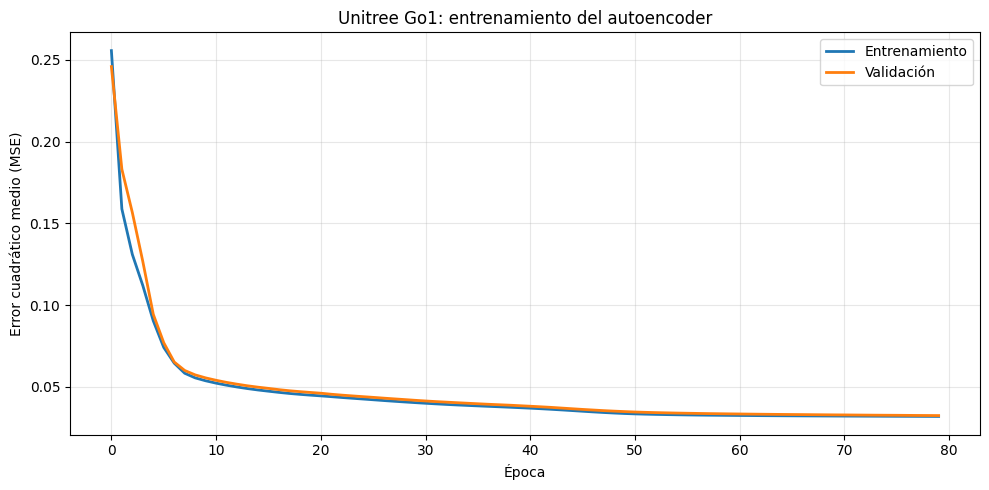

Mínimo error de validación: 0.032506


In [43]:

# SECCIÓN 11.3 - Curvas de aprendizaje

plt.figure(figsize=(10, 5))

plt.plot(
    historial_ae.history["loss"],
    label="Entrenamiento",
    linewidth=2
)

plt.plot(
    historial_ae.history["val_loss"],
    label="Validación",
    linewidth=2
)

plt.title(
    "Unitree Go1: entrenamiento del autoencoder"
)

plt.xlabel("Época")
plt.ylabel("Error cuadrático medio (MSE)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "grafico_entrenamiento_autoencoder.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Mínimo error de validación:",
    round(min(historial_ae.history["val_loss"]), 6)
)



### 11.4. Detección mediante error de reconstrucción

El autoencoder reconstruye las mediciones de telemetría y calcula el error cuadrático medio entre la entrada y la salida de la red.

Se establece un umbral experimental utilizando el percentil 97 de los errores de reconstrucción del conjunto de validación.

Las mediciones de prueba cuyo error supera este umbral se clasifican como atípicas.

Este procedimiento no requiere etiquetas de falla. Sin embargo, el umbral no representa un límite mecánico de seguridad.


In [44]:

# SECCIÓN 11.4 - Detección de anomalías

# Reconstruir datos de validación
recon_val = autoencoder.predict(
    X_validacion_ae, verbose=0
)

error_val = np.mean(
    np.square(X_validacion_ae - recon_val),
    axis=1
)

# Umbral de anomalía calibrado sin datos de prueba
umbral_ae = np.percentile(error_val, 97)

# Reconstruir datos de prueba
recon_test = autoencoder.predict(
    X_test_ae, verbose=0
)

error_test = np.mean(
    np.square(X_test_ae - recon_test),
    axis=1
)

# Guardar resultados
df_resultados_ae = df_ia.loc[
    test_mask
].copy()

df_resultados_ae["error_reconstruccion"] = error_test

df_resultados_ae["anomalia_ae"] = (
    error_test > umbral_ae
)

total_ae = len(df_resultados_ae)
anomalias_ae = int(
    df_resultados_ae["anomalia_ae"].sum()
)

print("Modelo: Autoencoder TensorFlow/Keras")
print("Umbral MSE:", round(umbral_ae, 6))
print("Registros evaluados:", total_ae)
print("Mediciones atípicas:", anomalias_ae)
print(
    "Porcentaje:",
    round(100 * anomalias_ae / total_ae, 2),
    "%"
)

display(df_resultados_ae.head())


Modelo: Autoencoder TensorFlow/Keras
Umbral MSE: 0.075583
Registros evaluados: 9000
Mediciones atípicas: 297
Porcentaje: 3.3 %


,instante,tiempo_ros,motor_id,posicion_rad,velocidad_rad_s,torque_Nm,temperatura_C,tiempo_relativo_s,sesion,pata,articulacion,error_reconstruccion,anomalia_ae
21000,11391,1.694525e+09,0,0.089803,-0.021103,5.117188,54,22.909045,running,Delantera derecha,Cadera lateral,0.018682,False
21001,11391,1.694525e+09,1,1.167865,5.180863,-7.593750,54,22.909045,running,Delantera derecha,Muslo,0.050807,False
21002,11391,1.694525e+09,2,-1.768571,2.419142,8.160156,64,22.909045,running,Delantera derecha,Rodilla,0.043422,False
21003,11391,1.694525e+09,3,-0.096343,0.700480,1.804688,50,22.909045,running,Delantera izquierda,Cadera lateral,0.003460,False
21004,11391,1.694525e+09,4,0.430970,-3.872227,5.117188,54,22.909045,running,Delantera izquierda,Muslo,0.126631,True



### 11.5. Comparación entre Isolation Forest y Autoencoder

Se comparan las mediciones identificadas como atípicas por ambos modelos.

El objetivo es determinar qué proporción de observaciones recibe la misma clasificación y cuántas son identificadas como atípicas por ambos métodos.

Debido a la ausencia de etiquetas reales de falla, esta comparación mide concordancia entre modelos y no precisión diagnóstica.


,Isolation Forest,Autoencoder
0,134,297


Anomalías detectadas por ambos: 1
Anomalías detectadas por alguno: 430
Acuerdo global: 95.23 %
Índice Jaccard: 0.0023


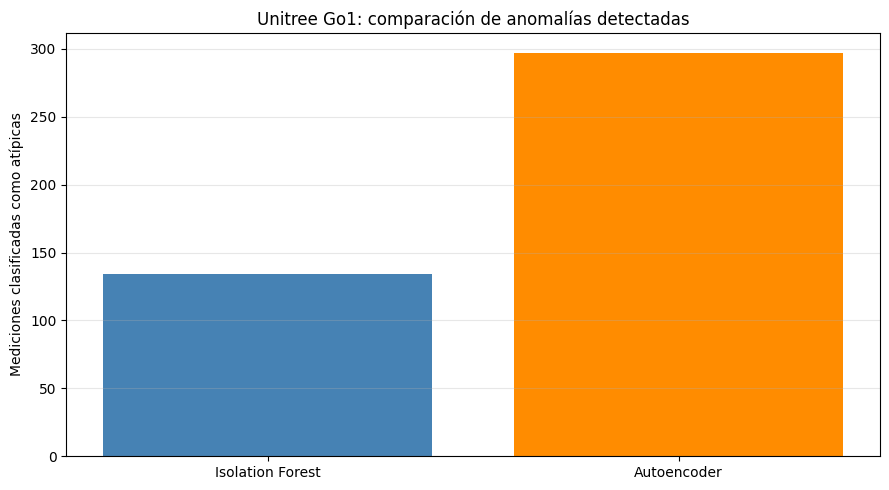

Resultados y modelo guardados


In [45]:

# SECCIÓN 11.5 - Comparación de modelos

assert df_resultados.index.equals(
    df_resultados_ae.index
), "Los conjuntos de prueba no coinciden"

comparacion = pd.DataFrame({
    "Isolation Forest": [
        int(df_resultados["anomalia"].sum())
    ],
    "Autoencoder": [
        int(df_resultados_ae["anomalia_ae"].sum())
    ]
})

display(comparacion)

# Comparar coincidencias de detección
iforest_flags = df_resultados["anomalia"].to_numpy()
ae_flags = df_resultados_ae["anomalia_ae"].to_numpy()

coincidencias_anomalas = int(
    np.sum(iforest_flags & ae_flags)
)

union_anomalas = int(
    np.sum(iforest_flags | ae_flags)
)

acuerdo_global = float(
    np.mean(iforest_flags == ae_flags)
)

jaccard = (
    coincidencias_anomalas / union_anomalas
    if union_anomalas > 0 else 1.0
)

print("Anomalías detectadas por ambos:",
      coincidencias_anomalas)

print("Anomalías detectadas por alguno:",
      union_anomalas)

print("Acuerdo global:",
      round(acuerdo_global * 100, 2), "%")

print("Índice Jaccard:",
      round(jaccard, 4))

# Gráfico comparativo
plt.figure(figsize=(9, 5))

plt.bar(
    ["Isolation Forest", "Autoencoder"],
    [
        int(iforest_flags.sum()),
        int(ae_flags.sum())
    ],
    color=["steelblue", "darkorange"]
)

plt.title("Unitree Go1: comparación de anomalías detectadas")
plt.ylabel("Mediciones clasificadas como atípicas")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "grafico_comparacion_modelos_ia.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Exportar resultados para GitHub
df_resultados_ae.to_csv(
    "unitree_go1_resultados_autoencoder.csv",
    index=False
)

autoencoder.save(
    "unitree_go1_autoencoder.keras"
)

print("Resultados y modelo guardados")


In [46]:
# SECCIÓN 11.6 - Concordancia entre modelos

import pandas as pd
import matplotlib.pyplot as plt

# Verificar que se comparan las mismas mediciones
assert df_resultados.index.equals(df_resultados_ae.index)

comparacion_detallada = pd.DataFrame({
    "Isolation Forest": df_resultados["anomalia"].to_numpy(),
    "Autoencoder": df_resultados_ae["anomalia_ae"].to_numpy()
})

# Tabla de coincidencias
tabla = pd.crosstab(
    comparacion_detallada["Isolation Forest"],
    comparacion_detallada["Autoencoder"]
)

tabla = tabla.reindex(
    index=[False, True],
    columns=[False, True],
    fill_value=0
)

tabla.index = ["IF normal", "IF atípica"]
tabla.columns = ["AE normal", "AE atípica"]

display(tabla)

# Calcular coincidencias
ambos = int(tabla.loc["IF atípica", "AE atípica"])
solo_if = int(tabla.loc["IF atípica", "AE normal"])
solo_ae = int(tabla.loc["IF normal", "AE atípica"])

union = ambos + solo_if + solo_ae

jaccard = ambos / union if union else 1.0

print("Detectadas por ambos modelos:", ambos)
print("Solo Isolation Forest:", solo_if)
print("Solo Autoencoder:", solo_ae)
print("Índice Jaccard:", round(jaccard, 4))

,AE normal,AE atípica
IF normal,8570,296
IF atípica,133,1


Detectadas por ambos modelos: 1
Solo Isolation Forest: 133
Solo Autoencoder: 296
Índice Jaccard: 0.0023


### 11.7. Análisis de discrepancias entre los modelos

La comparación inicial mostró que Isolation Forest y el autoencoder identificaron conjuntos distintos de mediciones atípicas.

Para investigar esta diferencia se analiza la distribución de anomalías por motor y la relación entre las puntuaciones de ambos métodos.

Este análisis permitirá determinar si las discrepancias están relacionadas con determinadas articulaciones, diferencias en los criterios de detección o características de las variables de entrada.


,motor_id,pata,articulacion,isolation_forest,autoencoder,registros
0,0,Delantera derecha,Cadera lateral,0,0,750
1,1,Delantera derecha,Muslo,27,62,750
2,2,Delantera derecha,Rodilla,26,1,750
3,3,Delantera izquierda,Cadera lateral,0,1,750
4,4,Delantera izquierda,Muslo,0,86,750
5,5,Delantera izquierda,Rodilla,0,0,750
6,6,Trasera derecha,Cadera lateral,0,1,750
7,7,Trasera derecha,Muslo,19,64,750
8,8,Trasera derecha,Rodilla,53,0,750
9,9,Trasera izquierda,Cadera lateral,0,4,750


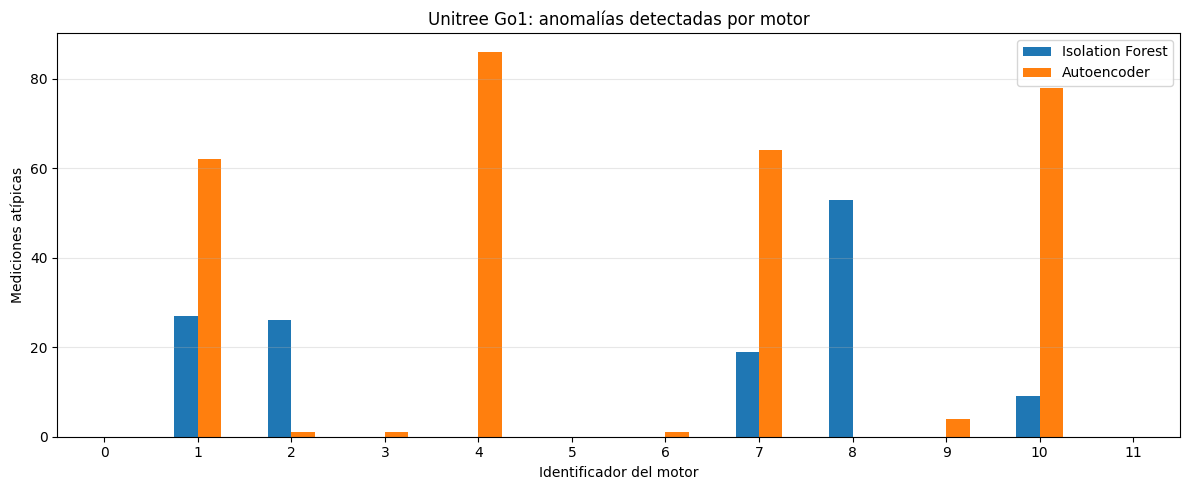

Correlación de Spearman entre puntuaciones: 0.1155


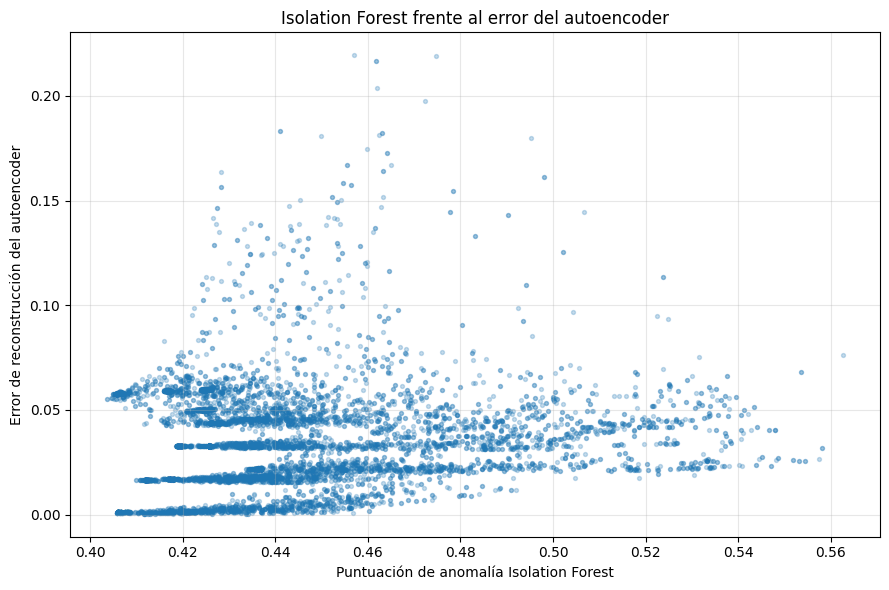

In [47]:

# SECCIÓN 11.7 - Diagnóstico de discrepancias

import matplotlib.pyplot as plt
import pandas as pd

# Verificar correspondencia entre registros
assert df_resultados.index.equals(df_resultados_ae.index)

# Construir tabla conjunta
df_diagnostico = df_resultados[
    ["motor_id", "pata", "articulacion",
     "anomalia", "score_anomalia"]
].copy()

df_diagnostico["anomalia_ae"] = (
    df_resultados_ae["anomalia_ae"].to_numpy()
)

df_diagnostico["error_ae"] = (
    df_resultados_ae["error_reconstruccion"].to_numpy()
)

# Resumen por motor
resumen_motores = (
    df_diagnostico
    .groupby(["motor_id", "pata", "articulacion"])
    .agg(
        isolation_forest=("anomalia", "sum"),
        autoencoder=("anomalia_ae", "sum"),
        registros=("motor_id", "size")
    )
    .reset_index()
)

display(resumen_motores)

# Comparación visual por motor
ax = resumen_motores.plot(
    x="motor_id",
    y=["isolation_forest", "autoencoder"],
    kind="bar",
    figsize=(12, 5),
    rot=0
)

ax.set_title(
    "Unitree Go1: anomalías detectadas por motor"
)
ax.set_xlabel("Identificador del motor")
ax.set_ylabel("Mediciones atípicas")
ax.legend(["Isolation Forest", "Autoencoder"])
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Relación entre puntuaciones continuas
correlacion = df_diagnostico[
    ["score_anomalia", "error_ae"]
].corr(method="spearman").iloc[0, 1]

print(
    "Correlación de Spearman entre puntuaciones:",
    round(correlacion, 4)
)

plt.figure(figsize=(9, 6))

plt.scatter(
    df_diagnostico["score_anomalia"],
    df_diagnostico["error_ae"],
    s=8,
    alpha=0.25
)

plt.title(
    "Isolation Forest frente al error del autoencoder"
)
plt.xlabel("Puntuación de anomalía Isolation Forest")
plt.ylabel("Error de reconstrucción del autoencoder")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Correlación global de Spearman:
0.1155

Correlación por articulación:


,articulacion,correlacion_spearman
0,Cadera lateral,0.459674
1,Muslo,-0.170423
2,Rodilla,0.003875


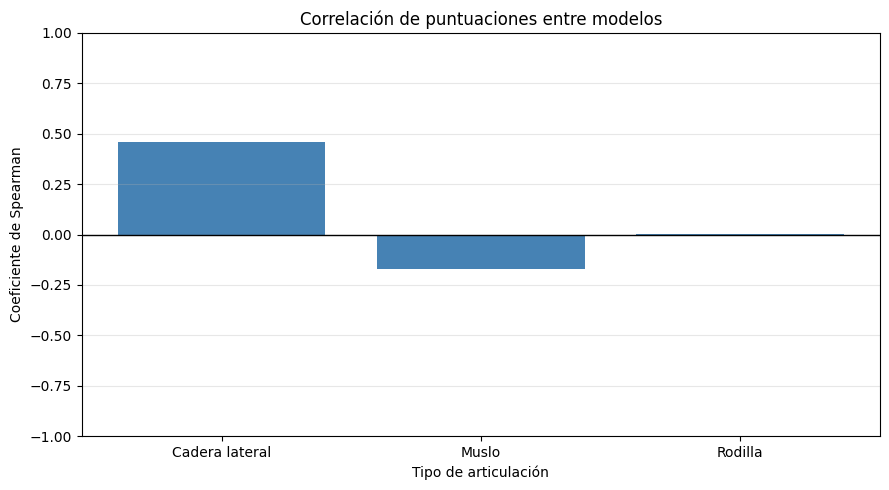

In [48]:
# SECCIÓN 11.8 - Relación entre las puntuaciones
# de Isolation Forest y Autoencoder

import pandas as pd
import matplotlib.pyplot as plt

# Correlación global entre las puntuaciones
spearman_global = df_diagnostico[
    ["score_anomalia", "error_ae"]
].corr(method="spearman").iloc[0, 1]

print("Correlación global de Spearman:")
print(round(spearman_global, 4))

# Correlación por tipo de articulación
correlaciones = []

for articulacion, grupo in df_diagnostico.groupby(
    "articulacion"
):
    correlacion = grupo[
        ["score_anomalia", "error_ae"]
    ].corr(method="spearman").iloc[0, 1]

    correlaciones.append({
        "articulacion": articulacion,
        "correlacion_spearman": correlacion
    })

df_correlaciones = pd.DataFrame(correlaciones)

print("\nCorrelación por articulación:")
display(df_correlaciones)

# Representación gráfica
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    df_correlaciones["articulacion"],
    df_correlaciones["correlacion_spearman"],
    color="steelblue"
)

ax.axhline(0, color="black", linewidth=1)

ax.set_title(
    "Correlación de puntuaciones entre modelos"
)

ax.set_ylabel("Coeficiente de Spearman")
ax.set_xlabel("Tipo de articulación")
ax.set_ylim(-1, 1)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


### 11.9. Interpretación comparativa de los modelos

Se realizó un análisis de correlación de Spearman para evaluar la relación entre las puntuaciones de anomalía generadas por Isolation Forest y el autoencoder.

Los resultados mostraron comportamientos diferentes según el tipo de articulación. En las articulaciones de cadera lateral se obtuvo una correlación positiva moderada (ρ = 0,4597), mientras que en los muslos se observó una correlación negativa débil (ρ = −0,1704). En las rodillas, la correlación fue prácticamente nula (ρ = 0,0039).

Estos resultados indican que ambos modelos no necesariamente asignan niveles similares de anomalía a las mismas mediciones.

Asimismo, Isolation Forest identificó 134 mediciones atípicas y el autoencoder identificó 297, con una coincidencia entre los registros clasificados como anómalos.

Las diferencias observadas podrían estar relacionadas con los mecanismos de aprendizaje, el preprocesamiento y los umbrales utilizados por cada algoritmo.

Por tanto, no es posible determinar cuál modelo presenta mejor capacidad de detección de fallas, debido a la ausencia de etiquetas de referencia y validación experimental específica.

El análisis demuestra la aplicación de dos técnicas de inteligencia artificial sobre datos operativos de un robot cuadrúpedo y evidencia la importancia de seleccionar y validar adecuadamente los métodos de detección de anomalías.


## 12. Evaluación de modelos de inteligencia artificial mediante un dataset etiquetado

En las secciones anteriores se implementaron dos modelos de detección de anomalías sobre datos operativos del robot cuadrúpedo Unitree Go1:

- Isolation Forest, utilizando Scikit-learn.
- Autoencoder, utilizando TensorFlow y Keras.

Aunque ambos modelos identificaron mediciones estadísticamente atípicas, no fue posible determinar su precisión respecto a fallas reales debido a la ausencia de etiquetas de referencia.

Para complementar este análisis se incorpora el dataset **voraus-AD**, que contiene registros experimentales de un manipulador robótico de seis ejes con ensayos nominales y anomalías inducidas etiquetadas.

El propósito es aplicar nuevamente ambos enfoques de aprendizaje no supervisado y evaluar sus resultados frente a las etiquetas del dataset.

Este segundo experimento no constituye una validación directa de las anomalías encontradas en el Unitree Go1, sino una evaluación independiente de los algoritmos sobre datos etiquetados.

### 12.1. Descripción y preparación del dataset

El dataset voraus-AD contiene:

- 2 321 690 registros temporales.
- 137 variables originales.
- 2 122 ensayos identificados mediante `sample`.
- 12 categorías de anomalías inducidas.
- Una categoría de funcionamiento nominal.

Para realizar el experimento se preparó un subconjunto de 995 ensayos completos, distribuido entre entrenamiento, validación y prueba.

Se seleccionaron 24 variables operativas correspondientes a posición, velocidad, torque y corriente de los seis motores.

La separación de datos se realizó por ensayo para evitar que registros pertenecientes a una misma ejecución aparezcan en distintos conjuntos.

Las etiquetas originales se reservarán para la calibración de umbrales y evaluación, sin utilizarlas como características predictoras.


In [49]:

# =========================================================
# SECCIÓN 12.1 - Carga y validación del dataset voraus-AD
# =========================================================

from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np

# 1. Montar Google Drive si aún no está montado
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

# 2. Ruta exacta del trabajo académico
CARPETA_TRABAJO = (
    Path("/content/drive/MyDrive")
    / "Maestria de IA aplicada UTPL"
    / "Herramientas para la IA"
    / "AAAB1_20%_Trabajo academico final escrito"
)

# 3. Carpeta con los datasets procesados
CARPETA_VORAUS = (
    CARPETA_TRABAJO
    / "dataset_voraus_AD"
    / "procesado"
)

print("Carpeta de trabajo:", CARPETA_TRABAJO.exists())
print("Carpeta voraus-AD:", CARPETA_VORAUS.exists())

assert CARPETA_VORAUS.is_dir(), (
    f"No existe la carpeta: {CARPETA_VORAUS}"
)

# 4. Identificar archivos
archivos_voraus = {
    "entrenamiento": CARPETA_VORAUS / "voraus_entrenamiento.csv",
    "validacion": CARPETA_VORAUS / "voraus_validacion.csv",
    "prueba": CARPETA_VORAUS / "voraus_prueba.csv"
}

for nombre, ruta in archivos_voraus.items():
    assert ruta.is_file(), f"No encontrado: {ruta}"
    print("Archivo encontrado:", nombre)

# 5. Cargar los archivos
df_train_v = pd.read_csv(archivos_voraus["entrenamiento"])
df_val_v = pd.read_csv(archivos_voraus["validacion"])
df_test_v = pd.read_csv(archivos_voraus["prueba"])

# 6. Dimensiones esperadas
dimensiones = {
    "Entrenamiento": (768468, 28),
    "Validación": (159493, 28),
    "Prueba": (159236, 28)
}

conjuntos = {
    "Entrenamiento": df_train_v,
    "Validación": df_val_v,
    "Prueba": df_test_v
}

print("\n=== VALIDACIÓN DE DIMENSIONES ===")

for nombre, df in conjuntos.items():
    print(nombre, df.shape)
    assert df.shape == dimensiones[nombre], (
        f"Dimensiones incorrectas: {nombre}"
    )

# 7. Verificar distribución de etiquetas
print("\n=== ETIQUETAS ===")

for nombre, df in conjuntos.items():
    nominales = int((df["anomaly"] == False).sum())
    anomalos = int((df["anomaly"] == True).sum())

    print(f"\n{nombre}")
    print("Nominales:", nominales)
    print("Anómalos:", anomalos)
    print("Ensayos:", df["sample"].nunique())

# 8. Verificar separación por ensayos
ids_train = set(df_train_v["sample"].unique())
ids_val = set(df_val_v["sample"].unique())
ids_test = set(df_test_v["sample"].unique())

assert ids_train.isdisjoint(ids_val)
assert ids_train.isdisjoint(ids_test)
assert ids_val.isdisjoint(ids_test)

print("\nSeparación entre ensayos: CORRECTA")

# 9. Comprobar consistencia de etiquetas
for nombre, df in conjuntos.items():

    assert (
        df.groupby("sample")["anomaly"].nunique() == 1
    ).all(), f"Etiquetas inconsistentes: {nombre}"

    assert (
        df.groupby("sample")["category"].nunique() == 1
    ).all(), f"Categorías inconsistentes: {nombre}"

    assert (
        df["anomaly"] == (df["category"] != 12)
    ).all(), f"Relación categoría-etiqueta incorrecta: {nombre}"

print("Consistencia de etiquetas: CORRECTA")

# 10. Vista previa
display(df_train_v.head())

print("\nDATASET VORAUS-AD CARGADO Y VALIDADO")


Mounted at /content/drive
Carpeta de trabajo: True
Carpeta voraus-AD: True
Archivo encontrado: entrenamiento
Archivo encontrado: validacion
Archivo encontrado: prueba

=== VALIDACIÓN DE DIMENSIONES ===
Entrenamiento (768468, 28)
Validación (159493, 28)
Prueba (159236, 28)

=== ETIQUETAS ===

Entrenamiento
Nominales: 533663
Anómalos: 234805
Ensayos: 703

Validación
Nominales: 114427
Anómalos: 45066
Ensayos: 146

Prueba
Nominales: 114155
Anómalos: 45081
Ensayos: 146

Separación entre ensayos: CORRECTA
Consistencia de etiquetas: CORRECTA


,time,sample,anomaly,category,motor_position_1,motor_velocity_1,motor_torque_1,motor_iq_1,motor_position_2,motor_velocity_2,...,motor_torque_4,motor_iq_4,motor_position_5,motor_velocity_5,motor_torque_5,motor_iq_5,motor_position_6,motor_velocity_6,motor_torque_6,motor_iq_6
0,0.000000,0,True,0,-0.341459,0.000000e+00,8.809600,0.452609,1.582115,-3.879884e-10,...,-7.029625,-0.727574,-1.555184,-0.0,-0.465980,0.005910,-0.835538,0.0,1.158517,0.161936
1,0.010047,0,True,0,-0.341456,1.023213e-11,8.725245,0.446010,1.582115,-1.018520e-19,...,-6.994438,-0.723764,-1.555184,-0.0,-0.376503,0.015598,-0.835538,0.0,0.983548,0.142992
2,0.020135,0,True,0,-0.341456,2.686067e-21,8.821990,0.452627,1.582115,-2.673748e-29,...,-6.994438,-0.723764,-1.555184,-0.0,-0.431091,0.009688,-0.835538,0.0,1.005598,0.145380
3,0.030203,0,True,0,-0.341456,7.051275e-31,8.445085,0.426850,1.582115,-7.018934e-39,...,-7.083956,-0.733456,-1.555184,-0.0,-0.306724,0.023153,-0.835538,0.0,1.027648,0.147767
4,0.040257,0,True,0,-0.341456,1.851045e-40,8.673243,0.442454,1.582115,-0.000000e+00,...,-7.029625,-0.727574,-1.555184,-0.0,-0.306724,0.023153,-0.835538,0.0,1.027648,0.147767



DATASET VORAUS-AD CARGADO Y VALIDADO



### 12.2. Preprocesamiento de variables operativas

Se seleccionan 24 características operativas correspondientes a los seis motores del manipulador robótico: posición, velocidad, torque y corriente.

El entrenamiento de los modelos no supervisados se realiza exclusivamente con registros nominales, identificados mediante `anomaly=False`.

Para garantizar una evaluación independiente, el escalador StandardScaler se ajusta únicamente con las mediciones nominales del conjunto de entrenamiento.

Posteriormente, la misma transformación se aplica a los conjuntos de validación y prueba.

Las columnas `sample`, `time`, `anomaly` y `category` se excluyen de las características predictoras.

Se verifican los valores faltantes, infinitos y las variables de varianza nula antes del entrenamiento.


In [50]:
# =====================================================
# SECCIÓN 12.2 - Preprocesamiento de voraus-AD
# =====================================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Seleccionar las 24 variables operativas
variables_v = []

for motor in range(1, 7):
    variables_v.extend([
        f"motor_position_{motor}",
        f"motor_velocity_{motor}",
        f"motor_torque_{motor}",
        f"motor_iq_{motor}"
    ])

print("Variables seleccionadas:", len(variables_v))

# 2. Verificar columnas
for nombre, df in [
    ("Entrenamiento", df_train_v),
    ("Validación", df_val_v),
    ("Prueba", df_test_v)
]:
    faltantes = set(variables_v) - set(df.columns)
    assert not faltantes, (
        f"Columnas faltantes en {nombre}: {faltantes}"
    )

# 3. Filtrar únicamente registros nominales
df_train_normal_v = df_train_v.loc[
    df_train_v["anomaly"] == False
].copy()

print(
    "Registros nominales de entrenamiento:",
    len(df_train_normal_v)
)

assert len(df_train_normal_v) == 533663

# 4. Construir matrices numéricas
X_train_raw_v = df_train_normal_v[
    variables_v
].to_numpy(dtype=np.float32)

X_val_raw_v = df_val_v[
    variables_v
].to_numpy(dtype=np.float32)

X_test_raw_v = df_test_v[
    variables_v
].to_numpy(dtype=np.float32)

# 5. Comprobar valores finitos
for nombre, X in [
    ("Entrenamiento", X_train_raw_v),
    ("Validación", X_val_raw_v),
    ("Prueba", X_test_raw_v)
]:
    n_invalidos = int((~np.isfinite(X)).sum())
    print(nombre, "- valores no finitos:", n_invalidos)

    assert n_invalidos == 0, (
        f"Valores no finitos en {nombre}"
    )

# 6. Comprobar varianza de características
desviaciones = np.std(
    X_train_raw_v.astype(np.float64),
    axis=0
)

columnas_constantes = [
    variables_v[i]
    for i, desv in enumerate(desviaciones)
    if desv == 0
]

print("Columnas constantes:", columnas_constantes)

# Excluir variables constantes, si existen
variables_finales_v = [
    variable for variable in variables_v
    if variable not in columnas_constantes
]

indices = [
    variables_v.index(variable)
    for variable in variables_finales_v
]

X_train_raw_v = X_train_raw_v[:, indices]
X_val_raw_v = X_val_raw_v[:, indices]
X_test_raw_v = X_test_raw_v[:, indices]

# 7. Ajustar escalador solo con entrenamiento nominal
scaler_v = StandardScaler()

X_train_v = scaler_v.fit_transform(
    X_train_raw_v
).astype(np.float32)

X_val_v = scaler_v.transform(
    X_val_raw_v
).astype(np.float32)

X_test_v = scaler_v.transform(
    X_test_raw_v
).astype(np.float32)

# 8. Preparar etiquetas de referencia
y_val_v = df_val_v["anomaly"].astype(int).to_numpy()
y_test_v = df_test_v["anomaly"].astype(int).to_numpy()

# 9. Validaciones finales
assert X_train_v.shape[0] == 533663
assert X_val_v.shape[0] == 159493
assert X_test_v.shape[0] == 159236

assert np.isfinite(X_train_v).all()
assert np.isfinite(X_val_v).all()
assert np.isfinite(X_test_v).all()

print("\n=== MATRICES PREPARADAS ===")
print("Entrenamiento:", X_train_v.shape)
print("Validación:", X_val_v.shape)
print("Prueba:", X_test_v.shape)

print("\nPREPROCESAMIENTO COMPLETADO")

Variables seleccionadas: 24
Registros nominales de entrenamiento: 533663
Entrenamiento - valores no finitos: 0
Validación - valores no finitos: 0
Prueba - valores no finitos: 0
Columnas constantes: []

=== MATRICES PREPARADAS ===
Entrenamiento: (533663, 24)
Validación: (159493, 24)
Prueba: (159236, 24)

PREPROCESAMIENTO COMPLETADO



### 12.3. Entrenamiento y evaluación de Isolation Forest

Se implementa el algoritmo Isolation Forest mediante Scikit-learn para identificar comportamientos anómalos en las variables operativas del manipulador robótico.

El modelo se entrena exclusivamente con mediciones nominales del dataset voraus-AD.

Posteriormente, se utilizan las etiquetas del conjunto de validación para seleccionar un umbral de detección mediante la maximización de F1-score.

Finalmente, se evalúa el modelo sobre el conjunto de prueba, cuyos ensayos no fueron utilizados durante el entrenamiento ni la calibración.

Se calculan precision, recall, F1-score, ROC-AUC, Average Precision y la matriz de confusión.

Los resultados representan la capacidad de detección frente a las etiquetas de anomalías inducidas del dataset, no necesariamente la capacidad de diagnóstico de fallas mecánicas permanentes.

Isolation Forest entrenado correctamente
Umbral seleccionado: 0.346798
F1 de validación: 0.4596

=== EVALUACIÓN EN PRUEBA ===
Modelo : Isolation Forest
Precision : 0.3024
Recall : 0.9321
F1 : 0.4566
ROC-AUC : 0.5234
PR-AUC (AP) : 0.2975


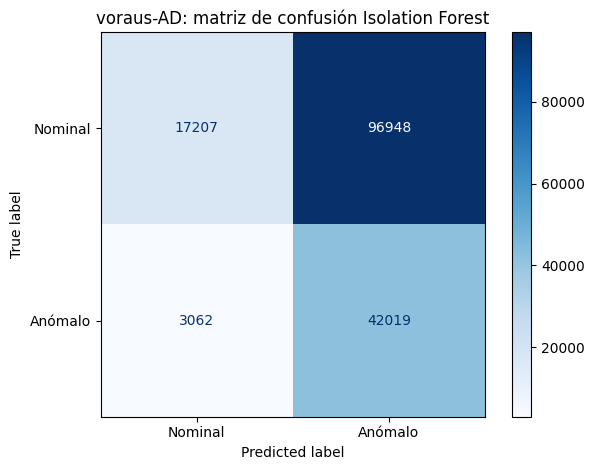

In [51]:

# ====================================================
# SECCIÓN 12.3 - Isolation Forest con etiquetas
# ====================================================

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import numpy as np
import matplotlib.pyplot as plt

# 1. Entrenar exclusivamente con datos nominales
modelo_if_v = IsolationForest(
    n_estimators=200,
    max_samples=2048,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

modelo_if_v.fit(X_train_v)

print("Isolation Forest entrenado correctamente")

# 2. Calcular puntuaciones de anomalía
# Mayor puntuación = mayor grado de anomalía
scores_val_if = -modelo_if_v.score_samples(X_val_v)

# 3. Seleccionar umbral utilizando validación
precision, recall, thresholds = precision_recall_curve(
    y_val_v,
    scores_val_if
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

mejor_indice = np.argmax(f1_scores)
umbral_if_v = thresholds[mejor_indice]

print("Umbral seleccionado:", round(umbral_if_v, 6))
print("F1 de validación:", round(f1_scores[mejor_indice], 4))

# 4. Evaluar sobre prueba independiente
scores_test_if = -modelo_if_v.score_samples(X_test_v)

pred_test_if = (
    scores_test_if >= umbral_if_v
).astype(int)

# 5. Calcular métricas
resultados_if = {
    "Modelo": "Isolation Forest",
    "Precision": precision_score(
        y_test_v, pred_test_if, zero_division=0
    ),
    "Recall": recall_score(
        y_test_v, pred_test_if, zero_division=0
    ),
    "F1": f1_score(
        y_test_v, pred_test_if, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test_v, scores_test_if
    ),
    "PR-AUC (AP)": average_precision_score(
        y_test_v, scores_test_if
    )
}

print("\n=== EVALUACIÓN EN PRUEBA ===")

for nombre, valor in resultados_if.items():
    if nombre == "Modelo":
        print(nombre, ":", valor)
    else:
        print(nombre, ":", round(valor, 4))

# 6. Matriz de confusión
cm_if = confusion_matrix(
    y_test_v,
    pred_test_if,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_if,
    display_labels=["Nominal", "Anómalo"]
).plot(cmap="Blues", values_format="d")

plt.title("voraus-AD: matriz de confusión Isolation Forest")
plt.tight_layout()

plt.savefig(
    "voraus_matriz_confusion_isolation_forest.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 12.3.1. Interpretación de los resultados de Isolation Forest

El modelo Isolation Forest fue entrenado exclusivamente con registros nominales del dataset voraus-AD y evaluado sobre 159 236 registros pertenecientes a 146 ensayos independientes.

Se obtuvo una precisión de 0,3024, un recall de 0,9321 y un F1-score de 0,4566.

La matriz de confusión mostró 42 019 verdaderos positivos, 17 207 verdaderos negativos, 96 948 falsos positivos y 3 062 falsos negativos.

Aunque el modelo identificó el 93,21 % de las mediciones etiquetadas como anómalas, también clasificó incorrectamente como anómalas una proporción elevada de mediciones nominales.

El ROC-AUC de 0,5234 y el Average Precision de 0,2975 muestran una capacidad de discriminación limitada para este experimento.

Estos resultados evidencian que un recall elevado no garantiza un detector confiable cuando existen numerosas falsas alarmas.

El rendimiento debe interpretarse considerando que las métricas se calcularon por registro y que las observaciones de un mismo ensayo presentan dependencia temporal.


### 12.4. Detección de anomalías mediante TensorFlow/Keras

Se implementa una red neuronal autoencoder para analizar el comportamiento de las 24 variables operativas del dataset voraus-AD.

El autoencoder utiliza una arquitectura completamente conectada que comprime las características de entrada en una representación latente y posteriormente intenta reconstruirlas.

El entrenamiento se realiza exclusivamente con mediciones nominales, sin utilizar las etiquetas como entradas al modelo.

Para evitar utilizar el conjunto de prueba durante el desarrollo, se reserva una parte de los ensayos nominales de entrenamiento para la validación interna de la red neuronal.

Posteriormente, las etiquetas del conjunto de validación se utilizan para seleccionar un umbral de detección que maximice el F1-score.

La evaluación final se realiza sobre los mismos 159 236 registros de prueba utilizados con Isolation Forest.

Se calculan precision, recall, F1-score, ROC-AUC, Average Precision y la matriz de confusión.

In [52]:
# =====================================================
# SECCIÓN 12.4.1 - Preparación para TensorFlow/Keras
# =====================================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

import numpy as np
import matplotlib.pyplot as plt

# Reproducibilidad
tf.keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__)

# 1. Recuperar identificadores de ensayos nominales
grupos_nominales = (
    df_train_normal_v["sample"].to_numpy()
)

# 2. Dividir por ensayos completos
separador = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

indices_ajuste, indices_val_interna = next(
    separador.split(
        X_train_raw_v,
        groups=grupos_nominales
    )
)

# 3. Comprobar separación
ids_ajuste = set(
    grupos_nominales[indices_ajuste]
)

ids_val_interna = set(
    grupos_nominales[indices_val_interna]
)

assert ids_ajuste.isdisjoint(ids_val_interna)

# 4. Ajustar un escalador propio para el autoencoder
# exclusivamente con los ensayos de ajuste
scaler_ae_v = StandardScaler()

X_ajuste_v = scaler_ae_v.fit_transform(
    X_train_raw_v[indices_ajuste]
).astype(np.float32)

X_val_interna_v = scaler_ae_v.transform(
    X_train_raw_v[indices_val_interna]
).astype(np.float32)

# 5. Transformar validación externa y prueba
X_val_ae_v = scaler_ae_v.transform(
    X_val_raw_v
).astype(np.float32)

X_test_ae_v = scaler_ae_v.transform(
    X_test_raw_v
).astype(np.float32)

# 6. Validaciones
assert X_ajuste_v.shape[1] == len(variables_finales_v)
assert X_val_interna_v.shape[1] == len(variables_finales_v)

for matriz in [
    X_ajuste_v,
    X_val_interna_v,
    X_val_ae_v,
    X_test_ae_v
]:
    assert np.isfinite(matriz).all()

print("\n=== AUTOENCODER: DATOS PREPARADOS ===")
print("Ajuste:", X_ajuste_v.shape)
print("Validación interna:", X_val_interna_v.shape)
print("Validación externa:", X_val_ae_v.shape)
print("Prueba:", X_test_ae_v.shape)

print("Ensayos de ajuste:", len(ids_ajuste))
print("Ensayos de validación interna:", len(ids_val_interna))
print("Separación por ensayo: CORRECTA")


TensorFlow: 2.21.0

=== AUTOENCODER: DATOS PREPARADOS ===
Ajuste: (453023, 24)
Validación interna: (80640, 24)
Validación externa: (159493, 24)
Prueba: (159236, 24)
Ensayos de ajuste: 416
Ensayos de validación interna: 74
Separación por ensayo: CORRECTA


#### 12.4.2. Arquitectura y entrenamiento del autoencoder

Se define un autoencoder denso con 24 características de entrada y una representación latente de ocho neuronas.

La arquitectura incorpora capas de codificación y decodificación de 16 neuronas.

Se emplea el optimizador Adam y el error cuadrático medio como función de pérdida.

El entrenamiento se realiza mediante un máximo de 80 épocas, utilizando EarlyStopping para recuperar los pesos asociados al menor error de validación interna.

La validación interna utiliza ensayos nominales independientes de los utilizados para ajustar los pesos de la red.

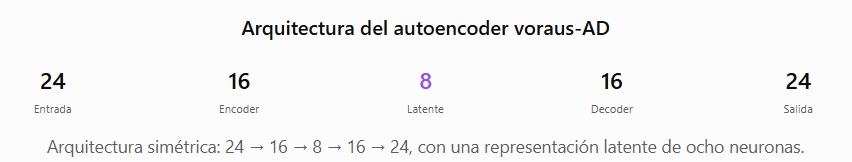

In [53]:
# =====================================================
# SECCIÓN 12.4.2 - Entrenamiento del autoencoder
# =====================================================

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

n_entradas = X_ajuste_v.shape[1]

# Arquitectura
entrada_v = keras.Input(
    shape=(n_entradas,),
    name="telemetria"
)

x = layers.Dense(
    16, activation="relu"
)(entrada_v)

latente_v = layers.Dense(
    8,
    activation="linear",
    name="representacion_latente"
)(x)

x = layers.Dense(
    16, activation="relu"
)(latente_v)

salida_v = layers.Dense(
    n_entradas,
    activation="linear",
    name="reconstruccion"
)(x)

autoencoder_v = keras.Model(
    entrada_v,
    salida_v,
    name="Voraus_AD_Autoencoder"
)

# Configurar entrenamiento
autoencoder_v.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse"
)

autoencoder_v.summary()

# Early stopping
early_stop_v = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    min_delta=0.00001,
    restore_best_weights=True
)

# Entrenamiento
historial_v = autoencoder_v.fit(
    X_ajuste_v,
    X_ajuste_v,
    validation_data=(
        X_val_interna_v,
        X_val_interna_v
    ),
    epochs=80,
    batch_size=256,
    shuffle=True,
    callbacks=[early_stop_v],
    verbose=1
)

print("\nAUTOENCODER ENTRENADO CORRECTAMENTE")
print(
    "Épocas ejecutadas:",
    len(historial_v.history["loss"])
)
print(
    "Mejor MSE de validación interna:",
    round(
        min(historial_v.history["val_loss"]),
        6
    )
)


Model: "Voraus_AD_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ telemetria (InputLayer)         │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ representacion_latente (Dense)  │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruccion (Dense)          │ (None, 24)             │           408 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,088 (4.25 KB)

 Trainable params: 1,088 (4.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/80
1770/1770 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.1150 - val_loss: 0.0250
Epoch 2/80
1770/1770 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0212 - val_loss: 0.0179
Epoch 3/80
1770/1770 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0162 - val_loss: 0.0138
Epoch 4/80
1770/1770 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0131 - val_loss: 0.0117
Epoch 5/80
1770/1770 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0114 - val_loss: 0.0103
Epoch 6/80
1770/1770 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0102 - val_loss: 0.0094
Epoch 7/80
1770/1770 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0095 - val_loss: 0.0089
Epoch 8/80
1770/1770 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0091 - val_loss: 0.0086
Epoch 9/80
1770/1770 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0089 - val_loss: 0.0084
Epoch 10/80
1770/1770 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0086 - val_loss: 0.0082
Epoch 11/80
1770/1770 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0085 - val_loss: 0.0080
Epoch 12/80
1770/1770 ━━━━━━━━


#### 12.4.3. Análisis del proceso de entrenamiento

Se representa la evolución del error cuadrático medio durante el entrenamiento y la validación interna.

La comparación permite analizar la convergencia del autoencoder e identificar posibles diferencias entre el ajuste y la capacidad de reconstrucción sobre ensayos nominales independientes.


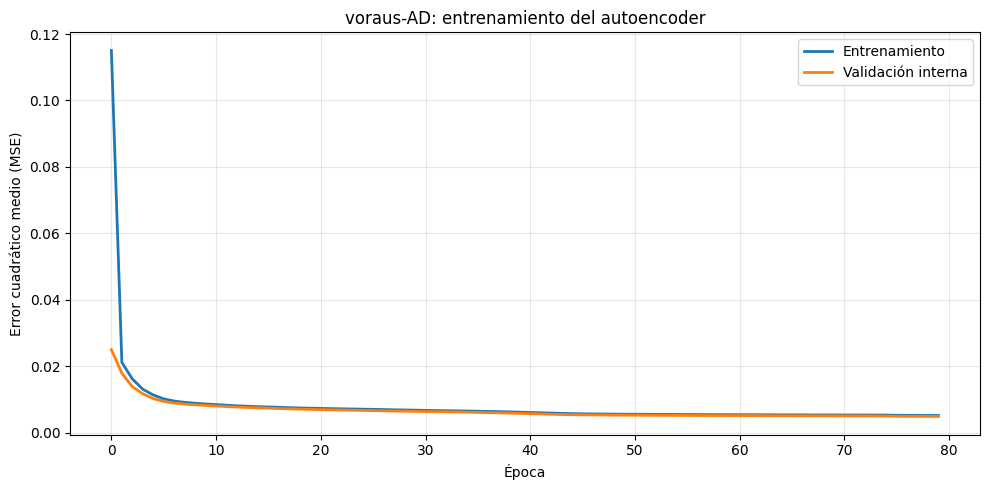

In [54]:

# =====================================================
# SECCIÓN 12.4.3 - Curvas de entrenamiento
# =====================================================

plt.figure(figsize=(10, 5))

plt.plot(
    historial_v.history["loss"],
    label="Entrenamiento",
    linewidth=2
)

plt.plot(
    historial_v.history["val_loss"],
    label="Validación interna",
    linewidth=2
)

plt.title(
    "voraus-AD: entrenamiento del autoencoder"
)

plt.xlabel("Época")
plt.ylabel("Error cuadrático medio (MSE)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "voraus_entrenamiento_autoencoder.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



#### 12.4.4. Calibración y evaluación del autoencoder

Las mediciones de validación y prueba se reconstruyen mediante la red neuronal entrenada.

Para cada registro se calcula el error cuadrático medio entre las características originales y las reconstruidas.

El umbral de clasificación se selecciona utilizando las etiquetas del conjunto de validación mediante la maximización de F1-score.

Posteriormente, dicho umbral se aplica al conjunto de prueba independiente.

Se calculan precision, recall, F1-score, ROC-AUC y Average Precision, además de la matriz de confusión.

El proceso de calibración utiliza etiquetas de referencia, mientras que el entrenamiento de la red se realiza únicamente con mediciones nominales.

Umbral AE: 0.000227
F1 validación: 0.4536

=== AUTOENCODER: PRUEBA FINAL ===
Modelo : Autoencoder
Precision : 0.2939
Recall : 0.929
F1 : 0.4465
ROC-AUC : 0.524
PR-AUC (AP) : 0.298


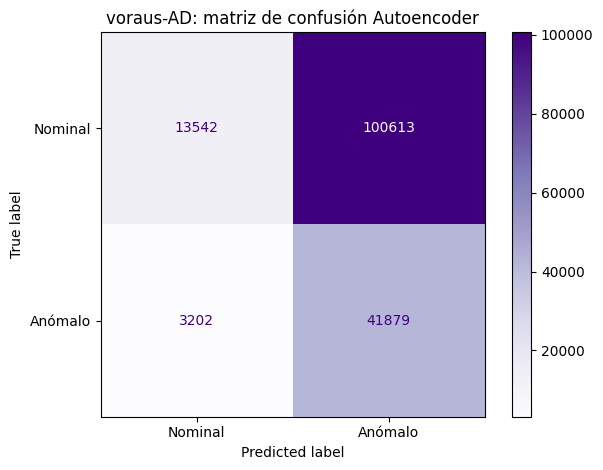

In [55]:

# =====================================================
# SECCIÓN 12.4.4 - Evaluación con etiquetas
# =====================================================

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Reconstrucciones de validación
recon_val_v = autoencoder_v.predict(
    X_val_ae_v,
    batch_size=1024,
    verbose=0
)

# Mayor error = mayor puntuación de anomalía
scores_val_ae = np.mean(
    np.square(X_val_ae_v - recon_val_v),
    axis=1
)

# 2. Selección del umbral
precision_ae, recall_ae, umbrales_ae = (
    precision_recall_curve(
        y_val_v,
        scores_val_ae
    )
)

f1_ae = (
    2 * precision_ae[:-1] * recall_ae[:-1]
    / (
        precision_ae[:-1]
        + recall_ae[:-1]
        + 1e-12
    )
)

indice_ae = np.argmax(f1_ae)
umbral_ae_v = umbrales_ae[indice_ae]

print(
    "Umbral AE:",
    round(float(umbral_ae_v), 6)
)

print(
    "F1 validación:",
    round(float(f1_ae[indice_ae]), 4)
)

# 3. Reconstrucciones de prueba
recon_test_v = autoencoder_v.predict(
    X_test_ae_v,
    batch_size=1024,
    verbose=0
)

scores_test_ae = np.mean(
    np.square(X_test_ae_v - recon_test_v),
    axis=1
)

pred_test_ae = (
    scores_test_ae >= umbral_ae_v
).astype(int)

# 4. Métricas finales
resultados_ae = {
    "Modelo": "Autoencoder",
    "Precision": precision_score(
        y_test_v,
        pred_test_ae,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test_v,
        pred_test_ae,
        zero_division=0
    ),
    "F1": f1_score(
        y_test_v,
        pred_test_ae,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test_v,
        scores_test_ae
    ),
    "PR-AUC (AP)": average_precision_score(
        y_test_v,
        scores_test_ae
    )
}

print("\n=== AUTOENCODER: PRUEBA FINAL ===")

for nombre, valor in resultados_ae.items():
    if nombre == "Modelo":
        print(nombre, ":", valor)
    else:
        print(nombre, ":", round(valor, 4))

# 5. Matriz de confusión
cm_ae = confusion_matrix(
    y_test_v,
    pred_test_ae,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_ae,
    display_labels=["Nominal", "Anómalo"]
).plot(
    cmap="Purples",
    values_format="d"
)

plt.title(
    "voraus-AD: matriz de confusión Autoencoder"
)

plt.tight_layout()

plt.savefig(
    "voraus_matriz_confusion_autoencoder.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 12.5. Comparación cuantitativa de los modelos

Se comparan los resultados de Isolation Forest y el autoencoder sobre el mismo conjunto de prueba etiquetado.

Ambos modelos utilizan las mismas 24 variables operativas y la misma separación de ensayos.

Los umbrales de detección se seleccionaron mediante el conjunto de validación, utilizando la maximización del F1-score.

La comparación considera precision, recall, F1-score, ROC-AUC y Average Precision.

Las métricas permiten estudiar las diferencias de desempeño entre los dos enfoques. Sin embargo, la evaluación corresponde al subconjunto experimental seleccionado y no demuestra generalización a otros robots o condiciones operativas.


,Modelo,Precision,Recall,F1,ROC-AUC,PR-AUC (AP)
0,Isolation Forest,0.3024,0.9321,0.4566,0.5234,0.2975
1,Autoencoder,0.2939,0.9290,0.4465,0.5240,0.2980


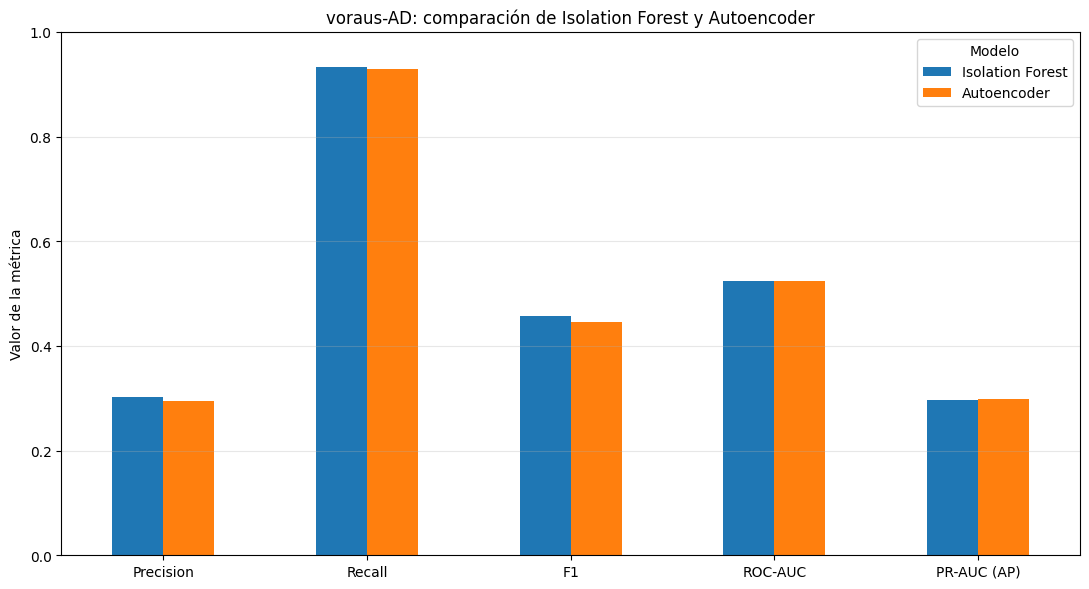

Comparación generada correctamente


In [56]:
# =====================================================
# SECCIÓN 12.5 - Comparación de modelos
# =====================================================

import pandas as pd
import matplotlib.pyplot as plt

# Tabla comparativa
df_comparacion_v = pd.DataFrame([
    resultados_if,
    resultados_ae
])

display(df_comparacion_v.round(4))

# Comparar métricas
metricas = [
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "PR-AUC (AP)"
]

grafico = df_comparacion_v.set_index(
    "Modelo"
)[metricas].T

ax = grafico.plot(
    kind="bar",
    figsize=(11, 6),
    rot=0
)

ax.set_title(
    "voraus-AD: comparación de Isolation Forest y Autoencoder"
)

ax.set_ylabel("Valor de la métrica")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Modelo")

plt.tight_layout()

plt.savefig(
    "voraus_comparacion_modelos_ia.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Guardar resultados
df_comparacion_v.to_csv(
    "voraus_resultados_comparativos.csv",
    index=False
)

print("Comparación generada correctamente")



### 12.5.1. Interpretación de la comparación experimental

La evaluación de Isolation Forest y del autoencoder se realizó sobre el mismo conjunto de prueba del dataset voraus-AD, compuesto por 159 236 registros pertenecientes a 146 ensayos independientes.

Isolation Forest obtuvo un F1-score de 0,4566, mientras que el autoencoder alcanzó 0,4465. Ambos modelos presentaron valores de recall superiores al 92 %, pero valores de precisión próximos al 30 %.

Las matrices de confusión evidenciaron una cantidad elevada de falsos positivos: 96 948 para Isolation Forest y 100 606 para el autoencoder.

Los valores de ROC-AUC, próximos a 0,52, y de Average Precision, próximos a 0,30, indican que ambos modelos presentan una capacidad limitada para discriminar las anomalías etiquetadas en el subconjunto evaluado.

Aunque el autoencoder consiguió reducir su error de reconstrucción hasta aproximadamente 0,00489 durante la validación interna, esta capacidad no se tradujo en una mejora significativa de la detección.

Estos resultados muestran que un modelo puede aprender adecuadamente patrones de reconstrucción sin necesariamente distinguir las anomalías operativas de forma confiable.

Las diferencias entre ambos enfoques fueron pequeñas y no permiten establecer una superioridad concluyente.

Como limitaciones se identifican la dependencia temporal entre mediciones del mismo ensayo, la ausencia de características temporales explícitas y la posible influencia de las condiciones de operación.

En consecuencia, se considera necesario complementar la evaluación por registro con un análisis por ensayo y por categoría de anomalía.



### 12.6. Evaluación por ensayo y categoría de anomalía

Las evaluaciones anteriores se realizaron a nivel de registro temporal. Sin embargo, las mediciones pertenecientes a un mismo ensayo no son estadísticamente independientes.

Por ello, se desarrolla una evaluación complementaria utilizando el identificador `sample` como unidad experimental.

Para cada ensayo se calcula el percentil 95 de las puntuaciones de anomalía generadas por Isolation Forest y el autoencoder.

Los umbrales de clasificación por ensayo se seleccionan mediante el conjunto de validación, maximizando el F1-score. Posteriormente, dichos umbrales se aplican al conjunto de prueba independiente.

También se analiza la tasa de detección de cada modelo para las 12 categorías de anomalías etiquetadas del dataset voraus-AD.

Finalmente, se compara el rendimiento de los modelos con una estrategia trivial que clasifica todas las mediciones como anómalas.

### 12.6.1. Agregación de puntuaciones por ensayo


In [57]:
# =========================================================
# SECCIÓN 12.6.1 - Agregación de puntuaciones por ensayo
# =========================================================

import numpy as np
import pandas as pd

def agregar_por_ensayo(df, scores, percentil=95):
    """Resume las puntuaciones por ensayo completo."""

    assert len(df) == len(scores)

    datos = df[
        ["sample", "anomaly", "category"]
    ].copy()

    datos["score"] = np.asarray(scores)

    resultado = (
        datos.groupby("sample")
        .agg(
            anomaly=("anomaly", "first"),
            category=("category", "first"),
            score_ensayo=(
                "score",
                lambda x: np.percentile(x, percentil)
            ),
            registros=("score", "size")
        )
        .reset_index()
    )

    return resultado

# Isolation Forest
ensayos_val_if = agregar_por_ensayo(
    df_val_v, scores_val_if
)

ensayos_test_if = agregar_por_ensayo(
    df_test_v, scores_test_if
)

# Autoencoder
ensayos_val_ae = agregar_por_ensayo(
    df_val_v, scores_val_ae
)

ensayos_test_ae = agregar_por_ensayo(
    df_test_v, scores_test_ae
)

# Validaciones
assert len(ensayos_val_if) == 146
assert len(ensayos_test_if) == 146
assert len(ensayos_val_ae) == 146
assert len(ensayos_test_ae) == 146

assert (
    ensayos_test_if["sample"].to_numpy()
    == ensayos_test_ae["sample"].to_numpy()
).all()

print("Ensayos de validación:", len(ensayos_val_if))
print("Ensayos de prueba:", len(ensayos_test_if))

print("\nDistribución de ensayos en prueba:")
print(
    ensayos_test_if["anomaly"].value_counts()
)

display(ensayos_test_if.head())

print("\nAGREGACIÓN COMPLETADA")


Ensayos de validación: 146
Ensayos de prueba: 146

Distribución de ensayos en prueba:
anomaly
False    105
True      41
Name: count, dtype: int64


,sample,anomaly,category,score_ensayo,registros
0,3,True,0,0.535011,1096
1,20,True,0,0.543849,1137
2,56,True,0,0.539893,1110
3,127,True,0,0.543972,1123
4,160,True,1,0.544128,1151



AGREGACIÓN COMPLETADA


### 12.6.2. Evaluación de los modelos por ensayo completo

Se utilizan las puntuaciones agregadas de cada ensayo para obtener una clasificación binaria.

El umbral de decisión se selecciona exclusivamente sobre los 146 ensayos de validación, maximizando el F1-score.

Posteriormente, se aplica a los 146 ensayos de prueba sin realizar nuevos ajustes.

Se calculan precision, recall, F1-score, ROC-AUC, Average Precision y matrices de confusión.


=== UMBRALES POR ENSAYO ===
Isolation Forest: 0.5379723202810912
Autoencoder: 0.012212906032800674

=== RESULTADOS POR ENSAYO ===


,Modelo,Precision,Recall,F1,ROC-AUC,AP
0,Isolation Forest,0.3947,0.7317,0.5128,0.6778,0.4695
1,Autoencoder,0.3015,1.0000,0.4633,0.5828,0.3772


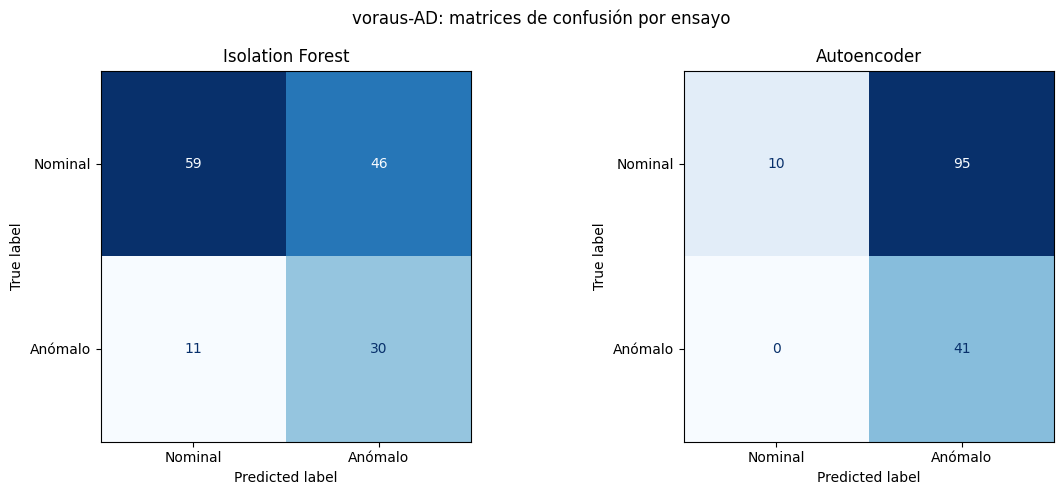

In [58]:
# SECCIÓN 12.6.2 - Evaluación por ensayo

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

def evaluar_ensayos(df_val, df_test, nombre):
    y_val = df_val["anomaly"].astype(int).to_numpy()
    y_test = df_test["anomaly"].astype(int).to_numpy()

    scores_val = df_val["score_ensayo"].to_numpy()
    scores_test = df_test["score_ensayo"].to_numpy()

    # Calibrar únicamente en validación
    precision, recall, umbrales = precision_recall_curve(
        y_val, scores_val
    )

    f1_val = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )

    indice = np.argmax(f1_val)
    umbral = float(umbrales[indice])

    # Evaluación independiente
    pred = (scores_test >= umbral).astype(int)

    metricas = {
        "Modelo": nombre,
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, scores_test
        ),
        "AP": average_precision_score(
            y_test, scores_test
        )
    }

    return umbral, pred, metricas

# Evaluar Isolation Forest
umbral_ensayo_if, pred_ensayo_if, metricas_ensayo_if = (
    evaluar_ensayos(
        ensayos_val_if,
        ensayos_test_if,
        "Isolation Forest"
    )
)

# Evaluar Autoencoder
umbral_ensayo_ae, pred_ensayo_ae, metricas_ensayo_ae = (
    evaluar_ensayos(
        ensayos_val_ae,
        ensayos_test_ae,
        "Autoencoder"
    )
)

# Tabla comparativa
df_metricas_ensayo = pd.DataFrame([
    metricas_ensayo_if,
    metricas_ensayo_ae
])

print("=== UMBRALES POR ENSAYO ===")
print("Isolation Forest:", umbral_ensayo_if)
print("Autoencoder:", umbral_ensayo_ae)

print("\n=== RESULTADOS POR ENSAYO ===")
display(df_metricas_ensayo.round(4))

# Matrices de confusión
y_ensayos = (
    ensayos_test_if["anomaly"]
    .astype(int)
    .to_numpy()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, pred, nombre in [
    (axes[0], pred_ensayo_if, "Isolation Forest"),
    (axes[1], pred_ensayo_ae, "Autoencoder")
]:
    cm = confusion_matrix(
        y_ensayos, pred, labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Nominal", "Anómalo"]
    )
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nombre)

plt.suptitle(
    "voraus-AD: matrices de confusión por ensayo"
)
plt.tight_layout()

plt.savefig(
    "voraus_matrices_confusion_por_ensayo.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 12.6.3. Análisis de detección por categoría de anomalía

Se analiza la tasa de detección de Isolation Forest y del autoencoder para cada una de las 12 categorías de anomalías etiquetadas del dataset voraus-AD.

Las categorías se identifican mediante los códigos originales 0 a 11, mientras que la categoría 12 representa funcionamiento nominal.

Para cada categoría anómala se calcula la proporción de registros correctamente detectados por ambos modelos.

Esta proporción corresponde al recall por categoría y no a la precisión, ya que la precisión requiere considerar también las falsas alarmas.

La comparación permite identificar qué categorías resultan más difíciles de reconocer para cada algoritmo.


=== DETECCIÓN POR CATEGORÍA ===


,category,registros,ensayos,recall_if,recall_ae
0,0,4466,4,0.9304,0.9299
1,1,4439,4,0.9811,0.9743
2,2,4392,4,0.9645,0.9415
3,3,4399,4,0.9023,0.8897
4,4,3437,3,0.8487,0.8633
5,5,2083,2,0.8968,0.9337
6,6,4344,4,0.8911,0.8854
7,7,4398,4,0.9518,0.9427
8,8,2178,2,0.9780,0.8834
9,9,2192,2,0.9343,0.9334


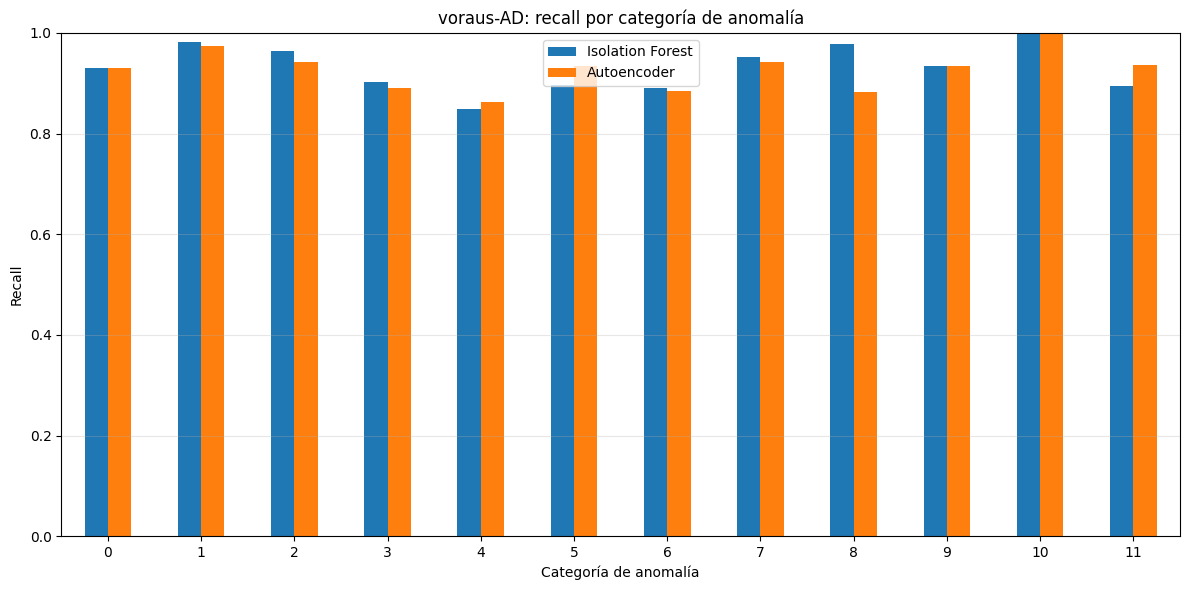

In [59]:
# SECCIÓN 12.6.3 - Resultados por categoría

import pandas as pd
import matplotlib.pyplot as plt

assert len(df_test_v) == len(pred_test_if)
assert len(df_test_v) == len(pred_test_ae)

df_categorias = df_test_v[
    ["sample", "category", "anomaly"]
].copy()

df_categorias["pred_if"] = pred_test_if
df_categorias["pred_ae"] = pred_test_ae

# Analizar únicamente categorías anómalas
df_anomalias_v = df_categorias[
    df_categorias["anomaly"] == True
].copy()

resumen_categorias = (
    df_anomalias_v
    .groupby("category")
    .agg(
        registros=("anomaly", "size"),
        ensayos=("sample", "nunique"),
        recall_if=("pred_if", "mean"),
        recall_ae=("pred_ae", "mean")
    )
    .reset_index()
)

assert set(resumen_categorias["category"]) == set(range(12))

print("=== DETECCIÓN POR CATEGORÍA ===")
display(resumen_categorias.round(4))

# Gráfico
ax = resumen_categorias.plot(
    x="category",
    y=["recall_if", "recall_ae"],
    kind="bar",
    figsize=(12, 6),
    rot=0
)

ax.set_title(
    "voraus-AD: recall por categoría de anomalía"
)

ax.set_xlabel("Categoría de anomalía")
ax.set_ylabel("Recall")
ax.set_ylim(0, 1)
ax.legend(["Isolation Forest", "Autoencoder"])
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "voraus_recall_por_categoria.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 12.6.4. Comparación con una línea base trivial

Para contextualizar el rendimiento de los algoritmos, se implementa una estrategia de referencia que clasifica todos los registros de prueba como anómalos.

Se comparan sus métricas de precision, recall y F1-score con las obtenidas por Isolation Forest y el autoencoder.

Esta comprobación permite determinar si los modelos producen mejoras relevantes respecto a una decisión trivial, especialmente cuando el conjunto de datos presenta diferencias en la proporción de registros nominales y anómalos.


=== COMPARACIÓN CON LÍNEA BASE ===


,Modelo,Precision,Recall,F1
0,Isolation Forest,0.3024,0.9321,0.4566
1,Autoencoder,0.2939,0.9290,0.4465
2,Siempre anómalo,0.2831,1.0000,0.4413


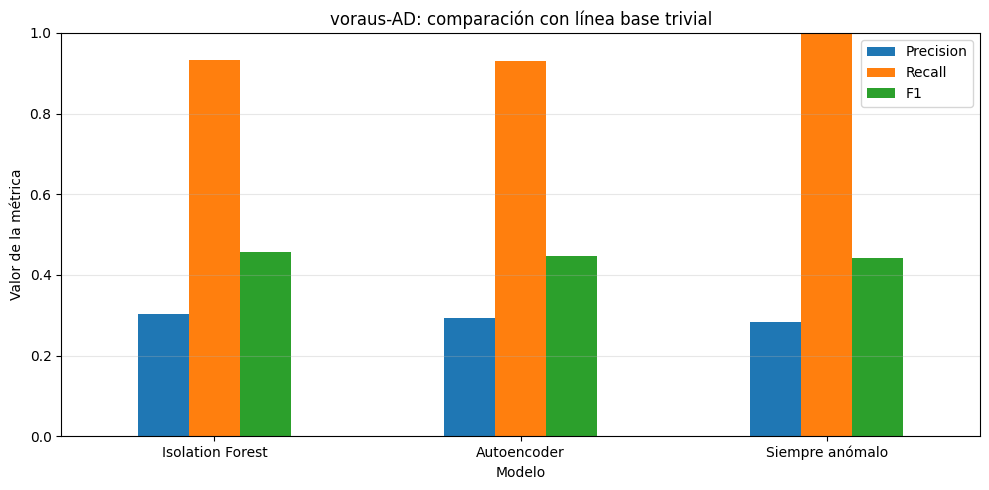

In [60]:
# SECCIÓN 12.6.4 - Línea base trivial

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Clasificador que siempre predice anomalía
pred_baseline = np.ones_like(y_test_v)

baseline = {
    "Modelo": "Siempre anómalo",
    "Precision": precision_score(
        y_test_v, pred_baseline
    ),
    "Recall": recall_score(
        y_test_v, pred_baseline
    ),
    "F1": f1_score(
        y_test_v, pred_baseline
    )
}

# Comparar los tres métodos
df_linea_base = pd.DataFrame([
    {
        "Modelo": resultados_if["Modelo"],
        "Precision": resultados_if["Precision"],
        "Recall": resultados_if["Recall"],
        "F1": resultados_if["F1"]
    },
    {
        "Modelo": resultados_ae["Modelo"],
        "Precision": resultados_ae["Precision"],
        "Recall": resultados_ae["Recall"],
        "F1": resultados_ae["F1"]
    },
    baseline
])

print("=== COMPARACIÓN CON LÍNEA BASE ===")
display(df_linea_base.round(4))

# Gráfico comparativo
ax = df_linea_base.set_index(
    "Modelo"
)[["Precision", "Recall", "F1"]].plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title(
    "voraus-AD: comparación con línea base trivial"
)

ax.set_ylabel("Valor de la métrica")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "voraus_comparacion_linea_base.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [61]:
# SECCIÓN 12.6.5 - Exportar resultados

from pathlib import Path

SALIDA_V = Path("/content/voraus_resultados")
SALIDA_V.mkdir(exist_ok=True)

df_metricas_ensayo.to_csv(
    SALIDA_V / "metricas_por_ensayo.csv",
    index=False
)

resumen_categorias.to_csv(
    SALIDA_V / "recall_por_categoria.csv",
    index=False
)

df_linea_base.to_csv(
    SALIDA_V / "comparacion_linea_base.csv",
    index=False
)

# Predicciones por ensayo
df_pred_ensayos = ensayos_test_if[
    ["sample", "anomaly", "category"]
].copy()

df_pred_ensayos["score_if"] = (
    ensayos_test_if["score_ensayo"]
)
df_pred_ensayos["score_ae"] = (
    ensayos_test_ae["score_ensayo"]
)
df_pred_ensayos["pred_if"] = pred_ensayo_if
df_pred_ensayos["pred_ae"] = pred_ensayo_ae

df_pred_ensayos.to_csv(
    SALIDA_V / "predicciones_por_ensayo.csv",
    index=False
)

print("Archivos generados:")
for archivo in SALIDA_V.iterdir():
    print("-", archivo.name)


Archivos generados:
- comparacion_linea_base.csv
- predicciones_por_ensayo.csv
- metricas_por_ensayo.csv
- recall_por_categoria.csv



### 12.7. Discusión de los resultados experimentales

La evaluación de los modelos Isolation Forest y Autoencoder sobre el dataset voraus-AD permitió comparar el rendimiento de dos técnicas de inteligencia artificial frente a etiquetas conocidas de anomalías.

**Evaluación por registro**

Isolation Forest obtuvo un F1-score de 0,4566 y un ROC-AUC de 0,5234. El autoencoder alcanzó un F1-score de 0,4465 y un ROC-AUC de 0,5240.

Ambos modelos presentaron un recall elevado, superior al 92 %, pero también una cantidad considerable de falsos positivos. Estos resultados evidencian que la detección de una gran proporción de anomalías no garantiza un sistema de supervisión confiable.

**Evaluación por ensayo**

Al agregar las puntuaciones mediante el percentil 95 de cada ensayo, Isolation Forest alcanzó un F1-score de 0,5128 y un ROC-AUC de 0,6778.

Por su parte, el autoencoder obtuvo un F1-score de 0,4633 y un ROC-AUC de 0,5828.

Isolation Forest identificó correctamente 30 de los 41 ensayos anómalos, mientras que el autoencoder identificó los 41. Sin embargo, el autoencoder también generó 95 falsas alarmas entre los 105 ensayos nominales, frente a las 46 de Isolation Forest.

**Evaluación por categoría**

Los modelos presentaron tasas elevadas de detección en las doce categorías de anomalías inducidas. Sin embargo, algunas categorías cuentan con pocos ensayos de prueba, lo que limita la generalización de los resultados.

**Comparación con la línea base**

Los resultados por registro de ambos algoritmos superaron ligeramente la línea base que clasifica todas las observaciones como anómalas.

Esto demuestra la importancia de utilizar métricas adicionales al recall, especialmente precision, F1-score, ROC-AUC y Average Precision.

**Limitaciones**

- La evaluación corresponde a un subconjunto de 995 ensayos seleccionados del dataset original.
- Las métricas por registro están afectadas por la dependencia temporal de las mediciones.
- Se utilizaron únicamente características instantáneas, sin modelar explícitamente secuencias temporales.
- La separación por ensayo evita compartir ejecuciones entre conjuntos, pero no garantiza independencia respecto de condiciones experimentales similares.
- Los umbrales fueron calibrados utilizando etiquetas del conjunto de validación.
- No se realizó una evaluación de robustez frente a múltiples particiones o semillas aleatorias.

**Conclusión experimental**

En las condiciones evaluadas, Isolation Forest presentó un mejor equilibrio entre detección de anomalías y falsas alarmas a nivel de ensayo.

El autoencoder alcanzó una mayor sensibilidad, pero su elevada tasa de falsos positivos limita su utilidad como detector autónomo.

Los resultados evidencian que la selección del algoritmo, las características utilizadas y la definición de la unidad de evaluación influyen en el desempeño de los sistemas de detección de anomalías.

La disponibilidad de etiquetas permitió identificar estas limitaciones, algo que no era posible realizar en el experimento inicial con la telemetría del Unitree Go1.


In [62]:
# SECCIÓN 12.8 - Guardar resultados en Google Drive

from pathlib import Path
import shutil

origen = Path("/content/voraus_resultados")

destino = (
    CARPETA_TRABAJO
    / "dataset_voraus_AD"
    / "resultados_modelos"
)

destino.mkdir(parents=True, exist_ok=True)

# Copiar tablas de resultados
for archivo in origen.glob("*.csv"):
    shutil.copy2(archivo, destino / archivo.name)
    print("Guardado:", archivo.name)

# Guardar gráficas existentes
graficos = [
    "voraus_matriz_confusion_isolation_forest.png",
    "voraus_entrenamiento_autoencoder.png",
    "voraus_matriz_confusion_autoencoder.png",
    "voraus_comparacion_modelos_ia.png",
    "voraus_matrices_confusion_por_ensayo.png",
    "voraus_recall_por_categoria.png",
    "voraus_comparacion_linea_base.png"
]

for nombre in graficos:
    archivo = Path("/content") / nombre

    if archivo.exists():
        shutil.copy2(archivo, destino / nombre)
        print("Gráfico guardado:", nombre)
    else:
        print("Gráfico no encontrado:", nombre)

# Guardar modelos entrenados
import joblib

joblib.dump(
    {"modelo": modelo_if_v, "scaler": scaler_v,
     "variables": variables_finales_v,
     "umbral_registro": umbral_if_v},
    destino / "isolation_forest_voraus.joblib"
)

autoencoder_v.save(
    destino / "autoencoder_voraus.keras"
)

print("\nRESULTADOS GUARDADOS EN GOOGLE DRIVE")
print("Destino:", destino)


Guardado: comparacion_linea_base.csv
Guardado: predicciones_por_ensayo.csv
Guardado: metricas_por_ensayo.csv
Guardado: recall_por_categoria.csv
Gráfico guardado: voraus_matriz_confusion_isolation_forest.png
Gráfico guardado: voraus_entrenamiento_autoencoder.png
Gráfico guardado: voraus_matriz_confusion_autoencoder.png
Gráfico guardado: voraus_comparacion_modelos_ia.png
Gráfico guardado: voraus_matrices_confusion_por_ensayo.png
Gráfico guardado: voraus_recall_por_categoria.png
Gráfico guardado: voraus_comparacion_linea_base.png

RESULTADOS GUARDADOS EN GOOGLE DRIVE
Destino: /content/drive/MyDrive/Maestria de IA aplicada UTPL/Herramientas para la IA/AAAB1_20%_Trabajo academico final escrito/dataset_voraus_AD/resultados_modelos


### 12.9. Diagnóstico y optimización de la detección por ensayo

Se analiza la influencia del umbral de clasificación sobre el rendimiento de Isolation Forest y del autoencoder.

La optimización se realiza exclusivamente utilizando los ensayos de validación, sin emplear las etiquetas de prueba.

Se comparan distintos criterios de calibración, incluyendo la maximización del F1-score y la selección de umbrales con restricciones sobre la tasa de falsos positivos.

El propósito es identificar configuraciones con un mejor equilibrio entre sensibilidad y falsas alarmas.


In [63]:
# SECCIÓN 12.9 - Optimización de umbrales
# Solo utilizamos el conjunto de VALIDACIÓN

import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

def analizar_umbrales(df, nombre):
    y = df["anomaly"].astype(int).to_numpy()
    scores = df["score_ensayo"].to_numpy()

    # Evaluar umbrales en validación
    umbrales = np.unique(
        np.quantile(scores, np.linspace(0, 1, 201))
    )

    filas = []

    for umbral in umbrales:
        pred = (scores >= umbral).astype(int)

        tn = np.sum((y == 0) & (pred == 0))
        fp = np.sum((y == 0) & (pred == 1))

        fpr = fp / (fp + tn)

        filas.append({
            "modelo": nombre,
            "umbral": umbral,
            "precision": precision_score(
                y, pred, zero_division=0
            ),
            "recall": recall_score(
                y, pred, zero_division=0
            ),
            "f1": f1_score(
                y, pred, zero_division=0
            ),
            "fpr": fpr
        })

    return pd.DataFrame(filas)

resultados_umbral = pd.concat([
    analizar_umbrales(
        ensayos_val_if, "Isolation Forest"
    ),
    analizar_umbrales(
        ensayos_val_ae, "Autoencoder"
    )
], ignore_index=True)

for nombre, grupo in resultados_umbral.groupby("modelo"):

    # Mejor F1 en validación
    mejor_f1 = grupo.loc[
        grupo["f1"].idxmax()
    ]

    # Mejor F1 con máximo 20 % de falsas alarmas
    candidatos = grupo[grupo["fpr"] <= 0.20]

    print("\nMODELO:", nombre)

    print("Mejor F1 sin restricción:")
    display(mejor_f1.to_frame().T)

    if not candidatos.empty:
        mejor_restringido = candidatos.loc[
            candidatos["f1"].idxmax()
        ]

        print("Mejor F1 con FPR <= 20 %:")
        display(mejor_restringido.to_frame().T)

    else:
        print("No se encontró configuración admisible")

print("\nDIAGNÓSTICO DE UMBRALES COMPLETADO")



MODELO: Autoencoder
Mejor F1 sin restricción:


,modelo,umbral,precision,recall,f1,fpr
215,Autoencoder,0.012183,0.303704,1.0,0.465909,0.895238


Mejor F1 con FPR <= 20 %:


,modelo,umbral,precision,recall,f1,fpr
370,Autoencoder,0.024304,0.478261,0.268293,0.34375,0.114286



MODELO: Isolation Forest
Mejor F1 sin restricción:


,modelo,umbral,precision,recall,f1,fpr
98,Isolation Forest,0.537866,0.405405,0.731707,0.521739,0.419048


Mejor F1 con FPR <= 20 %:


,modelo,umbral,precision,recall,f1,fpr
158,Isolation Forest,0.546316,0.548387,0.414634,0.472222,0.133333



DIAGNÓSTICO DE UMBRALES COMPLETADO


### 12.10. Diagnóstico de las condiciones operativas del dataset voraus-AD

Los modelos Isolation Forest y Autoencoder presentaron una elevada cantidad de falsos positivos durante la evaluación de anomalías.

Para investigar posibles causas, se analizan tres variables originales del dataset voraus-AD:

- `setting`: identificador de configuración experimental.
- `action`: identificador de acción operativa.
- `active`: indicador del estado de actividad.

Estas variables no fueron incluidas entre las 24 características utilizadas en los modelos iniciales.

El análisis busca identificar diferencias entre las condiciones operativas de ensayos nominales y anómalos, así como posibles relaciones entre estas variables y las etiquetas.

La evaluación es exploratoria y no implica necesariamente que las condiciones operativas sean la causa de las falsas alarmas.

### 12.10.1. Recuperación de metadatos desde el archivo Parquet original


In [64]:
# =====================================================
# SECCIÓN 12.10.1 - Recuperación de metadatos voraus-AD
# =====================================================

import pyarrow.parquet as pq
import pandas as pd
import numpy as np

RUTA_PARQUET = (
    CARPETA_TRABAJO
    / "dataset_voraus_AD"
    / "voraus-ad-dataset-100hz.parquet"
)

assert RUTA_PARQUET.is_file(), (
    f"No se encontró: {RUTA_PARQUET}"
)

columnas_meta = [
    "sample", "anomaly", "category",
    "setting", "action", "active"
]

# Leer por lotes solamente las columnas necesarias
parquet = pq.ParquetFile(RUTA_PARQUET)
bloques = []

for lote in parquet.iter_batches(
    batch_size=100000,
    columns=columnas_meta
):
    bloques.append(lote.to_pandas())

df_meta_v = pd.concat(
    bloques, ignore_index=True
)
del bloques

print("Registros originales:", len(df_meta_v))
print("Ensayos:", df_meta_v["sample"].nunique())

assert len(df_meta_v) == 2321690
assert df_meta_v["sample"].nunique() == 2122

# Obtener los ensayos de cada partición
mapa_particiones = {}

for nombre, df in [
    ("entrenamiento", df_train_v),
    ("validacion", df_val_v),
    ("prueba", df_test_v)
]:
    for sample_id in df["sample"].unique():
        assert sample_id not in mapa_particiones
        mapa_particiones[sample_id] = nombre

df_meta_v["particion"] = (
    df_meta_v["sample"].map(mapa_particiones)
)

# Trabajar solo con los 995 ensayos seleccionados
df_meta_piloto = df_meta_v.loc[
    df_meta_v["particion"].notna()
].copy()

assert len(df_meta_piloto) == (
    len(df_train_v) + len(df_val_v) + len(df_test_v)
)

print("\n=== PARTICIONES ===")
print(
    df_meta_piloto["particion"].value_counts()
)

print("\n=== PRIMEROS REGISTROS ===")
display(df_meta_piloto.head())

print("\nMETADATOS RECUPERADOS CORRECTAMENTE")


Registros originales: 2321690
Ensayos: 2122

=== PARTICIONES ===
particion
entrenamiento    768468
validacion       159493
prueba           159236
Name: count, dtype: int64

=== PRIMEROS REGISTROS ===


,sample,anomaly,category,setting,action,active,particion
0,0,True,0,0,0,0,entrenamiento
1,0,True,0,0,0,0,entrenamiento
2,0,True,0,0,0,0,entrenamiento
3,0,True,0,0,0,0,entrenamiento
4,0,True,0,0,0,0,entrenamiento



METADATOS RECUPERADOS CORRECTAMENTE


### 12.10.2. Variabilidad de las condiciones operativas

Se analiza el número de valores distintos de `setting`, `action` y `active` dentro de cada ensayo.

Posteriormente, se examina la relación entre estas variables y las etiquetas nominales o anómalas.

El objetivo es determinar si las condiciones operativas ofrecen información relevante para interpretar las diferencias detectadas por los modelos.


In [65]:
# =====================================================
# SECCIÓN 12.10.2 - Diagnóstico de condiciones operativas
# =====================================================

# 1. Variabilidad dentro de cada ensayo
df_variabilidad = (
    df_meta_piloto.groupby("sample")
    .agg(
        anomaly=("anomaly", "first"),
        category=("category", "first"),
        n_setting=("setting", "nunique"),
        n_action=("action", "nunique"),
        n_active=("active", "nunique")
    )
    .reset_index()
)

print("=== VARIABILIDAD POR ENSAYO ===")

for columna in ["n_setting", "n_action", "n_active"]:
    print(f"\n{columna}")
    print(
        df_variabilidad[columna]
        .value_counts()
        .sort_index()
    )

# 2. Distribución de setting frente a la etiqueta
print("\n=== SETTING VS ANOMALY ===")

tabla_setting = pd.crosstab(
    df_meta_piloto["setting"],
    df_meta_piloto["anomaly"]
)

tabla_setting.columns = [
    "Nominal", "Anómalo"
]

tabla_setting["Total"] = (
    tabla_setting["Nominal"]
    + tabla_setting["Anómalo"]
)

display(
    tabla_setting.sort_values(
        "Total", ascending=False
    ).head(20)
)

# 3. Distribución de action frente a la etiqueta
print("\n=== ACTION VS ANOMALY ===")

tabla_action = pd.crosstab(
    df_meta_piloto["action"],
    df_meta_piloto["anomaly"]
)

tabla_action.columns = [
    "Nominal", "Anómalo"
]

display(tabla_action)

# 4. Distribución de active frente a la etiqueta
print("\n=== ACTIVE VS ANOMALY ===")

tabla_active = pd.crosstab(
    df_meta_piloto["active"],
    df_meta_piloto["anomaly"]
)

tabla_active.columns = [
    "Nominal", "Anómalo"
]

display(tabla_active)

# 5. Configuraciones compartidas entre clases
configuraciones_compartidas = (
    (tabla_setting["Nominal"] > 0)
    & (tabla_setting["Anómalo"] > 0)
)

print(
    "\nConfiguraciones presentes en ambas clases:",
    int(configuraciones_compartidas.sum())
)

print(
    "Total de configuraciones:",
    len(tabla_setting)
)

print("\nDIAGNÓSTICO COMPLETADO")


=== VARIABILIDAD POR ENSAYO ===

n_setting
n_setting
1    995
Name: count, dtype: int64

n_action
n_action
14    748
15    247
Name: count, dtype: int64

n_active
n_active
2    995
Name: count, dtype: int64

=== SETTING VS ANOMALY ===


,Nominal,Anómalo,Total
setting,,,
72,537103,0,537103
73,164536,0,164536
75,25386,0,25386
74,21999,0,21999
71,0,16570,16570
61,0,13384,13384
40,0,13234,13234
76,13221,0,13221
45,0,11192,11192



=== ACTION VS ANOMALY ===


,Nominal,Anómalo
action,,
0,47917,20092
1,79306,33428
2,244517,107628
3,30734,12964
4,12693,5359
5,15501,6514
6,69877,28431
7,31523,13278
8,13098,5780



=== ACTIVE VS ANOMALY ===


,Nominal,Anómalo
active,,
0,474471,203666
1,287774,121286



Configuraciones presentes en ambas clases: 0
Total de configuraciones: 75

DIAGNÓSTICO COMPLETADO


### 12.11. Análisis de falsas alarmas por condición operativa

El análisis de los metadatos reveló que las 75 configuraciones experimentales identificadas mediante `setting` están asociadas exclusivamente a ensayos nominales o anómalos.

Por ello, se evita utilizar esta variable como predictor y se profundiza en el análisis de `action` y `active`.

Se estudia la tasa de falsos positivos de Isolation Forest y del autoencoder para identificar las acciones y estados de actividad que concentran las falsas alarmas.

Los resultados se interpretan como un diagnóstico exploratorio y no se utilizan para seleccionar hiperparámetros a partir del conjunto de prueba.


=== FALSAS ALARMAS POR ACCIÓN ===


,action,registros,ensayos,fpr_if,fpr_ae
0,0,7220,105,1.0000,1.0000
1,1,11892,105,1.0000,1.0000
2,2,36489,105,0.5284,0.6289
3,3,4596,105,1.0000,1.0000
4,4,1907,105,1.0000,1.0000
5,5,2330,105,1.0000,1.0000
6,6,10491,105,1.0000,1.0000
7,7,4725,105,1.0000,1.0000
8,8,1965,105,1.0000,1.0000
9,9,11679,105,1.0000,1.0000



=== FALSAS ALARMAS POR ACTIVIDAD ===


,active,registros,ensayos,fpr_if,fpr_ae
0,0,71038,105,0.7578,0.8094
1,1,43117,105,1.0000,1.0000


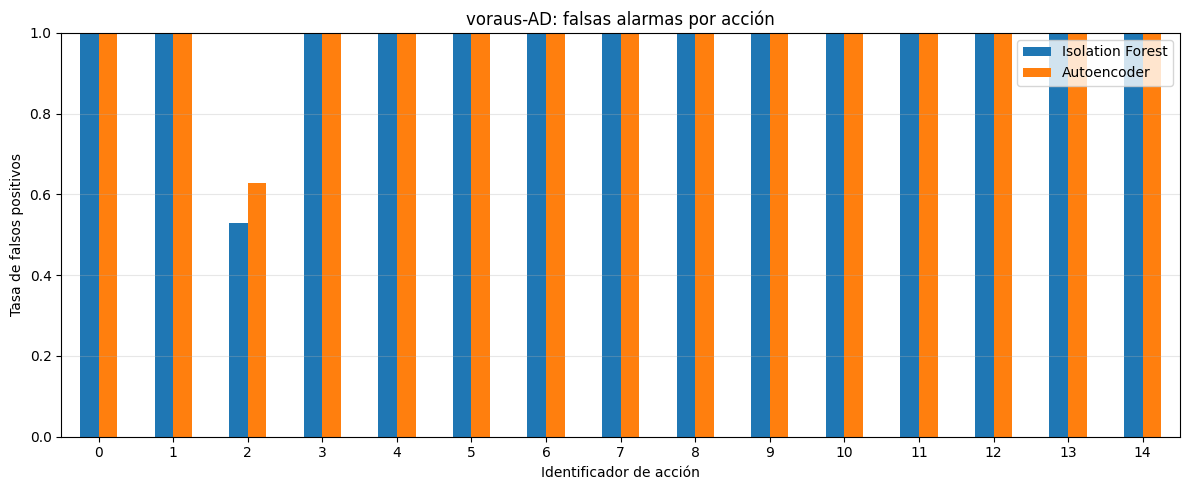


DIAGNÓSTICO OPERATIVO COMPLETADO


In [66]:
# SECCIÓN 12.11 - Diagnóstico por acción y actividad

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Recuperar metadatos de los ensayos de prueba
meta_test = df_meta_piloto.loc[
    df_meta_piloto["particion"] == "prueba",
    ["sample", "action", "active", "anomaly"]
].reset_index(drop=True)

# Verificar correspondencia con el CSV procesado
assert len(meta_test) == len(df_test_v)

assert np.array_equal(
    meta_test["sample"].to_numpy(),
    df_test_v["sample"].to_numpy()
), "El orden de los ensayos no coincide"

assert np.array_equal(
    meta_test["anomaly"].to_numpy(),
    df_test_v["anomaly"].to_numpy()
), "Las etiquetas no coinciden"

# Incorporar las predicciones ya calculadas
meta_test["pred_if"] = pred_test_if
meta_test["pred_ae"] = pred_test_ae

# Seleccionar únicamente las mediciones nominales
nominales = meta_test.loc[
    meta_test["anomaly"] == False
].copy()

# Calcular tasa de falsas alarmas por acción
fpr_accion = (
    nominales.groupby("action")
    .agg(
        registros=("sample", "size"),
        ensayos=("sample", "nunique"),
        fpr_if=("pred_if", "mean"),
        fpr_ae=("pred_ae", "mean")
    )
    .reset_index()
)

# Calcular tasa de falsas alarmas por actividad
fpr_actividad = (
    nominales.groupby("active")
    .agg(
        registros=("sample", "size"),
        ensayos=("sample", "nunique"),
        fpr_if=("pred_if", "mean"),
        fpr_ae=("pred_ae", "mean")
    )
    .reset_index()
)

print("=== FALSAS ALARMAS POR ACCIÓN ===")
display(fpr_accion.round(4))

print("\n=== FALSAS ALARMAS POR ACTIVIDAD ===")
display(fpr_actividad.round(4))

# Visualizar resultados
ax = fpr_accion.plot(
    x="action",
    y=["fpr_if", "fpr_ae"],
    kind="bar",
    figsize=(12, 5),
    rot=0
)

ax.set_title("voraus-AD: falsas alarmas por acción")
ax.set_xlabel("Identificador de acción")
ax.set_ylabel("Tasa de falsos positivos")
ax.set_ylim(0, 1)
ax.legend(["Isolation Forest", "Autoencoder"])
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "voraus_fpr_por_accion.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nDIAGNÓSTICO OPERATIVO COMPLETADO")



### 12.12. Diagnóstico de puntuaciones según las condiciones operativas

El análisis anterior identificó tasas de falsos positivos del 100 % en catorce de las quince acciones del dataset voraus-AD.

Para investigar este comportamiento, se comparan las distribuciones de puntuaciones de anomalía durante el entrenamiento nominal y la validación.

Se estudian las puntuaciones de Isolation Forest según la acción operativa y el estado de actividad, con el propósito de determinar si las diferencias entre condiciones operativas contribuyen a las falsas alarmas.

Los datos de prueba no se utilizarán para ajustar parámetros ni seleccionar umbrales.


=== ENTRENAMIENTO NOMINAL ===


,count,median,mean,std
action,,,,
0,33507,0.3825,0.3942,0.0309
1,55519,0.5084,0.5114,0.0322
2,171287,0.3476,0.3578,0.0297
3,21524,0.5379,0.5269,0.0535
4,8877,0.4323,0.4423,0.0295
5,10851,0.4608,0.4608,0.0319
6,48902,0.3897,0.3953,0.0200
7,22078,0.4826,0.4833,0.0299
8,9168,0.4488,0.4569,0.0251



=== VALIDACIÓN NOMINAL ===


,count,median,mean,std
action,,,,
0,7190,0.3821,0.3942,0.0309
1,11895,0.5081,0.5112,0.0321
2,36741,0.3476,0.3578,0.0297
3,4614,0.5384,0.5271,0.0536
4,1909,0.4331,0.4427,0.0298
5,2320,0.4605,0.4608,0.0319
6,10484,0.3899,0.3957,0.0202
7,4720,0.4830,0.4840,0.0303
8,1965,0.4486,0.4575,0.0257



=== CUANTILES GLOBALES ===
Entrenamiento
0.05    0.342958
0.25    0.357763
0.50    0.400378
0.75    0.479176
0.95    0.538523
Name: score, dtype: float64
Validación
0.05    0.343035
0.25    0.357421
0.50    0.400477
0.75    0.479574
0.95    0.538929
Name: score, dtype: float64

Umbral IF por registro: 0.34679819350850705


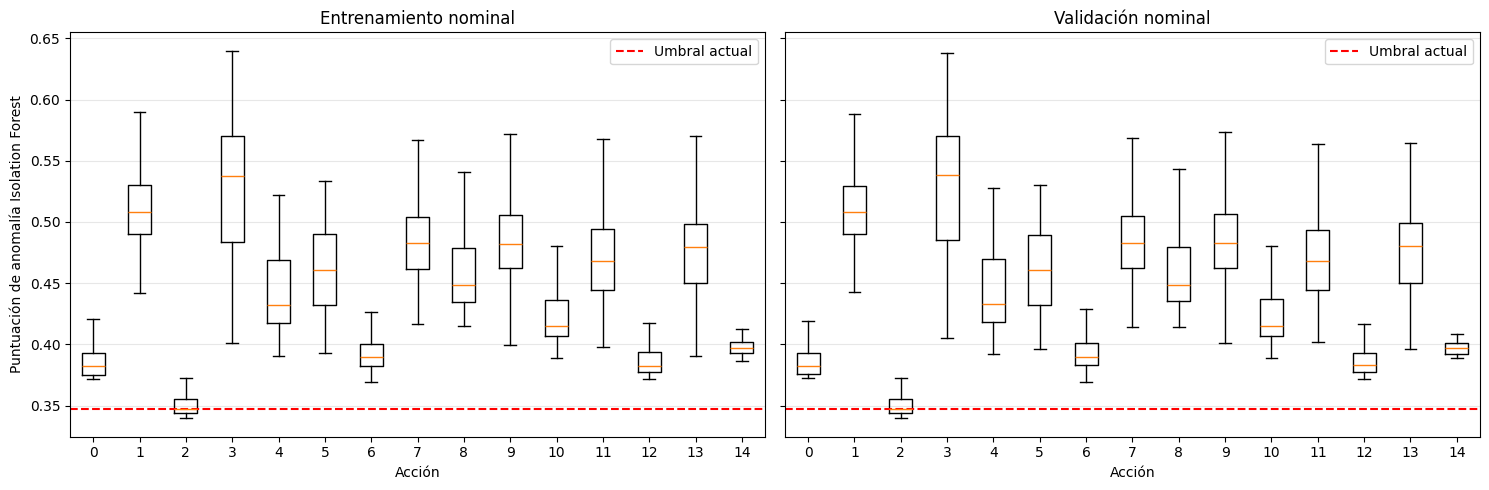

In [67]:
# SECCIÓN 12.12 - Diagnóstico de puntuaciones
# Exclusivamente entrenamiento y validación

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Recuperar metadatos alineados con los CSV
def obtener_metadatos(particion, df_referencia):
    meta = df_meta_piloto.loc[
        df_meta_piloto["particion"] == particion,
        ["sample", "action", "active", "anomaly"]
    ].reset_index(drop=True)

    assert len(meta) == len(df_referencia)
    assert np.array_equal(
        meta["sample"].to_numpy(),
        df_referencia["sample"].to_numpy()
    )
    assert np.array_equal(
        meta["anomaly"].to_numpy(),
        df_referencia["anomaly"].to_numpy()
    )
    return meta

meta_train = obtener_metadatos(
    "entrenamiento", df_train_v
)

meta_val = obtener_metadatos(
    "validacion", df_val_v
)

# 2. Puntuar entrenamiento nominal
scores_train_if = -modelo_if_v.score_samples(
    X_train_v
)

meta_train_normal = meta_train.loc[
    ~meta_train["anomaly"]
].copy()

assert len(meta_train_normal) == len(scores_train_if)

meta_train_normal["score"] = scores_train_if

# 3. Puntuar validación nominal
meta_val_normal = meta_val.loc[
    ~meta_val["anomaly"]
].copy()

meta_val_normal["score"] = scores_val_if[
    ~meta_val["anomaly"].to_numpy()
]

# 4. Resumen por acción
def resumen_acciones(df):
    return df.groupby("action")["score"].agg(
        ["count", "median", "mean", "std"]
    )

print("=== ENTRENAMIENTO NOMINAL ===")
display(resumen_acciones(meta_train_normal).round(4))

print("\n=== VALIDACIÓN NOMINAL ===")
display(resumen_acciones(meta_val_normal).round(4))

# 5. Cuantiles de puntuaciones
print("\n=== CUANTILES GLOBALES ===")

for nombre, datos in [
    ("Entrenamiento", meta_train_normal),
    ("Validación", meta_val_normal)
]:
    print(nombre)
    print(
        datos["score"].quantile(
            [0.05, 0.25, 0.50, 0.75, 0.95]
        )
    )

print("\nUmbral IF por registro:", umbral_if_v)

# 6. Distribución de puntuaciones por acción
fig, axes = plt.subplots(
    1, 2, figsize=(15, 5), sharey=True
)

for ax, datos, titulo in [
    (axes[0], meta_train_normal, "Entrenamiento nominal"),
    (axes[1], meta_val_normal, "Validación nominal")
]:
    grupos = [
        datos.loc[
            datos["action"] == a, "score"
        ].to_numpy()
        for a in sorted(datos["action"].unique())
    ]

    ax.boxplot(
        grupos,
        tick_labels=sorted(datos["action"].unique()),
        showfliers=False
    )

    ax.axhline(
        umbral_if_v,
        color="red",
        linestyle="--",
        label="Umbral actual"
    )

    ax.set_title(titulo)
    ax.set_xlabel("Acción")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

axes[0].set_ylabel(
    "Puntuación de anomalía Isolation Forest"
)

plt.tight_layout()
plt.show()



### 12.13. Calibración contextual de Isolation Forest por acción operativa

El análisis de las puntuaciones de Isolation Forest reveló diferencias importantes entre las acciones ejecutadas por el robot.

Aunque las distribuciones nominales de entrenamiento y validación fueron similares, las puntuaciones presentaron distintos rangos y medianas según el identificador `action`.

Para investigar este comportamiento se propone una calibración contextual de las puntuaciones de anomalía.

Se calcula la mediana y la desviación absoluta mediana (MAD) de las puntuaciones nominales para cada acción utilizando exclusivamente el conjunto de entrenamiento.

Posteriormente, cada puntuación se expresa como una desviación robusta respecto al comportamiento nominal de su acción correspondiente.

Se utiliza el conjunto de validación para seleccionar un umbral global que maximice el F1-score sobre las puntuaciones contextualizadas.

Esta metodología mantiene intacto el modelo Isolation Forest original. La variable `action` se utiliza únicamente durante la calibración contextual, sin incorporarse al entrenamiento del detector.

El procedimiento representa una propuesta experimental y no garantiza una mejora en la capacidad de clasificación.


In [68]:
# SECCIÓN 12.13 - Calibración contextual por acción
# Usando exclusivamente entrenamiento y validación

import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# 1. Construir estadísticas nominales por acción
def calcular_mad(x):
    x = np.asarray(x)
    mediana = np.median(x)
    return np.median(np.abs(x - mediana))

estadisticas_accion = (
    meta_train_normal.groupby("action")["score"]
    .agg(
        mediana="median",
        mad=calcular_mad,
        cantidad="size"
    )
)

display(estadisticas_accion)

# 2. Función de contextualización
def contextualizar_scores(meta, scores, estadisticas):
    datos = meta[["action"]].copy()
    datos["score_original"] = np.asarray(scores)

    datos = datos.join(
        estadisticas[["mediana", "mad"]],
        on="action"
    )

    assert datos["mediana"].notna().all()

    # MAD robusta con protección numérica
    escala = np.maximum(
        1.4826 * datos["mad"].to_numpy(),
        1e-4
    )

    score_contextual = (
        datos["score_original"].to_numpy()
        - datos["mediana"].to_numpy()
    ) / escala

    return score_contextual

# 3. Puntuaciones contextualizadas de validación
scores_val_contextual = contextualizar_scores(
    meta_val,
    scores_val_if,
    estadisticas_accion
)

# 4. Calibrar umbral en validación
precision_c, recall_c, umbrales_c = (
    precision_recall_curve(
        y_val_v,
        scores_val_contextual
    )
)

f1_c = (
    2 * precision_c[:-1] * recall_c[:-1]
    / (precision_c[:-1] + recall_c[:-1] + 1e-12)
)

mejor_c = np.argmax(f1_c)
umbral_contextual = float(
    umbrales_c[mejor_c]
)

pred_val_contextual = (
    scores_val_contextual >= umbral_contextual
).astype(int)

print("=== VALIDACIÓN CONTEXTUAL ===")
print("Umbral:", round(umbral_contextual, 4))
print("Precision:", round(
    precision_score(y_val_v, pred_val_contextual), 4
))
print("Recall:", round(
    recall_score(y_val_v, pred_val_contextual), 4
))
print("F1:", round(
    f1_score(y_val_v, pred_val_contextual), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_val_v, scores_val_contextual), 4
))
print("AP:", round(
    average_precision_score(
        y_val_v, scores_val_contextual
    ), 4
))

print("\nCALIBRACIÓN CONTEXTUAL COMPLETADA")


,mediana,mad,cantidad
action,,,
0,0.382465,0.008228,33507
1,0.508360,0.019538,55519
2,0.347601,0.004400,171287
3,0.537872,0.039094,21524
4,0.432349,0.019532,8877
5,0.460790,0.029096,10851
6,0.389747,0.008104,48902
7,0.482615,0.021148,22078
8,0.448787,0.018659,9168


=== VALIDACIÓN CONTEXTUAL ===
Umbral: -0.406
Precision: 0.3189
Recall: 0.797
F1: 0.4555
ROC-AUC: 0.5883
AP: 0.3306

CALIBRACIÓN CONTEXTUAL COMPLETADA



### 12.14. Construcción de características temporales por ventanas

Los resultados de las evaluaciones anteriores mostraron una capacidad limitada para distinguir mediciones nominales y anomalías inducidas mediante características instantáneas.

Para incorporar información sobre la evolución de las señales, se propone una representación basada en ventanas temporales.

Cada ensayo se segmenta en ventanas no solapadas de 100 muestras, correspondientes aproximadamente a un segundo de adquisición a la frecuencia nominal de 100 Hz.

Sobre las 24 variables operativas originales se calculan seis características estadísticas:

- Media aritmética.
- Desviación estándar.
- Valor cuadrático medio (RMS).
- Máximo absoluto.
- Rango de variación.
- Diferencia absoluta media entre muestras consecutivas.

Se generan hasta 144 características por ventana.

La segmentación se realiza independientemente para cada identificador `sample`, evitando que una ventana contenga observaciones pertenecientes a diferentes ensayos.

Las etiquetas originales se conservan como referencia para la evaluación, pero no se utilizan como entradas predictoras.

Las ventanas procedentes de ensayos anómalos heredan la etiqueta del ensayo. Esta estrategia introduce una limitación: no garantiza que todas las ventanas contengan una manifestación física de la anomalía.

### 12.14.1. Generación de ventanas y extracción de características


In [69]:
# =========================================================
# SECCIÓN 12.14.1 - Características temporales voraus-AD
# =========================================================

import numpy as np
import pandas as pd
from pathlib import Path

TAM_VENTANA = 100
SEMILLA_V3 = 42

# Reutilizar las 24 variables definidas en la sección 12.2
variables_temporales = variables_finales_v.copy()

assert len(variables_temporales) == 24

estadisticas = [
    "media",
    "std",
    "rms",
    "max_abs",
    "rango",
    "cambio_medio"
]

columnas_v3 = [
    f"{variable}_{estadistica}"
    for variable in variables_temporales
    for estadistica in estadisticas
]

def extraer_ventanas(df, nombre):
    """
    Extrae ventanas completas de 100 muestras.
    Nunca mezcla ensayos diferentes.
    """

    resultados = []
    descartadas = 0

    for sample_id, grupo in df.groupby(
        "sample", sort=False
    ):
        # Orden cronológico dentro del ensayo
        grupo = grupo.sort_values("time")

        # Verificar etiquetas del ensayo
        assert grupo["anomaly"].nunique() == 1
        assert grupo["category"].nunique() == 1

        datos = grupo[
            variables_temporales
        ].to_numpy(dtype=np.float64)

        n_ventanas = len(datos) // TAM_VENTANA

        if n_ventanas == 0:
            descartadas += len(datos)
            continue

        # Eliminar muestras incompletas al final
        n_utiles = n_ventanas * TAM_VENTANA
        descartadas += len(datos) - n_utiles

        # Forma: ventanas x muestras x variables
        bloques = datos[:n_utiles].reshape(
            n_ventanas,
            TAM_VENTANA,
            len(variables_temporales)
        )

        media = bloques.mean(axis=1)
        std = bloques.std(axis=1)
        rms = np.sqrt(
            np.mean(np.square(bloques), axis=1)
        )
        max_abs = np.max(
            np.abs(bloques), axis=1
        )
        rango = (
            bloques.max(axis=1)
            - bloques.min(axis=1)
        )
        cambio_medio = np.abs(
            np.diff(bloques, axis=1)
        ).mean(axis=1)

        # Intercalar las seis estadísticas por variable
        caracteristicas = np.stack(
            [
                media, std, rms,
                max_abs, rango, cambio_medio
            ],
            axis=2
        ).reshape(n_ventanas, -1)

        temporal = pd.DataFrame(
            caracteristicas.astype(np.float32),
            columns=columnas_v3
        )

        temporal.insert(
            0, "ventana", np.arange(n_ventanas)
        )
        temporal.insert(0, "sample", sample_id)

        temporal["anomaly"] = bool(
            grupo["anomaly"].iloc[0]
        )
        temporal["category"] = int(
            grupo["category"].iloc[0]
        )

        resultados.append(temporal)

    if not resultados:
        raise ValueError(
            f"No se generaron ventanas para {nombre}"
        )

    salida = pd.concat(
        resultados, ignore_index=True
    )

    X = salida[columnas_v3].to_numpy()

    assert np.isfinite(X).all()
    assert salida["sample"].nunique() == (
        df["sample"].nunique()
    )

    print(f"\n=== {nombre.upper()} ===")
    print("Ventanas generadas:", len(salida))
    print("Ensayos:", salida["sample"].nunique())
    print("Características:", len(columnas_v3))
    print("Muestras descartadas:", descartadas)

    print("Distribución de etiquetas:")
    print(salida["anomaly"].value_counts())

    return salida


# Generar los tres conjuntos
df_train_v3 = extraer_ventanas(
    df_train_v, "Entrenamiento"
)

df_val_v3 = extraer_ventanas(
    df_val_v, "Validación"
)

df_test_v3 = extraer_ventanas(
    df_test_v, "Prueba"
)

# Validar que ningún ensayo cambió de partición
ids_train_v3 = set(df_train_v3["sample"])
ids_val_v3 = set(df_val_v3["sample"])
ids_test_v3 = set(df_test_v3["sample"])

assert ids_train_v3.isdisjoint(ids_val_v3)
assert ids_train_v3.isdisjoint(ids_test_v3)
assert ids_val_v3.isdisjoint(ids_test_v3)

assert len(columnas_v3) == 144

print("\n=== VALIDACIÓN GENERAL V3 ===")
print("Características:", len(columnas_v3))
print("Separación por ensayos: CORRECTA")
print("Valores no finitos: 0")
print("EXTRACCIÓN TEMPORAL COMPLETADA")



=== ENTRENAMIENTO ===
Ventanas generadas: 7247
Ensayos: 703
Características: 144
Muestras descartadas: 43768
Distribución de etiquetas:
anomaly
False    5014
True     2233
Name: count, dtype: int64

=== VALIDACIÓN ===
Ventanas generadas: 1507
Ensayos: 146
Características: 144
Muestras descartadas: 8793
Distribución de etiquetas:
anomaly
False    1078
True      429
Name: count, dtype: int64

=== PRUEBA ===
Ventanas generadas: 1497
Ensayos: 146
Características: 144
Muestras descartadas: 9536
Distribución de etiquetas:
anomaly
False    1071
True      426
Name: count, dtype: int64

=== VALIDACIÓN GENERAL V3 ===
Características: 144
Separación por ensayos: CORRECTA
Valores no finitos: 0
EXTRACCIÓN TEMPORAL COMPLETADA


In [70]:
# SECCIÓN 12.14.2 - Exportación de datasets temporales

CARPETA_V3 = (
    CARPETA_TRABAJO
    / "dataset_voraus_AD"
    / "procesado_temporal_v3"
)

CARPETA_V3.mkdir(
    parents=True, exist_ok=True
)

datasets_v3 = {
    "entrenamiento": df_train_v3,
    "validacion": df_val_v3,
    "prueba": df_test_v3
}

for nombre, df in datasets_v3.items():
    ruta = CARPETA_V3 / f"voraus_v3_{nombre}.csv"

    df.to_csv(ruta, index=False)

    print(
        nombre,
        "| ventanas:", len(df),
        "| ensayos:", df["sample"].nunique(),
        "| archivo:", ruta.name
    )

print("\nDATASETS TEMPORALES V3 GUARDADOS")


entrenamiento | ventanas: 7247 | ensayos: 703 | archivo: voraus_v3_entrenamiento.csv
validacion | ventanas: 1507 | ensayos: 146 | archivo: voraus_v3_validacion.csv
prueba | ventanas: 1497 | ensayos: 146 | archivo: voraus_v3_prueba.csv

DATASETS TEMPORALES V3 GUARDADOS



### 12.15. Optimización de Isolation Forest mediante características temporales

Se desarrolla una tercera versión del detector de anomalías utilizando las 144 características temporales generadas en la sección anterior.

El entrenamiento se realiza exclusivamente con ventanas pertenecientes a ensayos nominales.

Se evalúan diferentes configuraciones de Isolation Forest y diferentes métodos de agregación de puntuaciones por ensayo.

Los hiperparámetros y umbrales se seleccionan utilizando exclusivamente los ensayos de validación.

El conjunto de prueba no se utiliza durante esta etapa de optimización.

### 12.15.1. Preparación de características temporales


In [71]:
# SECCIÓN 12.15.1 - Preparación V3

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Entrenar exclusivamente con ventanas nominales
df_train_normal_v3 = df_train_v3.loc[
    ~df_train_v3["anomaly"]
].copy()

# Características predictoras
X_train_raw_v3 = df_train_normal_v3[
    columnas_v3
].to_numpy(dtype=np.float32)

X_val_raw_v3 = df_val_v3[
    columnas_v3
].to_numpy(dtype=np.float32)

# Normalización sin fuga desde validación
scaler_v3 = StandardScaler()

X_train_v3 = scaler_v3.fit_transform(
    X_train_raw_v3
).astype(np.float32)

X_val_v3 = scaler_v3.transform(
    X_val_raw_v3
).astype(np.float32)

y_val_v3 = df_val_v3[
    "anomaly"
].astype(int).to_numpy()

# Verificaciones
assert X_train_v3.shape == (5014, 144)
assert X_val_v3.shape == (1507, 144)

assert np.isfinite(X_train_v3).all()
assert np.isfinite(X_val_v3).all()

print("Entrenamiento nominal:", X_train_v3.shape)
print("Validación:", X_val_v3.shape)
print("Etiquetas anómalas:", int(y_val_v3.sum()))
print("PREPARACIÓN V3 COMPLETADA")


Entrenamiento nominal: (5014, 144)
Validación: (1507, 144)
Etiquetas anómalas: 429
PREPARACIÓN V3 COMPLETADA


In [72]:
# SECCIÓN 12.15.2 - Optimización en validación

configuraciones_v3 = [
    {"n_estimators": 100, "max_samples": 256,
     "max_features": 1.0},
    {"n_estimators": 200, "max_samples": 256,
     "max_features": 0.7},
    {"n_estimators": 200, "max_samples": 1024,
     "max_features": 1.0},
    {"n_estimators": 300, "max_samples": 1024,
     "max_features": 0.7}
]

percentiles_v3 = [75, 90, 95]

def encontrar_umbral(y, scores):
    precision, recall, thresholds = (
        precision_recall_curve(y, scores)
    )

    f1 = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )

    indice = int(np.argmax(f1))

    return float(thresholds[indice])

resultados_busqueda_v3 = []
modelos_candidatos_v3 = {}

for i, parametros in enumerate(configuraciones_v3):

    print(f"\nEntrenando configuración {i+1}/4")

    modelo = IsolationForest(
        **parametros,
        contamination="auto",
        random_state=42,
        n_jobs=-1
    )

    modelo.fit(X_train_v3)

    scores = -modelo.score_samples(X_val_v3)

    modelos_candidatos_v3[i] = modelo

    for percentil in percentiles_v3:

        # Agregar sin cruzar límites de ensayo
        ensayos = agregar_por_ensayo(
            df_val_v3,
            scores,
            percentil=percentil
        )

        y = ensayos["anomaly"].astype(int).to_numpy()
        s = ensayos["score_ensayo"].to_numpy()

        umbral = encontrar_umbral(y, s)
        pred = (s >= umbral).astype(int)

        tn = np.sum((y == 0) & (pred == 0))
        fp = np.sum((y == 0) & (pred == 1))

        resultados_busqueda_v3.append({
            "configuracion": i,
            "arboles": parametros["n_estimators"],
            "max_samples": parametros["max_samples"],
            "max_features": parametros["max_features"],
            "percentil": percentil,
            "umbral": umbral,
            "precision": precision_score(
                y, pred, zero_division=0
            ),
            "recall": recall_score(
                y, pred, zero_division=0
            ),
            "f1": f1_score(
                y, pred, zero_division=0
            ),
            "fpr": fp / (fp + tn),
            "roc_auc": roc_auc_score(y, s),
            "ap": average_precision_score(y, s)
        })

df_busqueda_v3 = pd.DataFrame(
    resultados_busqueda_v3
)

print("\n=== RESULTADOS DE VALIDACIÓN ===")

display(
    df_busqueda_v3.sort_values(
        ["f1", "roc_auc"],
        ascending=False
    ).round(4)
)

# Selección según F1 y, en caso de empate, ROC-AUC
mejor_v3 = df_busqueda_v3.sort_values(
    ["f1", "roc_auc"],
    ascending=False
).iloc[0]

modelo_if_v3 = modelos_candidatos_v3[
    int(mejor_v3["configuracion"])
]

print("\n=== MEJOR CONFIGURACIÓN EN VALIDACIÓN ===")
display(mejor_v3.to_frame().T)

print("\nOPTIMIZACIÓN V3 COMPLETADA")



Entrenando configuración 1/4

Entrenando configuración 2/4

Entrenando configuración 3/4

Entrenando configuración 4/4

=== RESULTADOS DE VALIDACIÓN ===


,configuracion,arboles,max_samples,max_features,percentil,umbral,precision,recall,f1,fpr,roc_auc,ap
9,3,300,1024,0.7,75,0.5061,0.4694,0.5610,0.5111,0.2476,0.6437,0.4409
6,2,200,1024,1.0,75,0.5025,0.4194,0.6341,0.5049,0.3429,0.6276,0.4451
3,1,200,256,0.7,75,0.5103,0.3248,0.9268,0.4810,0.7524,0.6272,0.4324
0,0,100,256,1.0,75,0.5147,0.3404,0.7805,0.4741,0.5905,0.6246,0.3983
7,2,200,1024,1.0,90,0.4951,0.3136,0.9024,0.4654,0.7714,0.5477,0.3373
10,3,300,1024,0.7,90,0.5116,0.3500,0.6829,0.4628,0.4952,0.5689,0.3420
5,1,200,256,0.7,95,0.5181,0.2985,0.9756,0.4571,0.8952,0.5192,0.3026
11,3,300,1024,0.7,95,0.4936,0.3000,0.9512,0.4561,0.8667,0.5573,0.3464
8,2,200,1024,1.0,95,0.4936,0.2977,0.9512,0.4535,0.8762,0.5391,0.3292
4,1,200,256,0.7,90,0.5147,0.2908,1.0000,0.4505,0.9524,0.5101,0.2961



=== MEJOR CONFIGURACIÓN EN VALIDACIÓN ===


,configuracion,arboles,max_samples,max_features,percentil,umbral,precision,recall,f1,fpr,roc_auc,ap
9,3.0,300.0,1024.0,0.7,75.0,0.506052,0.469388,0.560976,0.511111,0.247619,0.64367,0.44087



OPTIMIZACIÓN V3 COMPLETADA



### 12.16. Optimización de un autoencoder con características temporales

Se implementa una nueva versión del autoencoder utilizando las 144 características estadísticas extraídas de ventanas temporales de 100 muestras.

El objetivo es evaluar si esta representación permite distinguir mejor los ensayos nominales y anómalos que el modelo desarrollado previamente con variables instantáneas.

El entrenamiento se realiza exclusivamente con ventanas pertenecientes a ensayos nominales.

Se reserva un subconjunto de ensayos nominales para la validación interna de la red neuronal, evitando compartir ventanas del mismo ensayo entre ajuste y validación interna.

La selección de arquitectura y umbral se realiza mediante el conjunto de validación externa.

### 12.16.1. Preparación de los datos y separación por ensayos


In [73]:
# =====================================================
# SECCIÓN 12.16.1 - Preparación del Autoencoder V3
# =====================================================

import numpy as np
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

tf.keras.utils.set_random_seed(42)

# Datos nominales originales, sin normalizar
X_ae_raw_v3 = df_train_normal_v3[
    columnas_v3
].to_numpy(dtype=np.float32)

grupos_ae_v3 = df_train_normal_v3[
    "sample"
].to_numpy()

# División por ensayos completos
splitter_v3 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

idx_train_ae, idx_val_ae = next(
    splitter_v3.split(
        X_ae_raw_v3,
        groups=grupos_ae_v3
    )
)

# Verificar separación
ensayos_train_ae = set(
    grupos_ae_v3[idx_train_ae]
)

ensayos_val_ae = set(
    grupos_ae_v3[idx_val_ae]
)

assert ensayos_train_ae.isdisjoint(
    ensayos_val_ae
)

# Escalador independiente del Autoencoder V3
scaler_ae_v3 = StandardScaler()

X_ajuste_ae_v3 = scaler_ae_v3.fit_transform(
    X_ae_raw_v3[idx_train_ae]
).astype(np.float32)

X_val_interna_ae_v3 = scaler_ae_v3.transform(
    X_ae_raw_v3[idx_val_ae]
).astype(np.float32)

# Validación externa: NO ajustar el escalador aquí
X_val_ae_v3 = scaler_ae_v3.transform(
    df_val_v3[columnas_v3].to_numpy(
        dtype=np.float32
    )
).astype(np.float32)

assert X_ajuste_ae_v3.shape[1] == 144
assert X_val_ae_v3.shape == (1507, 144)

for datos in [
    X_ajuste_ae_v3,
    X_val_interna_ae_v3,
    X_val_ae_v3
]:
    assert np.isfinite(datos).all()

print("=== AUTOENCODER V3 ===")
print("Ajuste:", X_ajuste_ae_v3.shape)
print("Validación interna:", X_val_interna_ae_v3.shape)
print("Validación externa:", X_val_ae_v3.shape)
print("Ensayos de ajuste:", len(ensayos_train_ae))
print("Ensayos internos:", len(ensayos_val_ae))
print("\nDATOS PREPARADOS")


=== AUTOENCODER V3 ===
Ajuste: (4255, 144)
Validación interna: (759, 144)
Validación externa: (1507, 144)
Ensayos de ajuste: 416
Ensayos internos: 74

DATOS PREPARADOS



### 12.16.2. Comparación de arquitecturas neuronales

Se evalúan dos arquitecturas de autoencoder con diferentes tamaños de representación latente.

La primera utiliza una representación comprimida de 16 dimensiones y la segunda de 32 dimensiones.

Ambas redes emplean capas densas, activación ReLU, optimización Adam y pérdida MSE.

Se incorpora regularización L2 y EarlyStopping para limitar el sobreajuste.

El rendimiento de detección se compara posteriormente mediante las etiquetas del conjunto de validación externa.


In [74]:
# =====================================================
# SECCIÓN 12.16.2 - Entrenar dos Autoencoders V3
# =====================================================

from tensorflow.keras import regularizers

def crear_autoencoder_v3(
    n_features,
    hidden,
    latent,
    nombre
):
    entrada = keras.Input(
        shape=(n_features,)
    )

    x = layers.Dense(
        hidden,
        activation="relu",
        kernel_regularizer=regularizers.l2(1e-5)
    )(entrada)

    x = layers.Dense(
        latent,
        activation="linear",
        name=f"latente_{nombre}"
    )(x)

    x = layers.Dense(
        hidden,
        activation="relu"
    )(x)

    salida = layers.Dense(
        n_features,
        activation="linear"
    )(x)

    modelo = keras.Model(
        entrada,
        salida,
        name=nombre
    )

    modelo.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    return modelo


arquitecturas_v3 = {
    "AE_V3_A": {"hidden": 64, "latent": 16},
    "AE_V3_B": {"hidden": 96, "latent": 32}
}

modelos_ae_v3 = {}
historiales_ae_v3 = {}

for nombre, config in arquitecturas_v3.items():

    print("\nEntrenando:", nombre)

    tf.keras.utils.set_random_seed(42)

    modelo = crear_autoencoder_v3(
        n_features=144,
        hidden=config["hidden"],
        latent=config["latent"],
        nombre=nombre
    )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        min_delta=1e-5,
        restore_best_weights=True
    )

    historial = modelo.fit(
        X_ajuste_ae_v3,
        X_ajuste_ae_v3,
        validation_data=(
            X_val_interna_ae_v3,
            X_val_interna_ae_v3
        ),
        epochs=100,
        batch_size=128,
        shuffle=True,
        callbacks=[early_stop],
        verbose=0
    )

    modelos_ae_v3[nombre] = modelo
    historiales_ae_v3[nombre] = historial

    print(
        "Épocas:",
        len(historial.history["loss"])
    )

    print(
        "Mejor MSE validación interna:",
        round(
            min(historial.history["val_loss"]),
            6
        )
    )

print("\nENTRENAMIENTO DE ARQUITECTURAS COMPLETADO")



Entrenando: AE_V3_A
Épocas: 100
Mejor MSE validación interna: 0.007742

Entrenando: AE_V3_B
Épocas: 100
Mejor MSE validación interna: 0.004728

ENTRENAMIENTO DE ARQUITECTURAS COMPLETADO



### 12.16.3. Optimización del autoencoder mediante validación externa

Se calculan los errores de reconstrucción de las dos arquitecturas sobre el conjunto de validación externa.

Los errores se agregan por ensayo utilizando los percentiles 75, 90 y 95.

Para cada combinación se selecciona el umbral que maximiza F1-score en validación.

Se comparan precision, recall, F1-score, ROC-AUC, Average Precision y tasa de falsos positivos.

La arquitectura definitiva se selecciona sin utilizar las etiquetas del conjunto de prueba.


In [75]:
# =====================================================
# SECCIÓN 12.16.3 - Optimización Autoencoder V3
# =====================================================

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

resultados_ae_busqueda_v3 = []
scores_ae_candidatos_v3 = {}

for nombre, modelo in modelos_ae_v3.items():

    # Reconstrucción de validación externa
    reconstruccion = modelo.predict(
        X_val_ae_v3,
        batch_size=512,
        verbose=0
    )

    # Error cuadrático medio por ventana
    scores = np.mean(
        np.square(
            X_val_ae_v3 - reconstruccion
        ),
        axis=1
    )

    scores_ae_candidatos_v3[nombre] = scores

    for percentil in [75, 90, 95]:

        ensayos = agregar_por_ensayo(
            df_val_v3,
            scores,
            percentil=percentil
        )

        y = ensayos["anomaly"].astype(int).to_numpy()
        s = ensayos["score_ensayo"].to_numpy()

        precision, recall, thresholds = (
            precision_recall_curve(y, s)
        )

        f1 = (
            2 * precision[:-1] * recall[:-1]
            / (
                precision[:-1]
                + recall[:-1]
                + 1e-12
            )
        )

        indice = int(np.argmax(f1))

        umbral = float(thresholds[indice])
        pred = (s >= umbral).astype(int)

        tn = np.sum((y == 0) & (pred == 0))
        fp = np.sum((y == 0) & (pred == 1))

        resultados_ae_busqueda_v3.append({
            "modelo": nombre,
            "percentil": percentil,
            "umbral": umbral,
            "precision": precision_score(
                y, pred, zero_division=0
            ),
            "recall": recall_score(
                y, pred, zero_division=0
            ),
            "f1": f1_score(
                y, pred, zero_division=0
            ),
            "fpr": fp / (fp + tn),
            "roc_auc": roc_auc_score(y, s),
            "ap": average_precision_score(y, s)
        })

df_ae_busqueda_v3 = pd.DataFrame(
    resultados_ae_busqueda_v3
)

print("=== AUTOENCODER V3: VALIDACIÓN ===")

display(
    df_ae_busqueda_v3.sort_values(
        ["f1", "roc_auc"],
        ascending=False
    ).round(4)
)

# Seleccionar mejor arquitectura
mejor_ae_v3 = df_ae_busqueda_v3.sort_values(
    ["f1", "roc_auc"],
    ascending=False
).iloc[0]

nombre_mejor_ae_v3 = mejor_ae_v3["modelo"]

modelo_ae_v3_final = modelos_ae_v3[
    nombre_mejor_ae_v3
]

print("\n=== MEJOR AUTOENCODER V3 ===")
display(mejor_ae_v3.to_frame().T)

print("\nOPTIMIZACIÓN AUTOENCODER V3 COMPLETADA")


=== AUTOENCODER V3: VALIDACIÓN ===


,modelo,percentil,umbral,precision,recall,f1,fpr,roc_auc,ap
0,AE_V3_A,75,0.0115,0.5536,0.7561,0.6392,0.2381,0.8026,0.6819
4,AE_V3_B,90,0.0077,0.5800,0.7073,0.6374,0.2000,0.8035,0.6715
3,AE_V3_B,75,0.0064,0.5714,0.6829,0.6222,0.2000,0.8125,0.6708
5,AE_V3_B,95,0.0084,0.5179,0.7073,0.5979,0.2571,0.7826,0.6433
1,AE_V3_A,90,0.0130,0.4306,0.7561,0.5487,0.3905,0.7315,0.5904
2,AE_V3_A,95,0.0154,0.4516,0.6829,0.5437,0.3238,0.7182,0.5913



=== MEJOR AUTOENCODER V3 ===


,modelo,percentil,umbral,precision,recall,f1,fpr,roc_auc,ap
0,AE_V3_A,75,0.011466,0.553571,0.756098,0.639175,0.238095,0.802555,0.681948



OPTIMIZACIÓN AUTOENCODER V3 COMPLETADA



### 12.16.4. Comparación preliminar de modelos temporales

Se comparan las configuraciones seleccionadas de Isolation Forest V3 y Autoencoder V3.

Ambos métodos utilizan las mismas 144 características estadísticas y las mismas particiones externas de ensayos.

Las métricas se calculan exclusivamente sobre el conjunto de validación y corresponden a resultados de selección de modelos.

La comparación permite determinar cuál de los dos enfoques presenta un mejor equilibrio entre detección de anomalías y falsas alarmas antes de realizar una evaluación independiente.


=== COMPARACIÓN DE MODELOS TEMPORALES ===


,Modelo,Precision,Recall,F1,FPR,ROC-AUC,AP
0,Isolation Forest V3,0.4694,0.5610,0.5111,0.2476,0.6437,0.4409
1,AE_V3_A,0.5536,0.7561,0.6392,0.2381,0.8026,0.6819


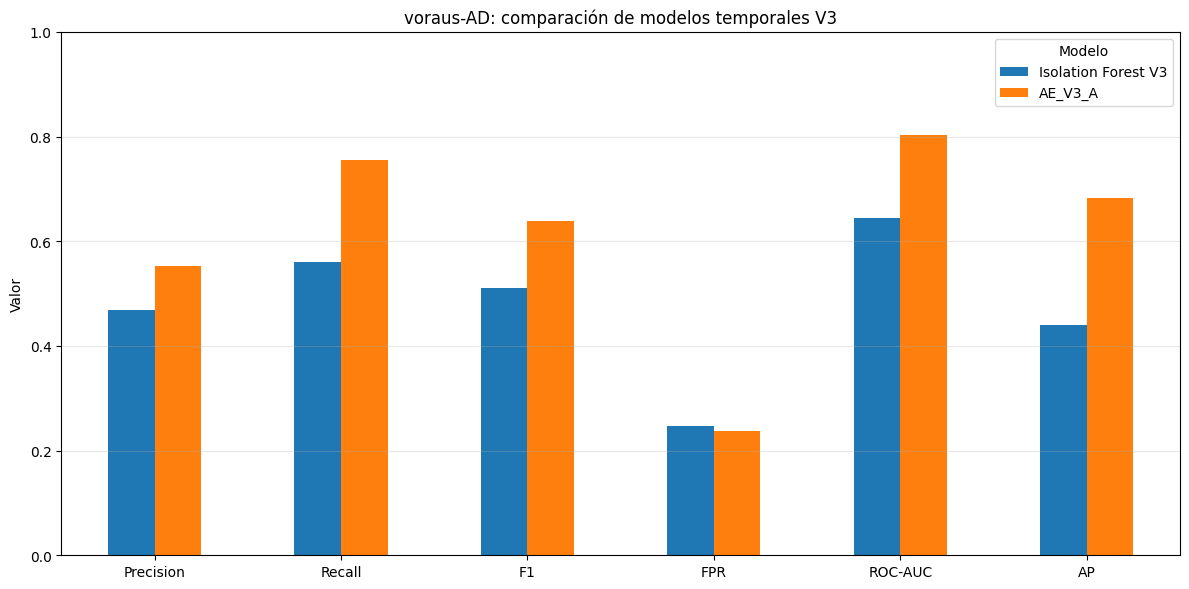

In [76]:
# SECCIÓN 12.16.4 - Comparación preliminar V3

import pandas as pd
import matplotlib.pyplot as plt

df_comparacion_v3 = pd.DataFrame([
    {
        "Modelo": "Isolation Forest V3",
        "Precision": mejor_v3["precision"],
        "Recall": mejor_v3["recall"],
        "F1": mejor_v3["f1"],
        "FPR": mejor_v3["fpr"],
        "ROC-AUC": mejor_v3["roc_auc"],
        "AP": mejor_v3["ap"]
    },
    {
        "Modelo": nombre_mejor_ae_v3,
        "Precision": mejor_ae_v3["precision"],
        "Recall": mejor_ae_v3["recall"],
        "F1": mejor_ae_v3["f1"],
        "FPR": mejor_ae_v3["fpr"],
        "ROC-AUC": mejor_ae_v3["roc_auc"],
        "AP": mejor_ae_v3["ap"]
    }
])

print("=== COMPARACIÓN DE MODELOS TEMPORALES ===")
display(df_comparacion_v3.round(4))

# Gráfico comparativo
ax = df_comparacion_v3.set_index(
    "Modelo"
)[["Precision", "Recall", "F1", "FPR", "ROC-AUC", "AP"]].T.plot(
    kind="bar",
    figsize=(12, 6),
    rot=0
)

ax.set_title(
    "voraus-AD: comparación de modelos temporales V3"
)

ax.set_ylabel("Valor")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



### 12.17. Evaluación exploratoria de los modelos temporales V3

Se evalúan las configuraciones de Isolation Forest V3 y Autoencoder V3 seleccionadas previamente mediante el conjunto de validación.

Se utilizan las mismas características temporales y los ensayos del conjunto de prueba existente.

Los modelos y sus umbrales permanecen fijos durante esta evaluación.

Se calculan precision, recall, F1-score, ROC-AUC, Average Precision, tasa de falsos positivos y matrices de confusión por ensayo.

Dado que el conjunto de prueba ya fue utilizado en análisis exploratorios anteriores, esta evaluación no se considera una confirmación completamente independiente. Posteriormente se requerirá una evaluación adicional con ensayos no utilizados durante el desarrollo.


=== RESULTADOS V3 POR ENSAYO ===


,Modelo,Precision,Recall,F1,ROC-AUC,AP,FPR,VN,FP,FN,VP
0,Isolation Forest V3,0.4500,0.4390,0.4444,0.6997,0.5304,0.2095,83,22,23,18
1,Autoencoder V3,0.6047,0.6341,0.6190,0.8348,0.6872,0.1619,88,17,15,26


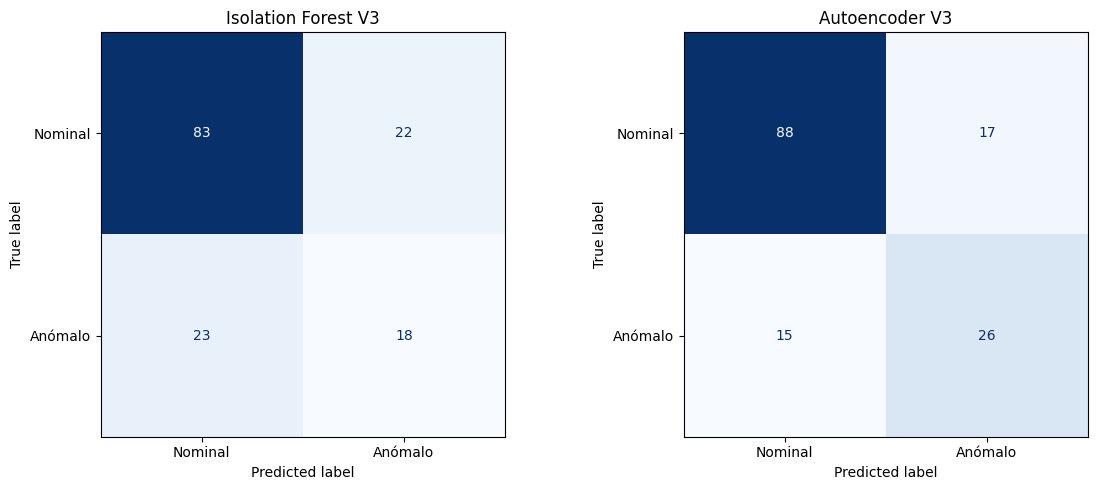

EVALUACIÓN EXPLORATORIA V3 COMPLETADA


In [77]:
# =====================================================
# SECCIÓN 12.17 - Evaluación exploratoria V3
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay
)

# 1. Preparar características de prueba
X_test_if_v3 = scaler_v3.transform(
    df_test_v3[columnas_v3].to_numpy(dtype=np.float32)
).astype(np.float32)

X_test_ae_v3 = scaler_ae_v3.transform(
    df_test_v3[columnas_v3].to_numpy(dtype=np.float32)
).astype(np.float32)

assert np.isfinite(X_test_if_v3).all()
assert np.isfinite(X_test_ae_v3).all()

# 2. Isolation Forest V3
scores_if_v3 = -modelo_if_v3.score_samples(
    X_test_if_v3
)

ensayos_if_v3 = agregar_por_ensayo(
    df_test_v3,
    scores_if_v3,
    percentil=int(mejor_v3["percentil"])
)

pred_if_v3 = (
    ensayos_if_v3["score_ensayo"].to_numpy()
    >= float(mejor_v3["umbral"])
).astype(int)

# 3. Autoencoder V3
reconstruccion_v3 = modelo_ae_v3_final.predict(
    X_test_ae_v3,
    batch_size=512,
    verbose=0
)

scores_ae_v3 = np.mean(
    np.square(X_test_ae_v3 - reconstruccion_v3),
    axis=1
)

ensayos_ae_v3 = agregar_por_ensayo(
    df_test_v3,
    scores_ae_v3,
    percentil=int(mejor_ae_v3["percentil"])
)

pred_ae_v3 = (
    ensayos_ae_v3["score_ensayo"].to_numpy()
    >= float(mejor_ae_v3["umbral"])
).astype(int)

# 4. Verificar correspondencia
assert np.array_equal(
    ensayos_if_v3["sample"].to_numpy(),
    ensayos_ae_v3["sample"].to_numpy()
)

y_v3 = ensayos_if_v3[
    "anomaly"
].astype(int).to_numpy()

assert len(y_v3) == 146
assert y_v3.sum() == 41

# 5. Métricas
def metricas_v3(nombre, y, pred, scores):
    cm = confusion_matrix(y, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    return {
        "Modelo": nombre,
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y, scores),
        "AP": average_precision_score(y, scores),
        "FPR": fp / (fp + tn),
        "VN": tn, "FP": fp, "FN": fn, "VP": tp
    }

resultados_v3_test = pd.DataFrame([
    metricas_v3(
        "Isolation Forest V3", y_v3, pred_if_v3,
        ensayos_if_v3["score_ensayo"].to_numpy()
    ),
    metricas_v3(
        "Autoencoder V3", y_v3, pred_ae_v3,
        ensayos_ae_v3["score_ensayo"].to_numpy()
    )
])

print("=== RESULTADOS V3 POR ENSAYO ===")
display(resultados_v3_test.round(4))

# 6. Matrices de confusión
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, pred, nombre in [
    (axes[0], pred_if_v3, "Isolation Forest V3"),
    (axes[1], pred_ae_v3, "Autoencoder V3")
]:
    ConfusionMatrixDisplay.from_predictions(
        y_v3, pred,
        labels=[0, 1],
        display_labels=["Nominal", "Anómalo"],
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )
    ax.set_title(nombre)

plt.tight_layout()
plt.show()

print("EVALUACIÓN EXPLORATORIA V3 COMPLETADA")



### 12.18. Evaluación confirmatoria con ensayos no utilizados

Se reserva un conjunto adicional de ensayos del dataset voraus-AD que no participaron en el entrenamiento, validación ni evaluación exploratoria de los modelos anteriores.

Los modelos Isolation Forest V3 y Autoencoder V3 permanecen congelados, incluyendo sus parámetros, normalizadores, características y umbrales de decisión.

Se utilizará la misma extracción temporal de ventanas de 100 muestras y 144 características.

Esta evaluación pretende comprobar la estabilidad del desempeño sobre nuevas ejecuciones, sin realizar ajustes posteriores en función de sus resultados.

Se reconoce que las configuraciones experimentales podrían introducir dependencias asociadas a las etiquetas, por lo que la evaluación no constituye por sí sola una demostración de generalización a cualquier condición robótica.


In [78]:
# SECCIÓN 12.18 - Preparación de ensayos reservados

import pyarrow.parquet as pq
import pyarrow.compute as pc
import pyarrow as pa
import pandas as pd
import numpy as np

# 1. Identificar ensayos que nunca se usaron

# =====================================================
# SECCIÓN 12.18 - Identificación de ensayos reservados
# =====================================================

# Reconstruir los identificadores desde los DataFrames
ids_train_v = set(df_train_v["sample"].unique())
ids_val_v = set(df_val_v["sample"].unique())
ids_test_v = set(df_test_v["sample"].unique())

# Unir todos los ensayos utilizados
ids_utilizados = (
    ids_train_v | ids_val_v | ids_test_v
)

# Recuperar todos los identificadores del Parquet
todos_ids = set(df_meta_v["sample"].unique())

# Identificar los ensayos todavía no utilizados
ids_reservados = sorted(
    todos_ids - ids_utilizados
)

print("=== ENSAYOS DISPONIBLES ===")
print("Ensayos originales:", len(todos_ids))
print("Ensayos utilizados:", len(ids_utilizados))
print("Ensayos reservados:", len(ids_reservados))

# Verificaciones
assert len(todos_ids) == 2122
assert len(ids_utilizados) == 995
assert len(ids_reservados) == 1127

assert set(ids_reservados).isdisjoint(
    ids_utilizados
)

print("\nIDENTIFICACIÓN DE ENSAYOS CORRECTA")


# 2. Leer únicamente variables necesarias
columnas_holdout = [
    "time", "sample", "anomaly", "category"
] + variables_temporales

archivo = pq.ParquetFile(RUTA_PARQUET)

bloques_holdout = []

# Filtrado por lotes para controlar la memoria
ids_arrow = pa.array(ids_reservados)

for lote in archivo.iter_batches(
    batch_size=50000,
    columns=columnas_holdout
):
    tabla = pa.Table.from_batches([lote])

    mascara = pc.is_in(
        tabla["sample"],
        value_set=ids_arrow
    )

    filtrado = tabla.filter(mascara)

    if filtrado.num_rows:
        bloques_holdout.append(
            filtrado.to_pandas()
        )

df_holdout = pd.concat(
    bloques_holdout,
    ignore_index=True
)

del bloques_holdout

# 3. Verificar independencia de ensayos
assert set(df_holdout["sample"]).isdisjoint(
    ids_utilizados
)

assert df_holdout["sample"].nunique() == 1127

assert (
    df_holdout.groupby("sample")["anomaly"].nunique()
    == 1
).all()

# 4. Extraer características temporales
df_holdout_v3 = extraer_ventanas(
    df_holdout,
    "Evaluación reservada V3"
)

assert len(df_holdout_v3) > 0
assert len(columnas_v3) == 144

print("\nENSAYOS RESERVADOS PREPARADOS")
print("Ventanas:", len(df_holdout_v3))
print("Ensayos:", df_holdout_v3["sample"].nunique())


=== ENSAYOS DISPONIBLES ===
Ensayos originales: 2122
Ensayos utilizados: 995
Ensayos reservados: 1127

IDENTIFICACIÓN DE ENSAYOS CORRECTA

=== EVALUACIÓN RESERVADA V3 ===
Ventanas generadas: 11664
Ensayos: 1127
Características: 144
Muestras descartadas: 68093
Distribución de etiquetas:
anomaly
False    6826
True     4838
Name: count, dtype: int64

ENSAYOS RESERVADOS PREPARADOS
Ventanas: 11664
Ensayos: 1127



### 12.19. Evaluación adicional de generalización de los modelos V3

Se evalúan los modelos Isolation Forest V3 y Autoencoder V3 sobre 1 127 ensayos del dataset voraus-AD que no fueron utilizados en las etapas anteriores.

Se mantienen congelados los modelos, escaladores, características temporales, percentiles de agregación y umbrales seleccionados durante validación.

Cada ensayo se representa mediante el percentil de sus puntuaciones de anomalía previamente seleccionado para cada modelo.

La evaluación utiliza las etiquetas originales de los ensayos y calcula precision, recall, F1-score, ROC-AUC, Average Precision y tasa de falsos positivos.

Esta evaluación permite estudiar la estabilidad de los modelos en nuevas ejecuciones del mismo dataset. No representa una validación entre diferentes robots ni garantiza independencia de las condiciones experimentales.


=== EVALUACIÓN RESERVADA ===
Ventanas: 11664
Características: 144

=== DISTRIBUCIÓN POR ENSAYO ===
Ensayos: 1127
Nominales: 667
Anómalos: 460

=== RESULTADOS EN ENSAYOS RESERVADOS ===


,Modelo,Precision,Recall,F1,ROC-AUC,AP,FPR,VN,FP,FN,VP
0,Isolation Forest V3,0.6427,0.5239,0.5772,0.7035,0.6185,0.2009,533,134,219,241
1,Autoencoder V3,0.7572,0.6304,0.6880,0.8372,0.8050,0.1394,574,93,170,290


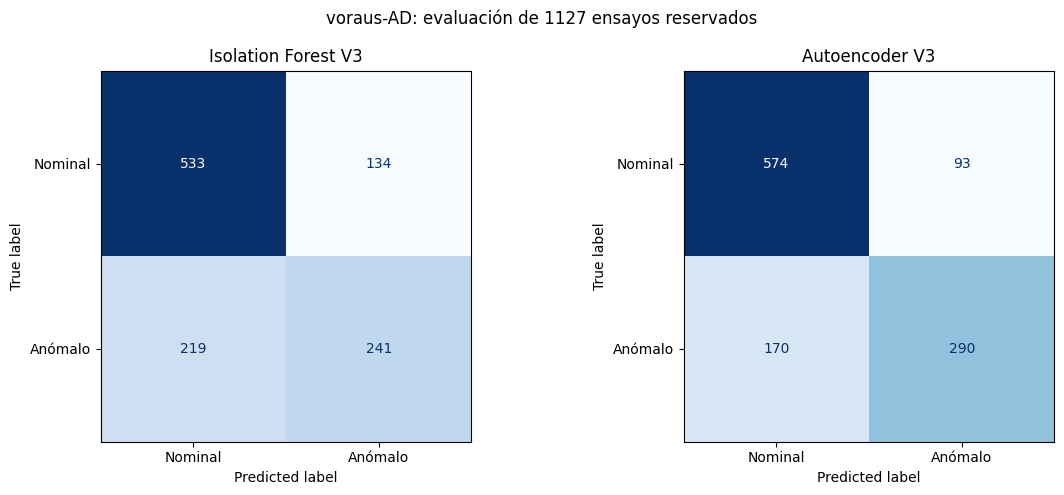


EVALUACIÓN RESERVADA COMPLETADA


In [79]:
# =====================================================
# SECCIÓN 12.19 - Evaluación reservada V3
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Verificar conjunto reservado
assert df_holdout_v3["sample"].nunique() == 1127
assert len(columnas_v3) == 144

assert set(df_holdout_v3["sample"]).isdisjoint(
    ids_utilizados
)

# 2. Preparar características
X_holdout_raw = df_holdout_v3[
    columnas_v3
].to_numpy(dtype=np.float32)

# Aplicar escaladores previamente entrenados
X_holdout_if = scaler_v3.transform(
    X_holdout_raw
).astype(np.float32)

X_holdout_ae = scaler_ae_v3.transform(
    X_holdout_raw
).astype(np.float32)

assert np.isfinite(X_holdout_if).all()
assert np.isfinite(X_holdout_ae).all()

print("=== EVALUACIÓN RESERVADA ===")
print("Ventanas:", len(X_holdout_raw))
print("Características:", X_holdout_raw.shape[1])

# 3. Puntuaciones Isolation Forest V3
scores_holdout_if = -modelo_if_v3.score_samples(
    X_holdout_if
)

ensayos_holdout_if = agregar_por_ensayo(
    df_holdout_v3,
    scores_holdout_if,
    percentil=int(mejor_v3["percentil"])
)

pred_holdout_if = (
    ensayos_holdout_if["score_ensayo"].to_numpy()
    >= float(mejor_v3["umbral"])
).astype(int)

# 4. Puntuaciones Autoencoder V3
recon_holdout = modelo_ae_v3_final.predict(
    X_holdout_ae,
    batch_size=512,
    verbose=0
)

scores_holdout_ae = np.mean(
    np.square(X_holdout_ae - recon_holdout),
    axis=1
)

ensayos_holdout_ae = agregar_por_ensayo(
    df_holdout_v3,
    scores_holdout_ae,
    percentil=int(mejor_ae_v3["percentil"])
)

pred_holdout_ae = (
    ensayos_holdout_ae["score_ensayo"].to_numpy()
    >= float(mejor_ae_v3["umbral"])
).astype(int)

# 5. Confirmar correspondencia
assert np.array_equal(
    ensayos_holdout_if["sample"].to_numpy(),
    ensayos_holdout_ae["sample"].to_numpy()
)

assert np.array_equal(
    ensayos_holdout_if["anomaly"].to_numpy(),
    ensayos_holdout_ae["anomaly"].to_numpy()
)

y_holdout = (
    ensayos_holdout_if["anomaly"]
    .astype(int)
    .to_numpy()
)

print("\n=== DISTRIBUCIÓN POR ENSAYO ===")
print("Ensayos:", len(y_holdout))
print("Nominales:", int((y_holdout == 0).sum()))
print("Anómalos:", int((y_holdout == 1).sum()))

# 6. Función de evaluación
def evaluar_holdout(nombre, pred, scores):

    tn, fp, fn, tp = confusion_matrix(
        y_holdout, pred,
        labels=[0, 1]
    ).ravel()

    return {
        "Modelo": nombre,
        "Precision": precision_score(
            y_holdout, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_holdout, pred, zero_division=0
        ),
        "F1": f1_score(
            y_holdout, pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_holdout, scores
        ),
        "AP": average_precision_score(
            y_holdout, scores
        ),
        "FPR": fp / (fp + tn),
        "VN": tn,
        "FP": fp,
        "FN": fn,
        "VP": tp
    }

# 7. Resultados
resultados_holdout = pd.DataFrame([
    evaluar_holdout(
        "Isolation Forest V3",
        pred_holdout_if,
        ensayos_holdout_if["score_ensayo"].to_numpy()
    ),
    evaluar_holdout(
        "Autoencoder V3",
        pred_holdout_ae,
        ensayos_holdout_ae["score_ensayo"].to_numpy()
    )
])

print("\n=== RESULTADOS EN ENSAYOS RESERVADOS ===")
display(resultados_holdout.round(4))

# 8. Matrices de confusión
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, pred, nombre in [
    (axes[0], pred_holdout_if, "Isolation Forest V3"),
    (axes[1], pred_holdout_ae, "Autoencoder V3")
]:

    ConfusionMatrixDisplay.from_predictions(
        y_holdout,
        pred,
        labels=[0, 1],
        display_labels=["Nominal", "Anómalo"],
        cmap="Blues",
        values_format="d",
        colorbar=False,
        ax=ax
    )

    ax.set_title(nombre)

plt.suptitle(
    "voraus-AD: evaluación de 1127 ensayos reservados"
)

plt.tight_layout()
plt.savefig(
    "voraus_evaluacion_reservada_v3.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nEVALUACIÓN RESERVADA COMPLETADA")


=== COMPARACIÓN DE GENERALIZACIÓN ===


,Modelo,Conjunto,Precision,Recall,F1,ROC-AUC,AP,FPR
0,Isolation Forest V3,Prueba exploratoria,0.4500,0.4390,0.4444,0.6997,0.5304,0.2095
1,Autoencoder V3,Prueba exploratoria,0.6047,0.6341,0.6190,0.8348,0.6872,0.1619
2,Isolation Forest V3,Ensayos reservados,0.6427,0.5239,0.5772,0.7035,0.6185,0.2009
3,Autoencoder V3,Ensayos reservados,0.7572,0.6304,0.6880,0.8372,0.8050,0.1394



=== DIFERENCIA DE F1 ===


Conjunto,Ensayos reservados,Prueba exploratoria,Diferencia
Modelo,,,
Autoencoder V3,0.6880,0.6190,0.0690
Isolation Forest V3,0.5772,0.4444,0.1328


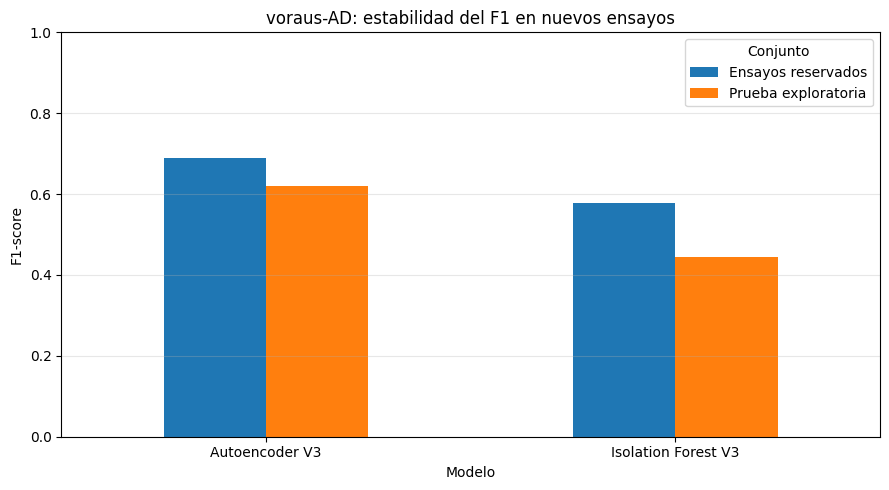

In [80]:

# SECCIÓN 12.19.1 - Comparación de generalización

metricas = [
    "Precision", "Recall", "F1",
    "ROC-AUC", "AP", "FPR"
]

anterior = resultados_v3_test[
    ["Modelo"] + metricas
].copy()

anterior["Conjunto"] = "Prueba exploratoria"

nuevo = resultados_holdout[
    ["Modelo"] + metricas
].copy()

nuevo["Conjunto"] = "Ensayos reservados"

df_generalizacion = pd.concat(
    [anterior, nuevo],
    ignore_index=True
)

print("=== COMPARACIÓN DE GENERALIZACIÓN ===")

display(
    df_generalizacion[
        ["Modelo", "Conjunto"] + metricas
    ].round(4)
)

# Variación de F1 por modelo
tabla_f1 = df_generalizacion.pivot(
    index="Modelo",
    columns="Conjunto",
    values="F1"
)

tabla_f1["Diferencia"] = (
    tabla_f1["Ensayos reservados"]
    - tabla_f1["Prueba exploratoria"]
)

print("\n=== DIFERENCIA DE F1 ===")
display(tabla_f1.round(4))

# Visualización
ax = df_generalizacion.pivot(
    index="Modelo",
    columns="Conjunto",
    values="F1"
).plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title(
    "voraus-AD: estabilidad del F1 en nuevos ensayos"
)
ax.set_ylabel("F1-score")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



### 12.20. Conservación y reproducibilidad del experimento

Se conservan los modelos de detección de anomalías seleccionados, sus respectivos normalizadores, la definición de características temporales y los umbrales de clasificación.

Los modelos se almacenan junto con un archivo de configuración que documenta las arquitecturas, los percentiles de agregación y los resultados obtenidos sobre los ensayos reservados.

Este procedimiento permite reutilizar los modelos sin repetir el entrenamiento, siempre que las señales de entrada mantengan el mismo significado, orden y procedimiento de extracción temporal.


In [81]:
# SECCIÓN 12.20 - Guardado del experimento V3

from pathlib import Path
import joblib
import json

DESTINO_V3 = (
    CARPETA_TRABAJO
    / "dataset_voraus_AD"
    / "resultados_modelos"
    / "version_v3"
)

DESTINO_V3.mkdir(
    parents=True,
    exist_ok=True
)

# 1. Guardar modelo Isolation Forest y escalador
joblib.dump(
    modelo_if_v3,
    DESTINO_V3 / "isolation_forest_v3.joblib"
)

joblib.dump(
    scaler_v3,
    DESTINO_V3 / "scaler_if_v3.joblib"
)

# 2. Guardar Autoencoder y escalador
modelo_ae_v3_final.save(
    str(DESTINO_V3 / "autoencoder_v3.keras")
)

joblib.dump(
    scaler_ae_v3,
    DESTINO_V3 / "scaler_ae_v3.joblib"
)

# 3. Guardar resultados de evaluación
resultados_holdout.to_csv(
    DESTINO_V3 / "metricas_holdout_v3.csv",
    index=False
)

df_generalizacion.to_csv(
    DESTINO_V3 / "comparacion_generalizacion.csv",
    index=False
)

# 4. Configuración reproducible
configuracion = {
    "dataset": "voraus-AD 100 Hz",
    "version": "V3",
    "unidad_evaluacion": "ensayo",
    "ventana_muestras": 100,
    "ventanas_solapadas": False,
    "estadisticas": estadisticas,
    "variables_originales": variables_temporales,
    "columnas_modelo": columnas_v3,
    "isolation_forest": {
        "parametros": configuraciones_v3[
            int(mejor_v3["configuracion"])
        ],
        "percentil": int(mejor_v3["percentil"]),
        "umbral": float(mejor_v3["umbral"])
    },
    "autoencoder": {
        "arquitectura": nombre_mejor_ae_v3,
        "parametros": arquitecturas_v3[
            nombre_mejor_ae_v3
        ],
        "percentil": int(mejor_ae_v3["percentil"]),
        "umbral": float(mejor_ae_v3["umbral"])
    },
    "semilla": 42
}

with open(
    DESTINO_V3 / "configuracion_v3.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        configuracion,
        archivo,
        indent=4,
        ensure_ascii=False
    )

# 5. Verificar archivos
print("=== ARCHIVOS GUARDADOS ===")

for archivo in sorted(DESTINO_V3.iterdir()):
    print(
        archivo.name,
        "|",
        round(archivo.stat().st_size / 1024, 2),
        "KB"
    )

print("\nEXPERIMENTO V3 GUARDADO CORRECTAMENTE")


=== ARCHIVOS GUARDADOS ===
autoencoder_v3.keras | 275.67 KB
comparacion_generalizacion.csv | 0.63 KB
configuracion_v3.json | 6.02 KB
isolation_forest_v3.joblib | 11942.28 KB
metricas_holdout_v3.csv | 0.34 KB
scaler_ae_v3.joblib | 3.98 KB
scaler_if_v3.joblib | 3.98 KB

EXPERIMENTO V3 GUARDADO CORRECTAMENTE



### 12.21. Verificación de reproducibilidad de los modelos V3

Con el objetivo de comprobar la reutilización de los modelos entrenados, se realiza una prueba de recuperación de los artefactos almacenados en Google Drive.

Se cargan los modelos Isolation Forest V3 y Autoencoder V3 junto con sus respectivos normalizadores y el archivo de configuración experimental.

Posteriormente, se generan nuevamente las puntuaciones de anomalía utilizando las características temporales de los ensayos reservados.

Las puntuaciones y clasificaciones obtenidas se comparan con los resultados generados antes de guardar los modelos.

La verificación permite comprobar la consistencia del proceso de inferencia sin repetir el entrenamiento.

Esta prueba constituye una comprobación de reproducibilidad computacional en el entorno actual. No sustituye la validación del desempeño sobre robots o condiciones experimentales diferentes.


In [82]:
# =========================================================
# SECCIÓN 12.21 - Reproducibilidad de modelos V3
# =========================================================

from pathlib import Path
from tensorflow import keras
import numpy as np
import pandas as pd
import joblib
import json

# 1. Carpeta de modelos guardados
RUTA_MODELOS = (
    CARPETA_TRABAJO
    / "dataset_voraus_AD"
    / "resultados_modelos"
    / "version_v3"
)

archivos_requeridos = [
    "autoencoder_v3.keras",
    "isolation_forest_v3.joblib",
    "scaler_ae_v3.joblib",
    "scaler_if_v3.joblib",
    "configuracion_v3.json",
    "metricas_holdout_v3.csv",
    "comparacion_generalizacion.csv"
]

print("=== VERIFICACIÓN DE ARCHIVOS ===")

for nombre in archivos_requeridos:
    ruta = RUTA_MODELOS / nombre

    assert ruta.is_file(), f"Archivo faltante: {nombre}"
    assert ruta.stat().st_size > 0, f"Archivo vacío: {nombre}"

    print("OK:", nombre)

# 2. Recuperar configuración
with open(
    RUTA_MODELOS / "configuracion_v3.json",
    "r",
    encoding="utf-8"
) as archivo:
    config_recuperada = json.load(archivo)

assert config_recuperada["version"] == "V3"
assert config_recuperada["ventana_muestras"] == 100
assert config_recuperada["columnas_modelo"] == columnas_v3

print("\nConfiguración verificada")

# 3. Recuperar modelos y normalizadores
# Cargar únicamente artefactos propios y confiables.
modelo_if_recuperado = joblib.load(
    RUTA_MODELOS / "isolation_forest_v3.joblib"
)

scaler_if_recuperado = joblib.load(
    RUTA_MODELOS / "scaler_if_v3.joblib"
)

modelo_ae_recuperado = keras.models.load_model(
    str(RUTA_MODELOS / "autoencoder_v3.keras"),
    compile=False
)

scaler_ae_recuperado = joblib.load(
    RUTA_MODELOS / "scaler_ae_v3.joblib"
)

print("Modelos recuperados correctamente")

# 4. Preparar características reservadas
X_repro_raw = df_holdout_v3[
    config_recuperada["columnas_modelo"]
].to_numpy(dtype=np.float32)

X_repro_if = scaler_if_recuperado.transform(
    X_repro_raw
).astype(np.float32)

X_repro_ae = scaler_ae_recuperado.transform(
    X_repro_raw
).astype(np.float32)

# 5. Recalcular puntuaciones
scores_if_recuperados = (
    -modelo_if_recuperado.score_samples(X_repro_if)
)

recon_ae_recuperada = modelo_ae_recuperado.predict(
    X_repro_ae,
    batch_size=512,
    verbose=0
)

scores_ae_recuperados = np.mean(
    np.square(X_repro_ae - recon_ae_recuperada),
    axis=1
)

# 6. Comparar con las puntuaciones originales
diferencia_if = np.max(
    np.abs(scores_if_recuperados - scores_holdout_if)
)

diferencia_ae = np.max(
    np.abs(scores_ae_recuperados - scores_holdout_ae)
)

print("\n=== DIFERENCIAS DE PUNTUACIONES ===")
print("Isolation Forest:", diferencia_if)
print("Autoencoder:", diferencia_ae)

np.testing.assert_allclose(
    scores_if_recuperados,
    scores_holdout_if,
    rtol=1e-6,
    atol=1e-7
)

np.testing.assert_allclose(
    scores_ae_recuperados,
    scores_holdout_ae,
    rtol=1e-4,
    atol=1e-6
)

print("\nPUNTUACIONES REPRODUCIDAS CORRECTAMENTE")


=== VERIFICACIÓN DE ARCHIVOS ===
OK: autoencoder_v3.keras
OK: isolation_forest_v3.joblib
OK: scaler_ae_v3.joblib
OK: scaler_if_v3.joblib
OK: configuracion_v3.json
OK: metricas_holdout_v3.csv
OK: comparacion_generalizacion.csv

Configuración verificada
Modelos recuperados correctamente

=== DIFERENCIAS DE PUNTUACIONES ===
Isolation Forest: 0.0
Autoencoder: 0.0

PUNTUACIONES REPRODUCIDAS CORRECTAMENTE


In [83]:
# =========================================================
# SECCIÓN 12.21.1 - Verificación de predicciones
# =========================================================

# 1. Agregar puntuaciones por ensayo
repro_if = agregar_por_ensayo(
    df_holdout_v3,
    scores_if_recuperados,
    percentil=config_recuperada[
        "isolation_forest"
    ]["percentil"]
)

repro_ae = agregar_por_ensayo(
    df_holdout_v3,
    scores_ae_recuperados,
    percentil=config_recuperada[
        "autoencoder"
    ]["percentil"]
)

# 2. Aplicar umbrales guardados
pred_if_recuperadas = (
    repro_if["score_ensayo"].to_numpy()
    >= config_recuperada[
        "isolation_forest"
    ]["umbral"]
).astype(int)

pred_ae_recuperadas = (
    repro_ae["score_ensayo"].to_numpy()
    >= config_recuperada[
        "autoencoder"
    ]["umbral"]
).astype(int)

# 3. Verificar orden y etiquetas
assert np.array_equal(
    repro_if["sample"].to_numpy(),
    ensayos_holdout_if["sample"].to_numpy()
)

assert np.array_equal(
    repro_ae["sample"].to_numpy(),
    ensayos_holdout_ae["sample"].to_numpy()
)

# 4. Comparación exacta de clasificaciones
coincidencia_if = np.array_equal(
    pred_if_recuperadas,
    pred_holdout_if
)

coincidencia_ae = np.array_equal(
    pred_ae_recuperadas,
    pred_holdout_ae
)

print("=== REPRODUCIBILIDAD DE PREDICCIONES ===")

print("Isolation Forest:", coincidencia_if)
print("Autoencoder:", coincidencia_ae)

assert coincidencia_if
assert coincidencia_ae

print("\nRESULTADOS REPRODUCIDOS SIN CAMBIOS")

# 5. Comparar métricas guardadas
metricas_guardadas = pd.read_csv(
    RUTA_MODELOS / "metricas_holdout_v3.csv"
)

display(metricas_guardadas.round(4))

print("\nVERIFICACIÓN V3 COMPLETADA")


=== REPRODUCIBILIDAD DE PREDICCIONES ===
Isolation Forest: True
Autoencoder: True

RESULTADOS REPRODUCIDOS SIN CAMBIOS


,Modelo,Precision,Recall,F1,ROC-AUC,AP,FPR,VN,FP,FN,VP
0,Isolation Forest V3,0.6427,0.5239,0.5772,0.7035,0.6185,0.2009,533,134,219,241
1,Autoencoder V3,0.7572,0.6304,0.6880,0.8372,0.8050,0.1394,574,93,170,290



VERIFICACIÓN V3 COMPLETADA



## 13. Discusión y conclusiones generales

### 13.1. Integración de herramientas de inteligencia artificial

El trabajo permitió desarrollar un flujo de procesamiento, análisis, visualización y evaluación de datos robóticos utilizando herramientas de software libre y la plataforma colaborativa Google Colab.

Se aplicaron Pandas y NumPy para la manipulación de datos, SQLite para el almacenamiento y consulta de información estructurada, Matplotlib y Bokeh para la visualización, Scikit-learn para el aprendizaje automático y TensorFlow/Keras para el desarrollo de redes neuronales.

El proceso se organizó en dos experimentos complementarios, utilizando telemetría del robot cuadrúpedo Unitree Go1 y el dataset etiquetado voraus-AD.

### 13.2. Resultados del experimento Unitree Go1

Se integraron 30 000 registros de telemetría correspondientes a 12 motores del robot cuadrúpedo Unitree Go1, utilizando información procedente de un archivo CSV y un catálogo almacenado en SQLite.

Se analizaron variables operativas como posición, velocidad angular, torque y temperatura, generando visualizaciones descriptivas e interactivas.

Mediante Isolation Forest se identificaron 134 mediciones atípicas en el conjunto de prueba, equivalentes al 1,49 % de los registros evaluados.

El autoencoder desarrollado con TensorFlow/Keras identificó 297 mediciones atípicas, equivalentes al 3,30 %.

Ambos modelos identificaron conjuntos mayormente diferentes de observaciones atípicas, con una sola coincidencia.

Debido a que el dataset no dispone de etiquetas verificadas de fallas, estos resultados se interpretaron como detecciones exploratorias y no como diagnósticos confirmados.

### 13.3. Evaluación mediante el dataset etiquetado voraus-AD

Para complementar el análisis inicial, se incorporó el dataset voraus-AD, compuesto por registros operativos de un manipulador robótico de seis ejes con anomalías inducidas etiquetadas.

Inicialmente se utilizaron 24 características instantáneas correspondientes a posición, velocidad, torque y corriente.

Los modelos mostraron una capacidad limitada para diferenciar los registros nominales y anómalos, especialmente por la elevada tasa de falsas alarmas.

Se identificó que las distribuciones de puntuaciones variaban según las acciones operativas del robot.

Como alternativa, se desarrolló una representación temporal mediante ventanas de 100 muestras, calculando 144 características estadísticas relacionadas con el nivel, la dispersión y la variación de las señales.

### 13.4. Resultados de los modelos temporales V3

Se desarrollaron nuevas versiones de Isolation Forest y del autoencoder utilizando las características temporales.

El Autoencoder V3 presentó los mejores resultados en la evaluación adicional realizada sobre 1 127 ensayos reservados.

Los resultados fueron:

| Métrica | Isolation Forest V3 | Autoencoder V3 |
|---|---:|---:|
| Precision | 0,6427 | 0,7572 |
| Recall | 0,5239 | 0,6304 |
| F1-score | 0,5772 | 0,6880 |
| ROC-AUC | 0,7035 | 0,8372 |
| Average Precision | 0,6185 | 0,8050 |
| Tasa de falsos positivos | 20,09 % | 13,94 % |

El Autoencoder V3 identificó correctamente 290 de los 460 ensayos anómalos y clasificó correctamente 574 de los 667 ensayos nominales. Asimismo, registró 170 falsos negativos y 93 falsos positivos.

En comparación, Isolation Forest V3 identificó correctamente 241 ensayos anómalos y produjo 134 falsas alarmas.

Estos resultados evidencian que, bajo las condiciones experimentales evaluadas, el Autoencoder V3 presentó una mejor capacidad de discriminación y una menor tasa de falsas alarmas que Isolation Forest V3.

Además, la comparación con los modelos basados en características instantáneas sugiere que la incorporación de información temporal favoreció el desempeño del autoencoder.

Las diferencias menores respecto a la ejecución anterior indican cierta variabilidad experimental, por lo que los resultados deben interpretarse considerando las condiciones de entrenamiento y la configuración utilizada.

### 13.5. Limitaciones del estudio

Los resultados deben interpretarse considerando las siguientes limitaciones:

1. El experimento Unitree Go1 no dispone de etiquetas verificadas de anomalías o fallas.
2. El dataset voraus-AD corresponde a un manipulador robótico y no a un cuadrúpedo.
3. Las anomalías de voraus-AD son categorías etiquetadas experimentalmente y no equivalen necesariamente a fallas mecánicas permanentes.
4. Las ventanas pertenecientes a ensayos anómalos heredan la etiqueta del ensayo, sin garantizar la presencia de la anomalía durante toda la ventana.
5. La variable `setting` presenta una asociación completa con las etiquetas dentro de los datos analizados, por lo que podrían existir factores de confusión relacionados con las configuraciones experimentales.
6. Los resultados proceden de un único dataset y no demuestran generalización entre plataformas robóticas diferentes.
7. El conjunto exploratorio de prueba fue consultado durante el desarrollo; la evaluación adicional utilizó ensayos reservados, pero pertenecientes a la misma fuente experimental.

### 13.6. Conclusiones

Primera conclusión. Las herramientas de software libre utilizadas permitieron implementar un flujo de integración, procesamiento, visualización y análisis de datos operativos robóticos mediante Google Colab, integrando Pandas, NumPy, SQLite, Matplotlib, Bokeh, Scikit-learn y TensorFlow/Keras.

Segunda conclusión. La detección de observaciones estadísticamente atípicas no equivale necesariamente a identificar fallas reales. La ausencia de etiquetas verificadas en el experimento Unitree Go1 impidió determinar la precisión de las detecciones realizadas.

Tercera conclusión. La incorporación del dataset etiquetado voraus-AD permitió evaluar cuantitativamente los algoritmos mediante métricas de clasificación y matrices de confusión, identificando limitaciones que no podían determinarse utilizando exclusivamente datos no etiquetados.

Cuarta conclusión. La representación mediante características temporales mejoró el desempeño del autoencoder bajo las condiciones experimentales evaluadas. En la ejecución final sobre 1 127 ensayos reservados, el Autoencoder V3 alcanzó un F1-score de 0,6880 y un ROC-AUC de 0,8372.

Quinta conclusión. El Autoencoder V3 presentó un mejor equilibrio entre detección de anomalías y falsas alarmas que Isolation Forest V3, alcanzando una precisión de 75,72 % y una sensibilidad de 63,04 %. Sin embargo, todavía dejó sin detectar 170 ensayos anómalos y generó 93 falsas alarmas, lo que demuestra la necesidad de continuar mejorando su desempeño antes de considerar aplicaciones operativas críticas.

Sexta conclusión. La evaluación por ensayo, la selección de umbrales mediante validación y la conservación de modelos y escaladores contribuyeron a la trazabilidad del experimento. La recuperación de los modelos permitió verificar la reproducibilidad de las predicciones dentro de cada ejecución. Las pequeñas diferencias entre entrenamientos muestran la conveniencia de estudiar la variabilidad entre semillas y ejecuciones independientes.

### 13.7. Líneas de trabajo futuro

Como continuación se propone:

- Evaluar arquitecturas temporales que procesen secuencias completas, como redes recurrentes o modelos convolucionales unidimensionales.
- Analizar la influencia de las configuraciones experimentales sobre las etiquetas y las características predictoras.
- Incorporar señales de referencia y errores de seguimiento cuando estén disponibles.
- Evaluar la robustez mediante particiones adicionales por ensayo y condición operativa.
- Aplicar la metodología a datasets de robots cuadrúpedos con anotaciones de anomalías verificables.
- Investigar mecanismos de interpretación que permitan relacionar las alertas con las variables operativas responsables.



## Anexo A. Fuentes de datos, atribución y reproducción

### Procedencia de datos

- **Unitree Go1:** las mediciones provienen de la secuencia `running.bag` del conjunto **Leg-KILO**. Fuente: [legkilo-dataset](https://github.com/ouguangjun/legkilo-dataset). Ou, G., Li, D., y Li, H. (2024), *Leg-KILO: Robust Kinematic-Inertial-Lidar Odometry for Dynamic Legged Robots*, IEEE Robotics and Automation Letters, 9(10), 8194–8201, [DOI: 10.1109/LRA.2024.3440730](https://doi.org/10.1109/LRA.2024.3440730). El catálogo de motor, pata y articulación se preparó para este trabajo; las mediciones originales pertenecen a su fuente. No se ha confirmado una licencia explícita de redistribución de los datos experimentales.
- **voraus-AD:** [repositorio del dataset](https://github.com/vorausrobotik/voraus-ad-dataset). En el estudio se empleó `voraus-ad-dataset-100hz.parquet` con etiquetas por ensayo. Antes de redistribuir datos o derivados deben respetarse sus condiciones de licencia.

### Cómo reproducir los experimentos

1. Abrir este notebook en **Google Colab** y ejecutar las celdas en el orden presentado. Para Unitree Go1, seleccionar `MODO_EJECUCION = "CSV"` o `"ROS"` y proporcionar el archivo correspondiente (`unitree_go1_telemetria_30000.csv` o `running.bag`) obtenido legítimamente.
2. Para voraus-AD, disponer del Parquet original y las particiones `voraus_entrenamiento.csv`, `voraus_validacion.csv` y `voraus_prueba.csv` generadas por el procedimiento de preparación. Configurar `CARPETA_TRABAJO` (sección 12.1) según la ubicación de los archivos en Drive.
3. La ejecución integral de las secciones de entrenamiento puede consumir tiempo y sobrescribir modelos o resultados; trabajar en una carpeta de experimentos independiente. Las rutas y archivos externos no se incluyen dentro de este `.ipynb`.
4. Verificación de reproducibilidad y resultados experimentales. La evaluación de los modelos V3 se realizó sobre 1 127 ensayos reservados, utilizando 11 664 ventanas temporales y 144 características.

En una primera evaluación, el Autoencoder V3 obtuvo un F1-score de 0,694935 y un ROC-AUC de 0,837986, mientras que Isolation Forest V3 alcanzó un F1-score de 0,577246 y un ROC-AUC de 0,703452.

Posteriormente, se realizó una prueba independiente en Google Colab, reconstruyendo las características desde el dataset original y recuperando los modelos previamente entrenados. Esta prueba reprodujo las matrices de confusión y las métricas de la primera evaluación, con una diferencia numérica máxima de 5,55 × 10⁻¹⁷, verificando la reproducibilidad de la inferencia.

Finalmente, se ejecutó nuevamente el notebook completo. En esta ejecución, Isolation Forest V3 mantuvo un F1-score de 0,5772 y un ROC-AUC de 0,7035, mientras que el Autoencoder V3 obtuvo un F1-score de 0,6880 y un ROC-AUC de 0,8372.

La pequeña variación observada en el Autoencoder V3 entre ejecuciones requiere considerar la variabilidad del entrenamiento neuronal. La reproducción exacta de las predicciones de los modelos guardados no implica que dos entrenamientos independientes produzcan necesariamente resultados idénticos.

### Limitaciones

Las anomalías del Unitree Go1 no cuentan con etiquetas verificadas. Las anomalías de voraus-AD están etiquetadas por ensayo y pueden depender de condiciones experimentales (`setting`), por lo que las métricas no deben interpretarse como exactitud garantizada ante fallas mecánicas reales ni extrapolarse entre plataformas.
